# SecondSite: Finding the Rest of a Fix (complete reproduction notebook)

This notebook reproduces every CPU result in the SecondSite paper from the competition data and the public upstream repositories:

1. clones fastapi, rich, requests and httpx (full history; only first-parent commits before each task's base commit are used);
2. builds the benchmark: the 129 public tasks (D1) plus earlier fix commits (D3), with gold sites from the patch hunks;
3. ranks every candidate with all baselines and curveball nulls, and runs the H1/H2 statistics;
4. trains and evaluates **SecondSite-LTR** (LightGBM LambdaRank) with task-grouped 5-fold CV, leave-one-repository-out and ablations;
5. scores the Gemma 4 31B reranker (its GPU kernel `secondsite-rerank` is attached as an input) against the same gold, with
   bootstrap CIs and a split by task date around the model's January 2025 knowledge cutoff;
6. regenerates every figure.

The GPU experiments run as separate Kaggle kernels on 4x L4 (`secondsite-rerank`, `secondsite-p4-probe`, `secondsite-harness-ab`);
this notebook only reads their outputs, so it needs no GPU.

**Settings:** CPU, Internet ON (for `git clone` and `pip install dulwich`), competition data `gemma-4-developer-agent` attached. Runtime is about 40-60 minutes on Kaggle CPU.


In [1]:
import os, subprocess, sys, json, glob, time
os.makedirs('secondsite', exist_ok=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dulwich', 'rank_bm25'], check=False)
COMP = next(p for p in ['/kaggle/input/competitions/gemma-4-developer-agent', '/kaggle/input/gemma-4-developer-agent'] if os.path.exists(p))
TASKS = f'{COMP}/tasks.jsonl'
# folders that actually hold <repo>_<commit>.json graphs and .npz embeddings (robust to nesting)
GRAPHS = os.path.dirname(sorted(glob.glob(f'{COMP}/graphs/**/*.json', recursive=True))[0])
EMB = os.path.dirname(sorted(glob.glob(f'{COMP}/embeddings/**/*.npz', recursive=True))[0])
print('graphs:', GRAPHS, len(glob.glob(GRAPHS + '/*.json')), '| embeddings:', EMB, len(glob.glob(EMB + '/*.npz')))
W = '/tmp/work'; os.makedirs(W, exist_ok=True)  # heavy intermediates stay out of /kaggle/working
print(COMP, len(open(TASKS).readlines()), 'tasks')

graphs: /kaggle/input/competitions/gemma-4-developer-agent/graphs 127 | embeddings: /kaggle/input/competitions/gemma-4-developer-agent/embeddings 127
/kaggle/input/competitions/gemma-4-developer-agent 129 tasks


## 1. Source modules

In [2]:
%%writefile secondsite/ss_common.py
"""SecondSite common utilities: AST site mapper, host-id normalisation, diff-to-site mapping.

Same mapper is used for history mining and for gold-site labelling (consistency by construction).
"""
import ast
import difflib
import re

TEST_RE = re.compile(r"(^|/)(tests?|testing)/|(^|/)test_[^/]*\.py$|_test\.py$|(^|/)conftest\.py$")
DOCS_RE = re.compile(r"(^|/)(docs|docs_src|doc|examples?|scripts|benchmarks?)/")


def is_test(path):
    return bool(TEST_RE.search(path))


def is_docs(path):
    return bool(DOCS_RE.search(path))


def eligible_path(path):
    return path.endswith(".py") and not is_test(path) and not is_docs(path)


def module_of(path):
    """repo path -> dotted module in the hosts' schema (src/ prefix stripped, __init__ collapsed)."""
    p = path[:-3] if path.endswith(".py") else path
    for pre in ("src/",):
        if p.startswith(pre):
            p = p[len(pre):]
    p = p.replace("/", ".")
    if p.endswith(".__init__"):
        p = p[: -len(".__init__")]
    return p


class SiteMap:
    """Intervals of def/class sites for one file version. Lines inside nested functions map to the
    outermost function whose parents are only classes (matches the hosts' node granularity)."""

    __slots__ = ("intervals", "ok", "names", "nlines", "texts")

    def __init__(self, src, keep_text=False):
        self.intervals = []  # (start, end, qualname)
        self.names = set()
        self.texts = {} if keep_text else None
        lines = src.splitlines()
        self.nlines = len(lines)
        try:
            tree = ast.parse(src)
            self.ok = True
        except (SyntaxError, ValueError, MemoryError, RecursionError):
            self.ok = False
            return

        def visit(node, prefix):
            for ch in ast.iter_child_nodes(node):
                if isinstance(ch, (ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
                    q = prefix + ch.name
                    start = min([ch.lineno] + [d.lineno for d in getattr(ch, "decorator_list", [])])
                    end = getattr(ch, "end_lineno", ch.lineno) or ch.lineno
                    self.intervals.append((start, end, q))
                    self.names.add(q)
                    if keep_text:
                        self.texts[q] = "\n".join(lines[start - 1:end])
                    if isinstance(ch, ast.ClassDef):
                        visit(ch, q + ".")
                    # do not descend into functions: nested defs collapse into the enclosing function
                elif not isinstance(ch, (ast.FunctionDef, ast.AsyncFunctionDef)):
                    # e.g. if/try blocks at module or class level can contain defs
                    if isinstance(ch, (ast.If, ast.Try, ast.With, ast.For, ast.While)) or type(ch).__name__ == "TryStar":
                        visit(ch, prefix)

        visit(tree, "")
        self.intervals.sort()

    def site_of(self, line):
        best = None
        for s, e, q in self.intervals:
            if s > line:
                break
            if s <= line <= e:
                if best is None or s >= best[0]:
                    best = (s, e, q)
        return best[2] if best else "<module>"


def changed_lines(a_lines, b_lines, skip_blank=True):
    """Return (old_changed_line_numbers, new_changed_line_numbers), 1-based. Whitespace-only lines are ignored."""
    sm = difflib.SequenceMatcher(None, a_lines, b_lines, autojunk=len(a_lines) + len(b_lines) > 12000)
    old, new = [], []
    for tag, i1, i2, j1, j2 in sm.get_opcodes():
        if tag in ("replace", "delete"):
            old.extend(i + 1 for i in range(i1, i2) if not (skip_blank and not a_lines[i].strip()))
        if tag in ("replace", "insert"):
            new.extend(j + 1 for j in range(j1, j2) if not (skip_blank and not b_lines[j].strip()))
    return old, new


def hunk_changed_lines(hunks, skip_blank=True):
    """Exact changed line numbers from parsed hunks (ostart, olen, lines, nstart): ('-' old lines, '+' new lines)."""
    old, new = [], []
    for h in hunks:
        ostart, olen, lines = h[0], h[1], h[2]
        nstart = h[3] if len(h) > 3 else ostart
        o = ostart if olen > 0 else ostart + 1
        n = nstart if (len(h) > 3 and h[4] > 0) or len(h) <= 3 else nstart + 1
        for ln in lines:
            tag, body = ln[:1], ln[1:]
            if tag == " ":
                o += 1
                n += 1
            elif tag == "-":
                if not (skip_blank and not body.strip()):
                    old.append(o)
                o += 1
            elif tag == "+":
                if not (skip_blank and not body.strip()):
                    new.append(n)
                n += 1
    return old, new


def sites_for_change(path, old_src, new_src, cache_get=None):
    """Map a file change to {site_qualname: changed_line_count}. old_src/new_src may be None (add/delete)."""
    a = old_src.splitlines() if old_src is not None else []
    b = new_src.splitlines() if new_src is not None else []
    old_ln, new_ln = changed_lines(a, b)
    out = {}
    smo = cache_get(old_src) if (cache_get and old_src is not None) else (SiteMap(old_src) if old_src is not None else None)
    smn = cache_get(new_src) if (cache_get and new_src is not None) else (SiteMap(new_src) if new_src is not None else None)
    fail = (smo is not None and not smo.ok) or (smn is not None and not smn.ok)
    for ln in old_ln:
        q = smo.site_of(ln) if smo is not None and smo.ok else "<module>"
        out[q] = out.get(q, 0) + 1
    for ln in new_ln:
        q = smn.site_of(ln) if smn is not None and smn.ok else "<module>"
        out[q] = out.get(q, 0) + 1
    return out, fail


def host_id(path, qualname):
    m = module_of(path)
    return m if qualname == "<module>" else f"{m}.{qualname}"


IDENT_RE = re.compile(r"[A-Za-z_][A-Za-z0-9_]*")
CAMEL_RE = re.compile(r"[A-Z]?[a-z]+|[A-Z]+(?![a-z])|\d+")
STOP = set("self cls return def class if else elif for while in not and or is none true false import from as with try except finally raise pass yield lambda async await assert del global nonlocal print str int list dict set tuple bool len isinstance".split())


def tokens(text):
    out = []
    for t in IDENT_RE.findall(text or ""):
        tl = t.lower()
        if tl in STOP or len(tl) < 2:
            continue
        out.append(tl)
        if "_" in t or any(c.isupper() for c in t[1:]):
            for p in re.split(r"_+", t):
                for s in CAMEL_RE.findall(p):
                    s = s.lower()
                    if len(s) > 2 and s not in STOP and s != tl:
                        out.append(s)
    return out


def apply_unified_patch(old_text, hunks):
    """Apply parsed hunks [(old_start, old_len, lines)] to old_text; lines are raw diff lines (' ', '-', '+')."""
    a = old_text.splitlines() if old_text is not None else []
    out, pos = [], 0
    for h in hunks:
        ostart, olen, lines = h[0], h[1], h[2]
        idx = max(ostart - 1, 0) if olen > 0 else ostart  # when olen==0, insertion after line ostart
        out.extend(a[pos:idx])
        pos = idx
        for ln in lines:
            if ln.startswith("\\"):
                continue
            tag, body = ln[:1], ln[1:]
            if tag == " ":
                out.append(body)
                pos += 1
            elif tag == "-":
                pos += 1
            elif tag == "+":
                out.append(body)
    out.extend(a[pos:])
    return "\n".join(out) + "\n"


HUNK_RE = re.compile(r"^@@ -(\d+)(?:,(\d+))? \+(\d+)(?:,(\d+))? @@")


def parse_patch(patch):
    """Unified git diff -> list of {old_path, new_path, hunks}."""
    files, cur, hunk = [], None, None
    lines = patch.splitlines()
    remaining = 0  # old+new lines still expected in the current hunk
    for i, line in enumerate(lines):
        if line.startswith("diff --git "):
            cur, hunk = None, None
            continue
        nxt = lines[i + 1] if i + 1 < len(lines) else ""
        if line.startswith("--- ") and nxt.startswith("+++ ") and remaining <= 0:
            p = line[4:].split("\t")[0].strip()
            q = nxt[4:].split("\t")[0].strip()
            cur = {"old_path": None if p == "/dev/null" else re.sub(r"^a/", "", p),
                   "new_path": None if q == "/dev/null" else re.sub(r"^b/", "", q), "hunks": []}
            files.append(cur)
            hunk = None
            continue
        if line.startswith("+++ ") and hunk is None:
            continue
        if cur is None:
            continue
        m = HUNK_RE.match(line)
        if m:
            remaining = int(m.group(2) if m.group(2) is not None else 1) + int(m.group(4) if m.group(4) is not None else 1)
            hunk = (int(m.group(1)), int(m.group(2) if m.group(2) is not None else 1), [],
                    int(m.group(3)), int(m.group(4) if m.group(4) is not None else 1))
            cur["hunks"].append(hunk)
            continue
        if hunk is not None and remaining > 0 and (line[:1] in (" ", "-", "+") or line == ""):
            tag = line[:1] if line else " "
            remaining -= 2 if tag == " " else 1
            hunk[2].append(line if line else " ")
            continue
        if hunk is not None and line.startswith("\\"):
            hunk[2].append(line)
            continue
    return files
    # legacy path below (unreachable)
    for line in []:
        m = HUNK_RE.match(line)
        if m:
            hunk = (int(m.group(1)), int(m.group(2) if m.group(2) is not None else 1), [],
                    int(m.group(3)), int(m.group(4) if m.group(4) is not None else 1))
            cur["hunks"].append(hunk)
            continue
        if hunk is not None and (line[:1] in (" ", "-", "+", "\\") or line == ""):
            hunk[2].append(line if line else " ")
    return files


Writing secondsite/ss_common.py


In [3]:
%%writefile secondsite/ss_mine.py
"""Mine first-parent .py transactions with function-level change sets (dulwich; no git binary needed).

Usage: python -I ss_mine.py REPO_DIR OUT.pkl [HEAD_SHA]
"""
import os
import pickle
import re
import sys
import tarfile
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import site as _site
_us = _site.getusersitepackages()
if _us not in sys.path:
    sys.path.append(_us)
from dulwich.repo import Repo
from dulwich.diff_tree import tree_changes

from ss_common import SiteMap, eligible_path, host_id, sites_for_change, changed_lines

FIX_RE = re.compile(r"(?i)\b(fix|fixes|fixed|bug|issue)\b|#\d+")


def extract(tgz, dest):
    os.makedirs(dest, exist_ok=True)
    with tarfile.open(tgz, "r:gz") as tf:
        tf.extractall(dest, filter="data")
    # find the dir containing .git
    for root, dirs, files in os.walk(dest):
        if ".git" in dirs:
            return root
    raise RuntimeError("no .git found in " + tgz)


class Miner:
    def __init__(self, repo_dir):
        self.repo = Repo(repo_dir)
        self.store = self.repo.object_store
        self._sm = {}
        self._txt = {}

    def blob_text(self, sha):
        t = self._txt.get(sha)
        if t is None:
            t = self.store[sha].data.decode("utf-8", errors="replace")
            if len(self._txt) > 20000:
                self._txt.clear()
            self._txt[sha] = t
        return t

    def sitemap(self, sha, keep_text=False):
        key = (sha, keep_text)
        sm = self._sm.get(key)
        if sm is None:
            sm = SiteMap(self.blob_text(sha), keep_text=keep_text)
            if len(self._sm) > 30000:
                self._sm.clear()
            self._sm[key] = sm
        return sm

    def first_parent_chain(self, head):
        chain, c = [], self.repo[head]
        while True:
            chain.append(c)
            if not c.parents:
                break
            try:
                c = self.repo[c.parents[0]]
            except KeyError:
                break
        chain.reverse()
        return chain

    def commit_change(self, c):
        """Function-level change set of commit c vs its first parent (eligible .py files only)."""
        parent_tree = self.repo[c.parents[0]].tree if c.parents else None
        funcs, files, fail, lines_by_func = {}, [], 0, {}
        for ch in tree_changes(self.store, parent_tree, c.tree):
            old_e, new_e = ch.old, ch.new
            op = old_e.path.decode("utf-8", "replace") if (old_e is not None and old_e.path) else None
            np_ = new_e.path.decode("utf-8", "replace") if (new_e is not None and new_e.path) else None
            path = np_ or op
            if not path or not eligible_path(path):
                continue
            files.append(path)
            old_sha = old_e.sha if (old_e is not None and op) else None
            new_sha = new_e.sha if (new_e is not None and np_) else None
            a = self.blob_text(old_sha) if old_sha else None
            b = self.blob_text(new_sha) if new_sha else None
            al = a.splitlines() if a is not None else []
            bl = b.splitlines() if b is not None else []
            old_ln, new_ln = changed_lines(al, bl)
            smo = self.sitemap(old_sha) if old_sha else None
            smn = self.sitemap(new_sha) if new_sha else None
            if (smo is not None and not smo.ok) or (smn is not None and not smn.ok):
                fail += 1
            for ln in old_ln:
                q = smo.site_of(ln) if smo is not None and smo.ok else "<module>"
                hid = host_id(op or path, q)
                lines_by_func[hid] = lines_by_func.get(hid, 0) + 1
                funcs.setdefault(hid, (op or path, q))
            for ln in new_ln:
                q = smn.site_of(ln) if smn is not None and smn.ok else "<module>"
                hid = host_id(np_ or path, q)
                lines_by_func[hid] = lines_by_func.get(hid, 0) + 1
                funcs.setdefault(hid, (np_ or path, q))
        return funcs, files, fail, lines_by_func

    def inventory(self, commit_sha, keep_text=True):
        """All eligible def/class sites at a commit: host_id -> (path, qualname, start, end, text)."""
        c = self.repo[commit_sha.encode() if isinstance(commit_sha, str) else commit_sha]
        inv = {}
        for e in self.store.iter_tree_contents(c.tree):
            path = e.path.decode("utf-8", "replace")
            if not eligible_path(path):
                continue
            sm = self.sitemap(e.sha, keep_text=keep_text)
            if not sm.ok:
                continue
            for s, en, q in sm.intervals:
                inv[host_id(path, q)] = (path, q, s, en, sm.texts.get(q, "") if sm.texts is not None else "")
        return inv

    def file_text_at(self, commit_sha, path):
        from dulwich.object_store import tree_lookup_path
        try:
            cs = commit_sha.encode() if isinstance(commit_sha, str) else commit_sha
            _, sha = tree_lookup_path(self.store.__getitem__, self.repo[cs].tree, path.encode())
            return self.blob_text(sha), sha
        except KeyError:
            return None, None


def mine(repo_dir, head=None, log=print):
    m = Miner(repo_dir)
    head = head.encode() if isinstance(head, str) else (head or m.repo.head())
    chain = m.first_parent_chain(head)
    t0 = time.time()
    txns = []
    for i, c in enumerate(chain):
        funcs, files, fail, lbf = m.commit_change(c)
        if not files:
            continue
        msg = c.message.decode("utf-8", "replace")
        keys = {h for h, (p, q) in funcs.items() if q != "<module>"}
        txns.append({
            "sha": c.id.decode(), "ts": c.commit_time, "chain_pos": i,
            "fixlike": bool(FIX_RE.search(msg)), "is_merge": len(c.parents) > 1,
            "funcs": frozenset(keys), "files": tuple(sorted(set(files))),
            "lines": {k: v for k, v in lbf.items() if k in keys},
            "n_files": len(set(files)), "n_funcs": len(keys), "map_fail": fail,
            "filtered": len(set(files)) > 10 or len(keys) > 30,
        })
        if (len(txns) % 500) == 0:
            log(f"  {len(txns)} txns, chain {i}/{len(chain)}, {time.time()-t0:.0f}s")
    sha_to_pos = {c.id.decode(): i for i, c in enumerate(chain)}
    return {"txns": txns, "chain": [c.id.decode() for c in chain], "sha_to_pos": sha_to_pos, "head": head.decode()}


if __name__ == "__main__":
    repo_dir, out = sys.argv[1], sys.argv[2]
    head = sys.argv[3] if len(sys.argv) > 3 else None
    t = time.time()
    res = mine(repo_dir, head)
    pickle.dump(res, open(out, "wb"))
    tx = res["txns"]
    print(f"mined {len(tx)} .py transactions over {len(res['chain'])} first-parent commits in {time.time()-t:.0f}s;"
          f" filtered {sum(x['filtered'] for x in tx)}; map_fail {sum(x['map_fail'] for x in tx)}; fixlike {sum(x['fixlike'] for x in tx)}")


Writing secondsite/ss_mine.py


In [4]:
%%writefile secondsite/ss_build.py
"""Build SecondSite items (D1 competition tasks, D3-comp earlier fix commits) and per-base history windows.

Usage: python -I ss_build.py REPO_SHORT UPSTREAM_DIR TASKS_JSONL OUT_DIR [--d3 150] [--wmax 3000]
Writes OUT_DIR/<repo>_build.pkl with: txns (sha -> txn), windows (cut_sha -> [txn shas oldest..newest]),
items (list), inventories (cut_sha -> {host_id: (path, qual, start, end, text)}).
"""
import argparse
import json
import os
import pickle
import sys
import time

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from ss_mine import Miner, FIX_RE  # noqa: E402  (adds user site for dulwich)
from ss_common import eligible_path, host_id, parse_patch, apply_unified_patch, SiteMap, changed_lines, hunk_changed_lines  # noqa: E402
import re as _re
FIXKW_RE = _re.compile(r"(?i)\b(fix|fixes|fixed|fixing|bug|bugs|bugfix|issue|regression)\b")


def txn_of(m, cache, c):
    sha = c.id.decode()
    if sha in cache:
        return cache[sha]
    try:
        funcs, files, fail, lbf = m.commit_change(c)
    except KeyError:  # parent object missing (shallow-clone boundary): treat the commit as outside history
        cache[sha] = None
        return None
    if not files:
        cache[sha] = None
        return None
    keys = frozenset(h for h, (p, q) in funcs.items() if q != "<module>")
    msg = c.message.decode("utf-8", "replace")
    first_line = msg.strip().splitlines()[0] if msg.strip() else ""
    # keyword fix flag ignores merge boilerplate ("Merge pull request #N from ...") and PR numbers
    kw_text = msg if not first_line.lower().startswith("merge pull request") else "\n".join(msg.strip().splitlines()[1:])
    t = {"sha": sha, "ts": c.commit_time, "fixlike": bool(FIX_RE.search(msg)), "fixkw": bool(FIXKW_RE.search(kw_text)),
         "is_revert": first_line.lower().startswith("revert"), "is_merge": len(c.parents) > 1,
         "funcs": keys, "files": tuple(sorted(set(files))), "lines": {k: v for k, v in lbf.items() if k in keys},
         "n_files": len(set(files)), "n_funcs": len(keys), "map_fail": fail,
         "filtered": len(set(files)) > 10 or len(keys) > 30, "parent": c.parents[0].decode() if c.parents else None}
    cache[sha] = t
    return t


def window_for(m, cache, cut_sha, wmax):
    """Last wmax .py transactions on the first-parent chain ending at cut_sha (inclusive), oldest first."""
    out, c, depth = [], m.repo[cut_sha.encode()], 0
    while True:
        t = txn_of(m, cache, c)
        if t is not None:
            out.append(t["sha"])
            if len(out) >= wmax:
                break
        depth += 1
        if not c.parents:
            break
        try:
            c = m.repo[c.parents[0]]
        except KeyError:
            break
    out.reverse()
    return out, depth


def context_ok(old_text, hunks):
    a = old_text.splitlines() if old_text is not None else []
    bad = 0
    for h in hunks:
        ostart, olen, lines = h[0], h[1], h[2]
        pos = max(ostart - 1, 0)
        for ln in lines:
            if ln[:1] in (" ", "-"):
                if pos >= len(a) or a[pos].rstrip() != ln[1:].rstrip():
                    bad += 1
                pos += 1
    return bad


def gold_sites_from_patch(m, base, patch, audit=None):
    sites, lines, new_sites, files = {}, {}, set(), set()
    for f in parse_patch(patch):
        path = f["new_path"] or f["old_path"]
        if not path or not eligible_path(path):
            continue
        old_text = None
        if f["old_path"]:
            old_text, _ = m.file_text_at(base, f["old_path"])
            if audit is not None:
                audit["ctx_bad"] = audit.get("ctx_bad", 0) + (context_ok(old_text, f["hunks"]) if old_text is not None else 999)
        new_text = None if f["new_path"] is None else apply_unified_patch(old_text, f["hunks"])
        old_ln, new_ln = hunk_changed_lines(f["hunks"])  # exact patch alignment; whitespace-only lines skipped
        smo = SiteMap(old_text) if old_text is not None else None
        smn = SiteMap(new_text) if new_text is not None else None
        files.add(path)
        for ln in old_ln:
            q = smo.site_of(ln) if smo is not None and smo.ok else "<module>"
            h = host_id(f["old_path"] or path, q)
            lines[h] = lines.get(h, 0) + 1
            sites[h] = (f["old_path"] or path, q)
        for ln in new_ln:
            q = smn.site_of(ln) if smn is not None and smn.ok else "<module>"
            h = host_id(path, q)
            lines[h] = lines.get(h, 0) + 1
            sites[h] = (path, q)
    sites = {h: v for h, v in sites.items() if v[1] != "<module>"}
    return sites, {h: lines[h] for h in sites}, files


def make_items(dataset, task_id, cut_sha, sites, lines, inv, max_anchors=4, extra=None):
    rank_sites = sorted([h for h in sites if h in inv], key=lambda h: (-lines.get(h, 0), h))
    items = []
    if len(rank_sites) < 2:
        return items, rank_sites
    for k, a in enumerate(rank_sites[:max_anchors]):
        tg = [h for h in rank_sites if h != a]
        it = {"dataset": dataset, "task_id": task_id, "cut": cut_sha, "anchor": a, "anchor_rank": k,
              "targets": tg, "all_sites": sorted(sites), "rankable_sites": rank_sites,
              "anchor_file": inv[a][0], "target_files": sorted({inv[t][0] for t in tg}),
              "fix_lines": sum(lines.values())}
        if extra:
            it.update(extra)
        items.append(it)
    return items, rank_sites


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("repo")
    ap.add_argument("upstream")
    ap.add_argument("tasks")
    ap.add_argument("out")
    ap.add_argument("--d3", type=int, default=150)
    ap.add_argument("--wmax", type=int, default=3000)
    a = ap.parse_args()
    t0 = time.time()
    m = Miner(a.upstream)
    rows = [json.loads(l) for l in open(a.tasks, encoding="utf-8")]
    rows = [r for r in rows if r["repo"].split("/")[1] == a.repo]
    cache, windows, inventories, items, audit = {}, {}, {}, [], []
    # ---- D1 ----
    for r in rows:
        base = r["base_commit"]
        present = base.encode() in m.repo.object_store
        if not present:
            audit.append({"task_id": r["instance_id"], "present": False})
            continue
        if base not in windows:
            windows[base], depth = window_for(m, cache, base, a.wmax)
        if base not in inventories:
            inventories[base] = m.inventory(base)
        pa = {}
        sites, lines, files = gold_sites_from_patch(m, base, r["patch"], pa)
        its, rank_sites = make_items("D1", r["instance_id"], base, sites, lines, inventories[base],
                                     extra={"created_at": r["created_at"], "repo": a.repo})
        # ancestry / leakage audit: no window txn may be the gold fix; all window txns are first-parent ancestors (by construction)
        win_ts_max = max((cache[s]["ts"] for s in windows[base]), default=0)
        audit.append({"task_id": r["instance_id"], "present": True, "n_window": len(windows[base]),
                      "n_sites": len(sites), "n_rankable": len(rank_sites), "n_files": len(files),
                      "base_ts": m.repo[base.encode()].commit_time, "win_ts_max": win_ts_max,
                      "eligible": len(rank_sites) >= 2, "fix_lines": sum(lines.values()), "ctx_bad": pa.get("ctx_bad", 0),
                      "sites": sorted(sites), "rankable": rank_sites})
        items.extend(its)
        print(f"D1 {r['instance_id']}: window {len(windows[base])}, sites {len(sites)}, rankable {len(rank_sites)}, items {len(its)}  [{time.time()-t0:.0f}s]", flush=True)
    # ---- D3-comp: fix-like first-parent txns older than the earliest D1 base ----
    present_bases = [r["base_commit"] for r in rows if r["base_commit"].encode() in m.repo.object_store]
    if present_bases and a.d3 > 0:
        earliest = min(present_bases, key=lambda b: m.repo[b.encode()].commit_time)
        d1_patch_files = set()
        chain, c = [], m.repo[earliest.encode()]
        while c.parents:
            try:
                c = m.repo[c.parents[0]]
            except KeyError:  # shallow-clone boundary
                break
            chain.append(c)
            if len(chain) > 6000:
                break
        n = 0
        for c in chain:  # newest first, strictly older than the earliest base
            t = txn_of(m, cache, c)
            if t is None or not t["fixkw"] or t["is_revert"] or t["filtered"] or t["n_funcs"] < 2 or not t["parent"]:
                continue
            par = t["parent"]
            if par not in inventories:
                inventories[par] = m.inventory(par)
            inv = inventories[par]
            sites = {h: (None, None) for h in t["funcs"]}
            its, rank_sites = make_items("D3", f"{a.repo}@{t['sha'][:10]}", par, sites, t["lines"], inv,
                                         extra={"created_at": t["ts"], "repo": a.repo, "fix_sha": t["sha"]})
            if not its:
                continue
            if par not in windows:
                windows[par], _ = window_for(m, cache, par, a.wmax)
            items.extend(its)
            n += 1
            if n % 25 == 0:
                print(f"D3 {n} commits, {len(items)} items  [{time.time()-t0:.0f}s]", flush=True)
            if n >= a.d3:
                break
    txns = {s: cache[s] for w in windows.values() for s in w}
    os.makedirs(a.out, exist_ok=True)
    pickle.dump({"repo": a.repo, "txns": txns, "windows": windows, "items": items, "inventories": inventories,
                 "audit": audit}, open(os.path.join(a.out, f"{a.repo}_build.pkl"), "wb"))
    d1 = [x for x in items if x["dataset"] == "D1"]
    d3 = [x for x in items if x["dataset"] == "D3"]
    print(f"DONE {a.repo}: D1 tasks {len(rows)}, eligible {sum(1 for x in audit if x.get('eligible'))}, D1 items {len(d1)}, "
          f"D3 commits {len({x['task_id'] for x in d3})}, D3 items {len(d3)}, txns {len(txns)}, {time.time()-t0:.0f}s", flush=True)


if __name__ == "__main__":
    main()


Writing secondsite/ss_build.py


In [5]:
%%writefile secondsite/ss_rank.py
"""Rank candidates for every SecondSite item with all rankers + curveball nulls; write per-item results.

Usage: python -I ss_rank.py BUILD_DIR GRAPHS_DIR TASKS_JSONL OUT_DIR [--B1 100] [--B3 50] [--procs 10]
"""
import argparse
import hashlib
import json
import math
import os
import pickle
import random
import re
import sys
import time
from collections import Counter, defaultdict
from multiprocessing import Pool

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from ss_common import tokens  # noqa: E402

K_RRF = 60
WS = (25, 100, 400, 3000)
CALL_RE = re.compile(r"\b([A-Za-z_][A-Za-z0-9_]*)\s*\(")

G = {}  # per-process globals


def seed_of(*parts):
    return int(hashlib.sha256("|".join(map(str, parts)).encode()).hexdigest()[:12], 16)


# ---------------- static text features per cut ----------------
class CutIndex:
    def __init__(self, inv):
        self.ids = sorted(inv)
        self.path = {h: inv[h][0] for h in self.ids}
        self.qual = {h: inv[h][1] for h in self.ids}
        self.start = {h: inv[h][2] for h in self.ids}
        self.text = {h: inv[h][4] for h in self.ids}
        self.tok = {h: Counter(tokens(self.text[h])) for h in self.ids}
        self.dl = {h: sum(self.tok[h].values()) for h in self.ids}
        self.avgdl = (sum(self.dl.values()) / max(1, len(self.ids))) or 1.0
        df = Counter()
        for h in self.ids:
            df.update(self.tok[h].keys())
        N = len(self.ids)
        self.idf = {t: math.log(1 + (N - n + 0.5) / (n + 0.5)) for t, n in df.items()}
        self.simple = {h: self.qual[h].split(".")[-1] for h in self.ids}
        self.calls = {h: set(CALL_RE.findall(self.text[h])) for h in self.ids}
        self.by_simple = defaultdict(list)
        for h in self.ids:
            self.by_simple[self.simple[h]].append(h)

    def bm25(self, qtoks, cands, k1=1.2, b=0.75):
        q = Counter(qtoks)
        sc = {}
        for h in cands:
            tf, dl, s = self.tok[h], self.dl[h], 0.0
            for t, qn in q.items():
                f = tf.get(t)
                if f:
                    s += self.idf.get(t, 0) * f * (k1 + 1) / (f + k1 * (1 - b + b * dl / self.avgdl))
            sc[h] = s
        return sc


def order(cands, key):
    return sorted(cands, key=key)


def static_rankings(ci, a, issue_text=None):
    cands = [h for h in ci.ids if h != a]
    bm = ci.bm25(list(ci.tok[a].elements()), cands)
    lex = order(cands, lambda h: (-bm[h], h))
    lex_pos = {h: i for i, h in enumerate(lex)}
    pa, qa, sa = ci.path[a], ci.qual[a], ci.start[a]
    da = pa.rsplit("/", 1)[0] if "/" in pa else ""

    def tier_then_lex(tier):
        return order(cands, lambda h: (tier(h), lex_pos[h]))

    # B1 same-file proximity, then same directory, then lexical
    def t_b1(h):
        if ci.path[h] == pa:
            return (0, abs(ci.start[h] - sa))
        d = ci.path[h].rsplit("/", 1)[0] if "/" in ci.path[h] else ""
        return (1 if d == da else 2, 0)
    b1 = order(cands, lambda h: (t_b1(h), lex_pos[h]))
    # B2 containment
    cls = qa.rsplit(".", 1)[0] if "." in qa else None

    def t_b2(h):
        if ci.path[h] != pa:
            return (3, 0)
        qh = ci.qual[h]
        if cls and (qh == cls or qh.startswith(cls + ".")):
            return (0, abs(ci.start[h] - sa))
        if qh.startswith(qa + "."):
            return (0, abs(ci.start[h] - sa))
        if "." in qh and cls and qh.rsplit(".", 1)[0] == cls.rsplit(".", 1)[0]:
            return (1, abs(ci.start[h] - sa))
        return (2, abs(ci.start[h] - sa))
    b2 = order(cands, lambda h: (t_b2(h), lex_pos[h]))
    # B5-lite: name-resolved call dependency (callees by simple name, callers referencing anchor's simple name)
    callee_names = ci.calls[a]
    sim_a = ci.simple[a]
    dep1 = {h for h in cands if ci.simple[h] in callee_names or sim_a in ci.calls[h]}
    b5 = tier_then_lex(lambda h: 0 if h in dep1 else 1)
    # B9 twins: same simple name elsewhere (same qualname in another module first)
    def t_b9(h):
        if ci.qual[h] == qa:
            return 0
        if ci.simple[h] == sim_a and sim_a not in ("__init__", "__call__", "__repr__", "__eq__", "__str__"):
            return 1
        return 2
    b9 = tier_then_lex(t_b9)
    out = {"B1": b1, "B2": b2, "B4": lex, "B5": b5, "B9": b9}
    out["S*"] = rrf([b1, b2, lex, b5, b9])
    if issue_text:
        bi = ci.bm25(tokens(issue_text), cands)
        out["BM25-issue"] = order(cands, lambda h: (-bi[h], h))
    return out


def rrf(lists, k=K_RRF):
    sc = defaultdict(float)
    for L in lists:
        for i, h in enumerate(L):
            sc[h] += 1.0 / (k + i + 1)
    return sorted(sc, key=lambda h: (-sc[h], h))


# ---------------- co-change ----------------
def window_rows(build, cut, W=None):
    w = build["windows"][cut]
    if W is not None:
        w = w[-W:]
    rows = []
    for s in w:
        t = build["txns"][s]
        if t["filtered"] or t["n_funcs"] < 1:
            continue
        rows.append(sorted(t["funcs"]))  # sorted: makes the seeded curveball reproducible across processes
    return rows


def cochange_rank(rows, a, cands, churn_order=None):
    n = Counter()
    sup = Counter()
    last = {}
    for i, r in enumerate(rows):
        n.update(r)
        if a in r:
            for x in r:
                if x != a:
                    sup[x] += 1
                    last[x] = i
    cs = set(cands)
    pos = [h for h in sup if h in cs]
    pos.sort(key=lambda h: (-sup[h], -n[h], h))
    if churn_order is None:
        churn_order = sorted(cands, key=lambda h: (-n[h], h))
    ps = set(pos)
    ranked = pos + [h for h in churn_order if h not in ps]
    age = {h: len(rows) - 1 - last[h] for h in last}
    return ranked, sup, n, age


def curveball(rows, rng, n_trades):
    rows = [list(r) for r in rows]
    m = len(rows)
    if m < 2:
        return rows
    for _ in range(n_trades):
        i = rng.randrange(m)
        j = rng.randrange(m)
        if i == j:
            continue
        ra, rb = rows[i], rows[j]
        sb = set(rb)
        a_only = [x for x in ra if x not in sb]
        if not a_only:
            continue
        sa = set(ra)
        b_only = [x for x in rb if x not in sa]
        if not b_only:
            continue
        shared = [x for x in ra if x in sb]
        pool = a_only + b_only
        rng.shuffle(pool)
        k = len(a_only)
        rows[i] = shared + pool[:k]
        rows[j] = shared + pool[k:]
    return rows


def hits(ranked, targets, k):
    top = set(ranked[:k])
    return any(t in top for t in targets)


def metrics(ranked, targets, xtargets):
    pos = {h: i for i, h in enumerate(ranked)}
    rk = sorted(pos[t] + 1 for t in targets if t in pos)
    first = rk[0] if rk else None
    top10 = set(ranked[:10])
    m = {"any1": int(first == 1), "any5": int(first is not None and first <= 5), "any10": int(first is not None and first <= 10),
         "rec10": sum(1 for t in targets if t in top10) / len(targets), "first": first,
         "mrr": 1.0 / first if first else 0.0}
    if xtargets:
        m["xany10"] = int(any(t in top10 for t in xtargets))
    else:
        m["xany10"] = None
    return m


# ---------------- host graph (D1 only) ----------------
def host_neighbors(graph_path, a):
    try:
        g = json.load(open(graph_path, encoding="utf-8"))
    except Exception:
        return None, None
    edges = g.get("edges") or g.get("links") or []
    deg = Counter()
    nb = set()
    ids = {n["id"] for n in g["nodes"]}
    for e in edges:
        s, t = e["source"], e["target"]
        deg[s] += 1
        deg[t] += 1
        if s == a:
            nb.add(t)
        if t == a:
            nb.add(s)
    return (sorted(nb, key=lambda h: (-deg[h], h)), ids)


# ---------------- worker ----------------
def init(build_path, graphs_dir, tasks_path, B1, B3):
    G["build"] = pickle.load(open(build_path, "rb"))
    G["graphs"] = graphs_dir
    G["tasks"] = {json.loads(l)["instance_id"]: json.loads(l) for l in open(tasks_path, encoding="utf-8")}
    G["B"] = {"D1": B1, "D3": B3}


def run_cut(args):
    cut, items = args
    build = G["build"]
    inv = build["inventories"][cut]
    ci = CutIndex(inv)
    rows_full = window_rows(build, cut)
    res = []
    B = G["B"][items[0]["dataset"]]
    rng = random.Random(seed_of(build["repo"], cut))
    # precompute null draws once per cut
    nulls = [curveball(rows_full, rng, 5 * len(rows_full)) for _ in range(B)]
    for it in items:
        a = it["anchor"]
        if a not in ci.text:
            continue
        cands = [h for h in ci.ids if h != a]
        targets = [t for t in it["targets"] if t in ci.text]
        if not targets:
            continue
        xt = [t for t in targets if ci.path[t] != ci.path[a]]
        issue = G["tasks"][it["task_id"]]["problem_statement"] if it["dataset"] == "D1" else None
        R = static_rankings(ci, a, issue)
        # co-change
        n_all = Counter()
        for r in rows_full:
            n_all.update(r)
        churn = sorted(cands, key=lambda h: (-n_all[h], h))
        c1, sup, nn, age = cochange_rank(rows_full, a, cands, churn)
        R["C1"] = c1
        R["Churn"] = churn
        R["S*+C1"] = rrf([R["S*"], c1])
        # co-change as one more input next to the five static rankers (weight 1/6 instead of 1/2)
        R["S*|C1"] = rrf([R["B1"], R["B2"], R["B4"], R["B5"], R["B9"], c1])
        # exploratory (not pre-registered): keep S*'s top 7, reserve 3 slots for cross-file co-change evidence
        s_top7 = R["S*"][:7]
        st7 = set(s_top7)
        pa_ = ci.path[a]
        xc = [h for h in c1 if sup.get(h, 0) > 0 and ci.path[h] != pa_ and h not in st7][:3]
        used = st7 | set(xc)
        R["S*+C1x"] = s_top7 + xc + [h for h in R["S*"] if h not in used]
        # history length
        for W in WS[:-1]:
            rw = window_rows(build, cut, W)
            nW = Counter()
            for r in rw:
                nW.update(r)
            R[f"C1@W{W}"] = cochange_rank(rw, a, cands, sorted(cands, key=lambda h: (-nW[h], h)))[0]
        # host graph B3 (D1)
        host_join = None
        if it["dataset"] == "D1":
            gp = os.path.join(G["graphs"], f"{build['repo']}_{cut}.json")
            nb, hids = host_neighbors(gp, a) if os.path.exists(gp) else (None, None)
            if nb is not None:
                lexpos = {h: i for i, h in enumerate(R["B4"])}
                nbs = [h for h in nb if h in ci.text]
                rest = [h for h in R["B4"] if h not in set(nbs)]
                R["B3"] = nbs + rest
                R["B3n"] = nbs  # call-graph neighbours only, no lexical fallback
                R["S*+B3"] = rrf([R["S*"], R["B3"]])
                R["S*|B3"] = rrf([R["B1"], R["B2"], R["B4"], R["B5"], R["B9"], R["B3"]])
                host_join = {"anchor_in_host": a in hids, "targets_in_host": sum(1 for t in targets if t in hids),
                             "n_targets": len(targets), "anchor_host_deg": len(nb)}
        row = {k: it[k] for k in ("dataset", "task_id", "anchor", "anchor_rank", "repo", "fix_lines")}
        row.update({"cut": cut, "targets": targets, "n_targets": len(targets), "n_xtargets": len(xt), "n_cands": len(cands),
                    "n_window": len(rows_full), "n_anchor": nn.get(a, 0), "warm": nn.get(a, 0) > 0,
                    "n_pos_support": sum(1 for h in sup if h in ci.text), "host_join": host_join,
                    "created_at": it.get("created_at")})
        row["m"] = {name: metrics(rk, targets, xt) for name, rk in R.items()}
        # sensitivity: drop container targets (the anchor's own enclosing class, or the anchor class's own members)
        cls_a = a.rsplit(".", 1)[0]
        nc = [t for t in targets if not (t == cls_a and ci.qual[a].count(".") >= 1) and not t.startswith(a + ".")]
        row["n_container"] = len(targets) - len(nc)
        if nc and len(nc) < len(targets):
            xnc = [t for t in nc if ci.path[t] != ci.path[a]]
            row["m_nc"] = {name: metrics(rk, nc, xnc) for name, rk in R.items() if name in ("S*", "C1", "S*+C1", "S*|C1", "Churn", "B3")}
        elif nc:
            row["m_nc"] = {name: row["m"][name] for name in ("S*", "C1", "S*+C1", "S*|C1", "Churn", "B3") if name in row["m"]}
        else:
            row["m_nc"] = None
        # nulls (same key as C1: support desc, churn desc, id)
        kh = 0
        kx = 0
        rec = 0.0
        for nr in nulls:
            rk = cochange_rank(nr, a, cands, churn)[0]
            top = set(rk[:10])
            kh += any(t in top for t in targets)
            if xt:
                kx += any(t in top for t in xt)
            rec += sum(1 for t in targets if t in top) / len(targets)
        row["null"] = {"B": len(nulls), "k_any10": kh, "k_xany10": kx if xt else None, "exp_rec10": rec / max(1, len(nulls))}
        # P4 export material (D1 only)
        if it["dataset"] == "D1":
            row["p4"] = {"c1_top": c1[:10], "s_top": R["S*"][:10], "issue_top": R["BM25-issue"][:10],
                         "sup": {h: sup[h] for h in set(c1[:15] + R["S*"][:15] + R["BM25-issue"][:15]) if sup.get(h)},
                         "n_anchor": nn.get(a, 0), "age": {h: age[h] for h in set(c1[:15] + R["S*"][:15] + R["BM25-issue"][:15]) if h in age}}
        res.append(row)
    return res


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("build_dir")
    ap.add_argument("graphs_dir")
    ap.add_argument("tasks")
    ap.add_argument("out")
    ap.add_argument("--B1", type=int, default=100)
    ap.add_argument("--B3", type=int, default=50)
    ap.add_argument("--procs", type=int, default=10)
    ap.add_argument("--repos", default="fastapi,rich,requests,httpx")
    ap.add_argument("--limit", type=int, default=0)
    a = ap.parse_args()
    os.makedirs(a.out, exist_ok=True)
    for repo in a.repos.split(","):
        bp = os.path.join(a.build_dir, f"{repo}_build.pkl")
        if not os.path.exists(bp):
            print("missing", bp)
            continue
        t0 = time.time()
        build = pickle.load(open(bp, "rb"))
        groups = defaultdict(list)
        for it in build["items"]:
            groups[it["cut"]].append(it)
        jobs = sorted(groups.items(), key=lambda kv: -len(build["windows"].get(kv[0], [])))
        if a.limit:
            jobs = jobs[: a.limit]
        del build
        out = []
        with Pool(a.procs, initializer=init, initargs=(bp, a.graphs_dir, a.tasks, a.B1, a.B3)) as pool:
            for i, r in enumerate(pool.imap_unordered(run_cut, jobs)):
                out.extend(r)
                if (i + 1) % 25 == 0:
                    print(f"{repo}: {i+1}/{len(jobs)} cuts, {len(out)} rows, {time.time()-t0:.0f}s", flush=True)
        with open(os.path.join(a.out, f"{repo}_results.jsonl"), "w", encoding="utf-8") as f:
            for r in out:
                f.write(json.dumps(r) + "\n")
        print(f"DONE {repo}: {len(out)} rows in {time.time()-t0:.0f}s", flush=True)


if __name__ == "__main__":
    main()


Writing secondsite/ss_rank.py


In [6]:
%%writefile secondsite/ss_stats.py
"""Statistics for SecondSite: tables, H1 (beyond churn), H2 (complementarity), history curve, strata.

Usage: python -I ss_stats.py RESULTS_DIR A1_JSON OUT_JSON [--u U_TASKS_TXT]
"""
import argparse
import glob
import json
import math
import os
import random
from collections import defaultdict

RANKERS = ["Churn", "B1", "B2", "B4", "B5", "B9", "B3n", "B3", "S*", "C1", "S*+C1", "S*|C1", "S*+C1x", "S*+B3", "S*|B3", "BM25-issue"]


def mcnemar(rows, a, b, key="any10", get=lambda r: r["m"]):
    """One-sided exact McNemar for ranker a better than b, plus the bootstrap CI of the difference."""
    rr = [r for r in rows if get(r) and a in get(r) and b in get(r) and get(r)[a][key] is not None and get(r)[b][key] is not None]
    gain = sum(1 for r in rr if get(r)[a][key] and not get(r)[b][key])
    loss = sum(1 for r in rr if get(r)[b][key] and not get(r)[a][key])
    d = [get(r)[a][key] - get(r)[b][key] for r in rr]
    return {"n": len(rr), "a": mean([get(r)[a][key] for r in rr]), "b": mean([get(r)[b][key] for r in rr]), "delta": mean(d),
            "delta_ci": boot_ci(d, B=10000), "gain": gain, "loss": loss, "p_one_sided": binom_tail(gain, gain + loss),
            "p_two_sided": min(1.0, 2 * min(binom_tail(gain, gain + loss), binom_tail(loss, gain + loss)))}
WS = [25, 100, 400, 3000]


def load(results_dir):
    rows = []
    for p in sorted(glob.glob(os.path.join(results_dir, "*_results.jsonl"))):
        rows += [json.loads(l) for l in open(p, encoding="utf-8")]
    return rows


def mean(xs):
    xs = [x for x in xs if x is not None]
    return sum(xs) / len(xs) if xs else None


def boot_ci(vals, B=10000, seed=0, stat=mean):
    vals = [v for v in vals if v is not None]
    if not vals:
        return (None, None)
    rng = random.Random(seed)
    n = len(vals)
    bs = sorted(stat([vals[rng.randrange(n)] for _ in range(n)]) for _ in range(B))
    return (bs[int(0.025 * B)], bs[int(0.975 * B) - 1])


def poisson_binomial_tail(ps, T):
    """P(sum Bernoulli(p_i) >= T), exact DP."""
    dp = [1.0]
    for p in ps:
        nd = [0.0] * (len(dp) + 1)
        for k, v in enumerate(dp):
            nd[k] += v * (1 - p)
            nd[k + 1] += v * p
        dp = nd
    return sum(dp[T:])


def binom_tail(b, n):
    """P(X >= b), X ~ Bin(n, 0.5)."""
    if n == 0:
        return 1.0
    return sum(math.comb(n, k) for k in range(b, n + 1)) / 2 ** n


def summarize(rows, label):
    out = {"n_items": len(rows), "n_tasks": len({r["task_id"] for r in rows})}
    if not rows:
        return out
    out["warm_share"] = mean([1 if r["warm"] else 0 for r in rows])
    out["xfile_items"] = sum(1 for r in rows if r["n_xtargets"] > 0)
    tab = {}
    names = [k for k in RANKERS if any(k in r["m"] for r in rows)] + [f"C1@W{w}" for w in WS[:-1] if any(f"C1@W{w}" in r["m"] for r in rows)]
    for k in names:
        sub = [r for r in rows if k in r["m"]]
        a10 = [r["m"][k]["any10"] for r in sub]
        tab[k] = {"n": len(sub), "any1": mean([r["m"][k]["any1"] for r in sub]), "any5": mean([r["m"][k]["any5"] for r in sub]),
                  "any10": mean(a10), "any10_ci": boot_ci(a10, B=2000), "rec10": mean([r["m"][k]["rec10"] for r in sub]),
                  "mrr": mean([r["m"][k]["mrr"] for r in sub]),
                  "xany10": mean([r["m"][k]["xany10"] for r in sub if r["m"][k]["xany10"] is not None])}
    out["table"] = tab
    # H1: C1 vs curveball null
    p0 = [(r["null"]["k_any10"] + 1) / (r["null"]["B"] + 2) for r in rows]
    T = sum(r["m"]["C1"]["any10"] for r in rows)
    out["H1"] = {"T": T, "n": len(rows), "r": T / len(rows), "e": mean(p0), "gap": T / len(rows) - mean(p0),
                 "p_one_sided": poisson_binomial_tail(p0, T), "churn_line": tab.get("Churn", {}).get("any10"),
                 "e_rec10": mean([r["null"]["exp_rec10"] for r in rows]), "r_rec10": tab["C1"]["rec10"]}
    xr = [r for r in rows if r["n_xtargets"] > 0 and r["null"].get("k_xany10") is not None]
    if xr:
        px = [(r["null"]["k_xany10"] + 1) / (r["null"]["B"] + 2) for r in xr]
        Tx = sum(r["m"]["C1"]["xany10"] for r in xr)
        out["H1_xfile"] = {"T": Tx, "n": len(xr), "r": Tx / len(xr), "e": mean(px), "p_one_sided": poisson_binomial_tail(px, Tx),
                           "S*": mean([r["m"]["S*"]["xany10"] for r in xr]), "S*+C1": mean([r["m"]["S*+C1"]["xany10"] for r in xr])}
    # H2: S*+C1 vs S*
    b = sum(1 for r in rows if r["m"]["S*+C1"]["any10"] and not r["m"]["S*"]["any10"])
    c = sum(1 for r in rows if r["m"]["S*"]["any10"] and not r["m"]["S*+C1"]["any10"])
    d = [r["m"]["S*+C1"]["any10"] - r["m"]["S*"]["any10"] for r in rows]
    out["H2"] = {"S*": tab["S*"]["any10"], "S*+C1": tab["S*+C1"]["any10"], "delta": mean(d), "delta_ci": boot_ci(d, B=10000),
                 "b_gain": b, "c_loss": c, "p_mcnemar_one_sided": binom_tail(b, b + c)}
    # secondary comparisons (not pre-specified)
    out["H2_c1_as_sixth_input"] = mcnemar(rows, "S*|C1", "S*")
    out["H2_b3_equal_weight"] = mcnemar(rows, "S*+B3", "S*") if any("S*+B3" in r["m"] for r in rows) else None
    out["xfile_SC1_vs_S"] = mcnemar([r for r in rows if r["n_xtargets"] > 0], "S*+C1", "S*", key="xany10")
    nc = [r for r in rows if r.get("m_nc")]
    out["no_container"] = {"n": len(nc), "n_items_with_container_targets": sum(1 for r in rows if r.get("n_container", 0) > 0),
                           "S*": mean([r["m_nc"]["S*"]["any10"] for r in nc]), "C1": mean([r["m_nc"]["C1"]["any10"] for r in nc]),
                           "S*+C1": mean([r["m_nc"]["S*+C1"]["any10"] for r in nc]),
                           "H2": mcnemar(nc, "S*+C1", "S*", get=lambda r: r["m_nc"]),
                           "H2_sixth": mcnemar(nc, "S*|C1", "S*", get=lambda r: r["m_nc"])}
    wins = sorted(r["n_window"] for r in rows)
    out["window"] = {"median": wins[len(wins) // 2], "min": wins[0], "max": wins[-1],
                     "share_below": {w: mean([1 if r["n_window"] < w else 0 for r in rows]) for w in (100, 400, 1000, 3000)}}
    # C1 vs S* head-to-head
    b2 = sum(1 for r in rows if r["m"]["C1"]["any10"] and not r["m"]["S*"]["any10"])
    c2 = sum(1 for r in rows if r["m"]["S*"]["any10"] and not r["m"]["C1"]["any10"])
    out["C1_vs_S*"] = {"C1_only": b2, "S*_only": c2, "delta": tab["C1"]["any10"] - tab["S*"]["any10"]}
    # warm-only
    warm = [r for r in rows if r["warm"]]
    if warm:
        out["warm_only"] = {k: mean([r["m"][k]["any10"] for r in warm]) for k in ("C1", "S*", "S*+C1", "Churn")}
        out["warm_only"]["n"] = len(warm)
        out["warm_only"]["null_e"] = mean([(r["null"]["k_any10"] + 1) / (r["null"]["B"] + 2) for r in warm])
    # history curve
    hc = {}
    for w in WS:
        k = "C1" if w == 3000 else f"C1@W{w}"
        vals = [r["m"][k]["any10"] for r in rows if k in r["m"]]
        if vals:
            hc[w] = {"any10": mean(vals), "ci": boot_ci(vals, B=2000)}
    out["history_curve"] = hc
    # per repo
    per = defaultdict(list)
    for r in rows:
        per[r["repo"]].append(r)
    out["per_repo"] = {k: {"n": len(v), "C1": mean([r["m"]["C1"]["any10"] for r in v]), "S*": mean([r["m"]["S*"]["any10"] for r in v]),
                           "S*+C1": mean([r["m"]["S*+C1"]["any10"] for r in v]), "S*|C1": mean([r["m"]["S*|C1"]["any10"] for r in v]),
                           "null_e": mean([(r["null"]["k_any10"] + 1) / (r["null"]["B"] + 2) for r in v])} for k, v in per.items()}
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("results_dir")
    ap.add_argument("a1")
    ap.add_argument("out")
    ap.add_argument("--u", default=None)
    a = ap.parse_args()
    rows = load(a.results_dir)
    prim = [r for r in rows if r["anchor_rank"] == 0]
    res = {"counts": {"rows": len(rows), "primary": len(prim)}}
    for ds in ("D1", "D3"):
        res[ds] = summarize([r for r in prim if r["dataset"] == ds], ds)
        res[ds + "_all_anchors"] = {"n": len([r for r in rows if r["dataset"] == ds]),
                                    "C1": mean([r["m"]["C1"]["any10"] for r in rows if r["dataset"] == ds]),
                                    "S*": mean([r["m"]["S*"]["any10"] for r in rows if r["dataset"] == ds]),
                                    "S*+C1": mean([r["m"]["S*+C1"]["any10"] for r in rows if r["dataset"] == ds])}
    res["pooled"] = summarize(prim, "pooled")
    if a.u and os.path.exists(a.u):
        U = set(open(a.u).read().split())
        res["D1_nonU"] = summarize([r for r in prim if r["dataset"] == "D1" and r["task_id"] not in U], "D1_nonU")
        res["U_list_size"] = len(U)
    # host join diagnostics
    hj = [r["host_join"] for r in prim if r.get("host_join")]
    if hj:
        res["host_join"] = {"n": len(hj), "anchor_in_host": mean([1 if h["anchor_in_host"] else 0 for h in hj]),
                            "targets_in_host": sum(h["targets_in_host"] for h in hj) / max(1, sum(h["n_targets"] for h in hj)),
                            "anchor_deg0": mean([1 if h["anchor_host_deg"] == 0 else 0 for h in hj])}
    if os.path.exists(a.a1):
        res["A1"] = json.load(open(a.a1))["summary"]
    json.dump(res, open(a.out, "w"), indent=1, default=str)
    for ds in ("D1", "D3", "pooled"):
        s = res[ds]
        if "table" not in s:
            continue
        print(f"== {ds}: items {s['n_items']} tasks {s['n_tasks']} warm {s['warm_share']:.2f}")
        for k, v in s["table"].items():
            print(f"  {k:12s} n={v['n']:4d} Any@10={v['any10']:.3f} Any@5={v['any5']:.3f} Rec@10={v['rec10']:.3f} xAny@10={v['xany10'] if v['xany10'] is None else round(v['xany10'],3)}")
        print("  H1", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in s["H1"].items()})
        print("  H2", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in s["H2"].items()})


if __name__ == "__main__":
    main()


Writing secondsite/ss_stats.py


In [7]:
%%writefile secondsite/ss_ltr_features.py
"""Feature table for the learned SecondSite ranker (pairs = item x candidate from a multi-ranker pool).

Usage: python -I ss_ltr_features.py BUILD_DIR GRAPHS_DIR EMB_DIR TASKS OUT_PKL [--pool 50] [--procs 9]
Writes a pickle with: rows (list of dict features), lists (per item: baseline top-50 lists), items meta.
"""
import argparse
import glob
import json
import math
import os
import pickle
import sys
from collections import Counter, defaultdict
from multiprocessing import Pool

import numpy as np

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from ss_rank import CutIndex, static_rankings, window_rows, cochange_rank, rrf  # noqa: E402

G = {}
NEG = 9999


def init(bp, graphs, emb, tasks, pool_k=50):
    G["pool"] = pool_k
    G["build"] = pickle.load(open(bp, "rb"))
    G["graphs"], G["emb"] = graphs, emb
    G["tasks"] = {json.loads(l)["instance_id"]: json.loads(l) for l in open(tasks, encoding="utf-8")}


def ppr(adj, seed, alpha=0.15, iters=30):
    if seed not in adj:
        return {}
    p = {seed: 1.0}
    for _ in range(iters):
        nxt = defaultdict(float)
        for u, w in p.items():
            nxt[seed] += alpha * w
            nb = adj.get(u)
            if nb:
                share = (1 - alpha) * w / len(nb)
                for v in nb:
                    nxt[v] += share
            else:
                nxt[seed] += (1 - alpha) * w
        p = nxt
    return p


def load_emb(path):
    try:
        z = np.load(path)
    except Exception:
        return None, None
    keys = list(z.files)
    M = np.stack([z[k] for k in keys]).astype(np.float32)
    mu = M.mean(0)
    return {k: i for i, k in enumerate(keys)}, (M, mu)


def run_cut(args):
    cut, items = args
    b = G["build"]
    repo = b["repo"]
    ci = CutIndex(b["inventories"][cut])
    win = b["windows"][cut]
    rows = window_rows(b, cut)
    N = max(1, len(rows))
    n = Counter()
    for r in rows:
        n.update(r)
    frows = [set(b["txns"][s]["files"]) for s in win if not b["txns"][s]["filtered"] and b["txns"][s]["n_funcs"] >= 1]
    fcount = Counter()
    for fr in frows:
        fcount.update(fr)
    d1 = items[0]["dataset"] == "D1"
    adj, deg, emb_idx, emb = None, None, None, None
    if d1:
        gp = os.path.join(G["graphs"], f"{repo}_{cut}.json")
        if os.path.exists(gp):
            g = json.load(open(gp, encoding="utf-8"))
            adj = defaultdict(set)
            for e in g.get("edges") or g.get("links") or []:
                if e["source"] != e["target"]:
                    adj[e["source"]].add(e["target"])
                    adj[e["target"]].add(e["source"])
            deg = {k: len(v) for k, v in adj.items()}
        ep = os.path.join(G["emb"], f"{repo}_{cut}.npz")
        if os.path.exists(ep):
            emb_idx, emb = load_emb(ep)
    out_rows, out_lists = [], []
    for it in items:
        a = it["anchor"]
        if a not in ci.text:
            continue
        targets = [t for t in it["targets"] if t in ci.text]
        if not targets:
            continue
        cands = [h for h in ci.ids if h != a]
        issue = G["tasks"][it["task_id"]]["problem_statement"] if d1 else None
        R = static_rankings(ci, a, issue)
        churn = sorted(cands, key=lambda h: (-n[h], h))
        c1, sup, nn, age = cochange_rank(rows, a, cands, churn)
        R["C1"], R["Churn"] = c1, churn
        na = nn.get(a, 0)
        conf = {h: sup[h] / na for h in sup} if na else {}
        R["C1conf"] = sorted(cands, key=lambda h: (-conf.get(h, 0), -sup.get(h, 0), -n[h], h))
        lift = {h: sup[h] * N / (na * n[h]) for h in sup if n[h] and na}
        R["C1lift"] = sorted(cands, key=lambda h: (-(lift.get(h, 0) if sup.get(h, 0) >= 2 else 0), -sup.get(h, 0), h))
        # Seed-to-Scope style file rule: last 100 commits touching the anchor's file; rank functions by frequency
        af = ci.path[a]
        s2s = Counter()
        cnt = 0
        for s in reversed(win):
            t = b["txns"][s]
            if t["filtered"] or af not in t["files"]:
                continue
            s2s.update(t["funcs"])
            cnt += 1
            if cnt >= 100:
                break
        R["S2S"] = sorted(cands, key=lambda h: (-s2s.get(h, 0), -n[h], h))
        # file-level co-change of anchor file with candidate file
        fco = Counter()
        for fr in frows:
            if af in fr:
                fco.update(fr)
        # host graph and embeddings (D1)
        hp, ecos, ecc = {}, {}, {}
        if adj is not None:
            hp = ppr(adj, a)
            R["HostPPR"] = sorted(cands, key=lambda h: (-hp.get(h, 0), h))
        if emb is not None and a in emb_idx:
            M, mu = emb
            va = M[emb_idx[a]]
            vac = va - mu
            idx = np.array([emb_idx.get(h, -1) for h in cands])
            ok = idx >= 0
            Mc = M[np.where(ok, idx, 0)]
            cos = (Mc @ va) / (np.linalg.norm(Mc, axis=1) * np.linalg.norm(va) + 1e-9)
            Mcc = Mc - mu
            cc = (Mcc @ vac) / (np.linalg.norm(Mcc, axis=1) * np.linalg.norm(vac) + 1e-9)
            for h, o, x1, x2 in zip(cands, ok, cos, cc):
                if o:
                    ecos[h], ecc[h] = float(x1), float(x2)
            R["Emb"] = sorted(cands, key=lambda h: (-ecc.get(h, -2), h))
        rank = {name: {h: i for i, h in enumerate(L)} for name, L in R.items() if name not in ("BM25-issue",)}
        rank_issue = {h: i for i, h in enumerate(R["BM25-issue"])} if "BM25-issue" in R else None
        pool_srcs = [k for k in ("B1", "B2", "B4", "B5", "B9", "S*", "C1", "C1conf", "S2S", "HostPPR", "Emb") if k in R]
        pool = []
        seen = set()
        for k in pool_srcs:
            for h in R[k][: G["pool"]]:
                if h not in seen:
                    seen.add(h)
                    pool.append(h)
        bm = ci.bm25(list(ci.tok[a].elements()), pool)
        bmi = ci.bm25(__import__("ss_common").tokens(issue), pool) if issue else {}
        cls_a = a.rsplit(".", 1)[0]
        qa = ci.qual[a]
        da = af.rsplit("/", 1)[0] if "/" in af else ""
        T = set(targets)
        key = f"{it['task_id']}#{it['anchor_rank']}"
        for h in pool:
            qh = ci.qual[h]
            ph = ci.path[h]
            f = {"item": key, "task_id": it["task_id"], "dataset": it["dataset"], "repo": repo, "anchor_rank": it["anchor_rank"], "cand": h,
                 "label": int(h in T), "xfile_target": int(h in T and ph != af),
                 "same_file": int(ph == af), "same_dir": int((ph.rsplit("/", 1)[0] if "/" in ph else "") == da),
                 "line_dist": math.log1p(abs(ci.start[h] - ci.start[a])) if ph == af else np.nan,
                 "same_class": int(ph == af and "." in qa and qh.startswith(qa.rsplit(".", 1)[0] + ".")),
                 "cand_is_anchor_class": int(ph == af and "." in qa and qh == qa.rsplit(".", 1)[0]),
                 "cand_is_member_of_anchor": int(qh.startswith(qa + ".")),
                 "cand_depth": qh.count("."),
                 "name_callee": int(ci.simple[h] in ci.calls[a]), "name_caller": int(ci.simple[a] in ci.calls[h]),
                 "twin_qual": int(qh == qa), "twin_name": int(ci.simple[h] == ci.simple[a]),
                 "bm25": bm.get(h, 0.0), "bm25_issue": bmi.get(h, np.nan) if issue else np.nan,
                 "cand_len": math.log1p(ci.dl[h]), "anchor_len": math.log1p(ci.dl[a]),
                 "sup": sup.get(h, 0), "conf": conf.get(h, 0.0), "conf_rev": (sup.get(h, 0) / n[h]) if n[h] else 0.0,
                 "lift": lift.get(h, 0.0), "z_cochange": (sup.get(h, 0) - na * n[h] / N) / math.sqrt(na * n[h] / N + 1e-9) if na and n[h] else 0.0,
                 "churn": math.log1p(n[h]), "anchor_churn": math.log1p(na), "age_last": age.get(h, np.nan),
                 "s2s": s2s.get(h, 0), "file_cosup": fco.get(ph, 0) if ph != af else np.nan, "file_churn": math.log1p(fcount.get(ph, 0)),
                 "window": math.log1p(N),
                 "host_adj": (int(h in adj.get(a, ())) if adj is not None else np.nan), "host_deg": (math.log1p(deg.get(h, 0)) if deg is not None else np.nan),
                 "host_ppr": (hp.get(h, 0.0) if adj is not None else np.nan), "emb_cos": ecos.get(h, np.nan), "emb_cos_c": ecc.get(h, np.nan)}
            for name, rk in rank.items():
                if name in ("S*+C1",):
                    continue
                f["r_" + name.replace("*", "S").replace("+", "p")] = math.log1p(rk.get(h, NEG))
            if rank_issue is not None:
                f["r_issue"] = math.log1p(rank_issue.get(h, NEG))
            out_rows.append(f)
        out_lists.append({"item": key, "task_id": it["task_id"], "dataset": it["dataset"], "repo": repo, "anchor": a, "anchor_rank": it["anchor_rank"],
                          "targets": targets, "xtargets": [t for t in targets if ci.path[t] != af], "pool_size": len(pool),
                          "pool_recall": len(T & set(pool)) / len(T),
                          "lists": {k: v[:50] for k, v in R.items() if k not in ("BM25-issue",)}, "cand_code_ok": True})
    return out_rows, out_lists


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("build_dir")
    ap.add_argument("graphs")
    ap.add_argument("emb")
    ap.add_argument("tasks")
    ap.add_argument("out")
    ap.add_argument("--pool", type=int, default=50)
    ap.add_argument("--procs", type=int, default=9)
    a = ap.parse_args()
    G["pool"] = a.pool
    all_rows, all_lists = [], []
    for bp in sorted(glob.glob(os.path.join(a.build_dir, "*_build.pkl"))):
        b = pickle.load(open(bp, "rb"))
        groups = defaultdict(list)
        for it in b["items"]:
            groups[it["cut"]].append(it)
        jobs = list(groups.items())
        del b
        with Pool(a.procs, initializer=init, initargs=(bp, a.graphs, a.emb, a.tasks, a.pool)) as pool:
            for r, l in pool.imap_unordered(run_cut, jobs):
                all_rows.extend(r)
                all_lists.extend(l)
        print(os.path.basename(bp), "items so far", len(all_lists), "pairs", len(all_rows), flush=True)
    for r in all_rows:
        pass
    pickle.dump({"rows": all_rows, "lists": all_lists}, open(a.out, "wb"))
    print("DONE items", len(all_lists), "pairs", len(all_rows), "mean pool", round(sum(l["pool_size"] for l in all_lists) / len(all_lists), 1),
          "pool recall", round(sum(l["pool_recall"] for l in all_lists) / len(all_lists), 3))


if __name__ == "__main__":
    # pool size is needed inside workers too
    import multiprocessing as _mp
    main()


Writing secondsite/ss_ltr_features.py


In [8]:
%%writefile secondsite/ss_ltr_train.py
"""Train/evaluate the learned SecondSite ranker (LightGBM LambdaRank) with grouped CV, leave-one-repo-out and ablations.

Usage: python -I ss_ltr_train.py FEATURES_PKL OUT_JSON OUT_SCORES_PKL
"""
import json
import math
import pickle
import random
import sys
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import lightgbm as lgb

warnings.filterwarnings("ignore")
D = pickle.load(open(sys.argv[1], "rb"))
out_json, out_scores = sys.argv[2], sys.argv[3]
df = pd.DataFrame(D["rows"])
L = {l["item"]: l for l in D["lists"]}
META = ["item", "task_id", "dataset", "repo", "anchor_rank", "cand", "label", "xfile_target"]
FEATS = [c for c in df.columns if c not in META]
HIST = ["sup", "conf", "conf_rev", "lift", "z_cochange", "churn", "anchor_churn", "age_last", "s2s", "file_cosup", "file_churn", "window",
        "r_C1", "r_C1conf", "r_C1lift", "r_S2S", "r_Churn"]
HOST = ["host_adj", "host_deg", "host_ppr", "emb_cos", "emb_cos_c", "r_HostPPR", "r_Emb"]
ISSUE = ["bm25_issue", "r_issue"]
SETS = {
    "full": [f for f in FEATS],
    "no_history": [f for f in FEATS if f not in HIST],
    "no_host": [f for f in FEATS if f not in HOST],
    "history_only": [f for f in FEATS if f in HIST],
    "static_only": [f for f in FEATS if f not in HIST and f not in HOST and f not in ISSUE],
}
PARAMS = dict(objective="lambdarank", n_estimators=400, learning_rate=0.04, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, lambdarank_truncation_level=20)


def fit_predict(train, test, feats):
    tr = train.sort_values("item")
    te = test.sort_values("item")
    gtr = tr.groupby("item", sort=False).size().loc[tr["item"].unique()].values
    m = lgb.LGBMRanker(**PARAMS)
    m.fit(tr[feats].values, tr["label"].values, group=gtr)
    return pd.Series(m.predict(te[feats].values), index=te.index), m


def grouped_folds(keys, k, seed=0):
    u = sorted(set(keys))
    rng = random.Random(seed)
    rng.shuffle(u)
    return {g: i % k for i, g in enumerate(u)}


def run_cv(feats, mode="task"):
    scores = pd.Series(np.nan, index=df.index)
    imp = defaultdict(float)
    if mode == "task":
        fold = grouped_folds(df["task_id"].tolist(), 5)
        fid = df["task_id"].map(fold)
    else:
        fid = df["repo"]
    for f in sorted(fid.unique()):
        te = df[fid == f]
        tr = df[fid != f]
        if tr["label"].sum() == 0 or len(te) == 0:
            continue
        s, m = fit_predict(tr, te, feats)
        scores.loc[s.index] = s
        for n_, g in zip(feats, m.booster_.feature_importance("gain")):
            imp[n_] += float(g)
    return scores, dict(imp)


def metrics(ranked, T):
    pos = {h: i for i, h in enumerate(ranked)}
    rk = sorted(pos[t] + 1 for t in T if t in pos)
    first = rk[0] if rk else None
    m = {f"hit{k}": int(first is not None and first <= k) for k in (1, 3, 5, 10)}
    m["rec10"] = sum(1 for r in rk if r <= 10) / len(T)
    m["mrr"] = 1.0 / first if first else 0.0
    dcg = sum(1.0 / math.log2(r + 1) for r in rk if r <= 10)
    idcg = sum(1.0 / math.log2(i + 2) for i in range(min(len(T), 10)))
    m["ndcg10"] = dcg / idcg
    return m


def ranked_from_scores(scores):
    out = {}
    sub = df.assign(score=scores).dropna(subset=["score"])
    for item, g in sub.groupby("item"):
        out[item] = g.sort_values("score", ascending=False)["cand"].tolist()
    return out


def rrf(lists, k=60):
    sc = defaultdict(float)
    for Lx in lists:
        for i, h in enumerate(Lx):
            sc[h] += 1.0 / (k + i + 1)
    return sorted(sc, key=lambda h: (-sc[h], h))


def evaluate(rankings, subset):
    res = {}
    for name, R in rankings.items():
        ms = [metrics(R[it], L[it]["targets"]) for it in subset if it in R]
        if not ms:
            continue
        res[name] = {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}
        res[name]["n"] = len(ms)
    return res


def boot_diff(a, b, B=5000, seed=0, groups=None):
    rng = random.Random(seed)
    d = np.array(a) - np.array(b)
    if groups is None:
        groups = list(range(len(d)))
    gi = defaultdict(list)
    for i, g in enumerate(groups):
        gi[g].append(i)
    keys = list(gi)
    bs = []
    for _ in range(B):
        idx = [i for _ in keys for i in gi[keys[rng.randrange(len(keys))]]]
        bs.append(d[idx].mean())
    bs.sort()
    return float(d.mean()), [bs[int(0.025 * B)], bs[int(0.975 * B) - 1]]


def signflip(a, b, groups, B=10000, seed=1):
    rng = random.Random(seed)
    d = defaultdict(float)
    for x, y, g in zip(a, b, groups):
        d[g] += x - y
    s = list(d.values())
    obs = sum(s)
    ge = sum(1 for _ in range(B) if sum(v if rng.random() < 0.5 else -v for v in s) >= obs - 1e-12)
    return (ge + 1) / (B + 1)


# ---------------- run
results = {"features": FEATS, "n_pairs": len(df), "n_items": df["item"].nunique(), "pos_rate": float(df["label"].mean())}
oof = {}
imps = {}
for name, feats in SETS.items():
    s, imp = run_cv(feats, "task")
    oof["LTR-" + name] = s
    imps[name] = imp
    print("cv", name, "done", flush=True)
s_loro, imp_loro = run_cv(SETS["full"], "repo")
oof["LTR-full-LORO"] = s_loro
print("loro done", flush=True)

rankings = {k: ranked_from_scores(v) for k, v in oof.items()}
for base in ("B1", "B2", "B4", "B5", "B9", "S*", "C1", "C1conf", "C1lift", "S2S", "Churn", "HostPPR", "Emb"):
    rankings[base] = {it: l["lists"][base] for it, l in L.items() if base in l["lists"]}
rankings["S*+C1"] = {it: rrf([l["lists"]["S*"], l["lists"]["C1"]]) for it, l in L.items()}
rankings["S*|C1"] = {it: rrf([l["lists"][k] for k in ("B1", "B2", "B4", "B5", "B9", "C1")]) for it, l in L.items()}
rankings["S*+Host+Emb"] = {it: rrf([l["lists"][k] for k in ("B1", "B2", "B4", "B5", "B9", "HostPPR", "Emb") if k in l["lists"]]) for it, l in L.items()}

prim = {ds: [it for it, l in L.items() if l["dataset"] == ds and l["anchor_rank"] == 0] for ds in ("D1", "D3")}
alla = {ds: [it for it, l in L.items() if l["dataset"] == ds] for ds in ("D1", "D3")}
xf = {ds: [it for it in prim[ds] if L[it]["xtargets"]] for ds in ("D1", "D3")}
results["primary"] = {ds: evaluate(rankings, prim[ds]) for ds in prim}
results["all_anchors"] = {ds: evaluate(rankings, alla[ds]) for ds in alla}
# cross-file: metrics on cross-file targets only
results["xfile"] = {}
for ds in xf:
    r = {}
    for name, R in rankings.items():
        ms = [metrics(R[it], L[it]["xtargets"]) for it in xf[ds] if it in R]
        if ms:
            r[name] = {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}
            r[name]["n"] = len(ms)
    results["xfile"][ds] = r
results["pool_recall"] = {ds: float(np.mean([L[it]["pool_recall"] for it in prim[ds]])) for ds in prim}
# per repo (primary, LTR-full vs S*)
results["per_repo"] = {}
for ds in prim:
    byr = defaultdict(list)
    for it in prim[ds]:
        byr[L[it]["repo"]].append(it)
    results["per_repo"][ds] = {r: evaluate({k: rankings[k] for k in ("LTR-full", "LTR-full-LORO", "S*", "C1")}, its) for r, its in byr.items()}

# paired tests: LTR-full vs strongest baseline per dataset (by MRR) on primary anchors
tests = {}
basel = ["B1", "B2", "B4", "B5", "B9", "S*", "C1", "C1conf", "C1lift", "S2S", "Churn", "HostPPR", "Emb", "S*+C1", "S*|C1", "S*+Host+Emb"]
for ds in prim:
    ev = results["primary"][ds]
    best = max([b for b in basel if b in ev], key=lambda b: ev[b]["mrr"])
    its = [it for it in prim[ds] if it in rankings["LTR-full"] and it in rankings[best]]
    groups = [L[it]["task_id"] for it in its]
    t = {"best_baseline": best}
    for metric in ("mrr", "ndcg10", "hit1", "hit3", "hit10"):
        a = [metrics(rankings["LTR-full"][it], L[it]["targets"])[metric] for it in its]
        b = [metrics(rankings[best][it], L[it]["targets"])[metric] for it in its]
        d, ci = boot_diff(a, b, groups=groups)
        t[metric] = {"ltr": float(np.mean(a)), "base": float(np.mean(b)), "diff": d, "ci": ci, "p_one_sided": signflip(a, b, groups)}
    for name in ("LTR-full-LORO", "LTR-no_history", "LTR-no_host"):
        a = [metrics(rankings[name][it], L[it]["targets"])["mrr"] for it in its if it in rankings[name]]
        b = [metrics(rankings[best][it], L[it]["targets"])["mrr"] for it in its if it in rankings[name]]
        g2 = [L[it]["task_id"] for it in its if it in rankings[name]]
        d, ci = boot_diff(a, b, groups=g2)
        t[name + "_vs_best_mrr"] = {"diff": d, "ci": ci, "p_one_sided": signflip(a, b, g2)}
    # history contribution inside the learned model
    a = [metrics(rankings["LTR-full"][it], L[it]["targets"])["mrr"] for it in its]
    b = [metrics(rankings["LTR-no_history"][it], L[it]["targets"])["mrr"] for it in its]
    d, ci = boot_diff(a, b, groups=groups)
    t["history_gain_mrr"] = {"diff": d, "ci": ci, "p_one_sided": signflip(a, b, groups)}
    tests[ds] = t
results["tests"] = tests
results["importance_gain"] = {k: dict(sorted(v.items(), key=lambda kv: -kv[1])[:25]) for k, v in imps.items()}
json.dump(results, open(out_json, "w"), indent=1)
per_item = {}
for name, R in rankings.items():
    d = {}
    for it, l in L.items():
        if it in R:
            pos = {h: i for i, h in enumerate(R[it])}
            rk = sorted(pos[t] + 1 for t in l["targets"] if t in pos)
            m = metrics(R[it], l["targets"])
            m["first"] = rk[0] if rk else None
            d[it] = m
    per_item[name] = d
meta_items = {it: {k: l[k] for k in ("task_id", "dataset", "repo", "anchor_rank")} for it, l in L.items()}
pickle.dump({"oof": {k: v.to_dict() for k, v in oof.items()}, "rankings": {k: rankings[k] for k in ("LTR-full", "LTR-full-LORO", "S*")},
             "per_item": per_item, "items": meta_items, "importance": imps}, open(out_scores, "wb"))
for ds in ("D1", "D3"):
    print("==", ds, "primary n", len(prim[ds]), "pool recall", round(results["pool_recall"][ds], 3))
    ev = results["primary"][ds]
    for k in sorted(ev, key=lambda k: -ev[k]["mrr"])[:14]:
        v = ev[k]
        print(f"  {k:18s} hit1 {v['hit1']:.3f} hit3 {v['hit3']:.3f} hit10 {v['hit10']:.3f} rec10 {v['rec10']:.3f} mrr {v['mrr']:.3f} ndcg10 {v['ndcg10']:.3f}")
    print("  tests", json.dumps(tests[ds])[:900])


Writing secondsite/ss_ltr_train.py


In [9]:
%%writefile secondsite/ss_ltr_temporal.py
"""Time-forward and seed-robustness checks for SecondSite-LTR.

1. Time-forward: train only on D3 (every D3 fix predates the earliest D1 task of its repository), test on D1.
   No model weight has seen a fix later than the one it scores. The hosts' graph/embedding and issue features
   do not exist on D3, so this model is effectively static + history.
2. Seed robustness: the main task-grouped 5-fold CV of SecondSite-LTR repeated with 5 LightGBM seeds
   (bagging/feature-fraction seeds), giving the retraining noise of every reported MRR.

Usage: python -I ss_ltr_temporal.py FEATURES_PKL OUT_JSON
"""
import json
import math
import pickle
import random
import sys
import warnings
from collections import defaultdict

import numpy as np
import pandas as pd
import lightgbm as lgb

warnings.filterwarnings("ignore")
D = pickle.load(open(sys.argv[1], "rb"))
df = pd.DataFrame(D["rows"])
L = {l["item"]: l for l in D["lists"]}
META = ["item", "task_id", "dataset", "repo", "anchor_rank", "cand", "label", "xfile_target"]
FEATS = [c for c in df.columns if c not in META]
PARAMS = dict(objective="lambdarank", n_estimators=400, learning_rate=0.04, num_leaves=31, min_child_samples=20, subsample=0.8, subsample_freq=1,
              colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, lambdarank_truncation_level=20)
SEEDS = [0, 1, 2, 3, 4]


def fit_predict(train, test, feats, seed):
    tr = train.sort_values("item")
    te = test.sort_values("item")
    gtr = tr.groupby("item", sort=False).size().loc[tr["item"].unique()].values
    m = lgb.LGBMRanker(**PARAMS, random_state=seed)
    m.fit(tr[feats].values, tr["label"].values, group=gtr)
    return pd.Series(m.predict(te[feats].values), index=te.index)


def metrics(ranked, T):
    pos = {h: i for i, h in enumerate(ranked)}
    rk = sorted(pos[t] + 1 for t in T if t in pos)
    first = rk[0] if rk else None
    m = {f"hit{k}": int(first is not None and first <= k) for k in (1, 3, 5, 10)}
    m["mrr"] = 1.0 / first if first else 0.0
    dcg = sum(1.0 / math.log2(r + 1) for r in rk if r <= 10)
    m["ndcg10"] = dcg / sum(1.0 / math.log2(i + 2) for i in range(min(len(T), 10)))
    return m


def ranked(scores, items):
    sub = df.loc[scores.index].assign(score=scores)
    return {it: g.sort_values("score", ascending=False)["cand"].tolist() for it, g in sub.groupby("item") if it in items}


def rrf(lists, k=60):
    sc = defaultdict(float)
    for Lx in lists:
        for i, h in enumerate(Lx):
            sc[h] += 1.0 / (k + i + 1)
    return sorted(sc, key=lambda h: (-sc[h], h))


def mean_m(R, items, key="mrr"):
    return float(np.mean([metrics(R[it], L[it]["targets"])[key] for it in items]))


def boot(a, b, groups, B=5000, seed=0):
    rng = random.Random(seed)
    d = np.array(a) - np.array(b)
    gi = defaultdict(list)
    for i, g in enumerate(groups):
        gi[g].append(i)
    keys = list(gi)
    bs = sorted(d[[i for _ in keys for i in gi[keys[rng.randrange(len(keys))]]]].mean() for _ in range(B))
    rng2 = random.Random(1)
    s = defaultdict(float)
    for x, g in zip(d, groups):
        s[g] += x
    v = list(s.values())
    obs = sum(v)
    ge = sum(1 for _ in range(10000) if sum(x if rng2.random() < 0.5 else -x for x in v) >= obs - 1e-12)
    return {"diff": float(d.mean()), "ci": [float(bs[int(0.025 * B)]), float(bs[int(0.975 * B) - 1])], "p_one_sided": (ge + 1) / 10001}


out = {"seeds": SEEDS}
d1_prim = [it for it, l in L.items() if l["dataset"] == "D1" and l["anchor_rank"] == 0]
d1_all = [it for it, l in L.items() if l["dataset"] == "D1"]
d3_prim = [it for it, l in L.items() if l["dataset"] == "D3" and l["anchor_rank"] == 0]
base = {"S*": {it: L[it]["lists"]["S*"] for it in L},
        "S*|C1": {it: rrf([L[it]["lists"][k] for k in ("B1", "B2", "B4", "B5", "B9", "C1")]) for it in L}}

# ---- 1. time-forward: train on D3, test on D1 (seed-averaged scores)
tr, te = df[df["dataset"] == "D3"], df[df["dataset"] == "D1"]
sc = sum(fit_predict(tr, te, FEATS, s) for s in SEEDS) / len(SEEDS)
R_tf = ranked(sc, set(d1_all))
tf = {}
for sub_name, items in (("D1_primary", d1_prim), ("D1_all", d1_all)):
    r = {"n": len(items), "LTR-timeforward": {k: mean_m(R_tf, items, k) for k in ("mrr", "hit1", "hit3", "hit10", "ndcg10")}}
    for b, R in base.items():
        r[b] = {k: mean_m(R, items, k) for k in ("mrr", "hit1", "hit3", "hit10", "ndcg10")}
        a_ = [metrics(R_tf[it], L[it]["targets"])["mrr"] for it in items]
        b_ = [metrics(R[it], L[it]["targets"])["mrr"] for it in items]
        r[f"vs {b} mrr"] = boot(a_, b_, [L[it]["task_id"] for it in items])
    tf[sub_name] = r
out["time_forward_D3_to_D1"] = tf
print("time-forward", json.dumps({k: {kk: (vv if not isinstance(vv, dict) else {x: round(y, 3) if isinstance(y, float) else y for x, y in vv.items()}) for kk, vv in v.items()} for k, v in tf.items()}), flush=True)

# ---- 2. seed robustness of the main task-grouped 5-fold CV
u = sorted(set(df["task_id"]))
rng = random.Random(0)
rng.shuffle(u)
fold = {g: i % 5 for i, g in enumerate(u)}
fid = df["task_id"].map(fold)
per_seed = []
for s in SEEDS:
    scores = pd.Series(np.nan, index=df.index)
    for f in range(5):
        scores.loc[df.index[fid == f]] = fit_predict(df[fid != f], df[fid == f], FEATS, s)
    R = ranked(scores, set(L))
    per_seed.append({"seed": s, "D1_primary_mrr": mean_m(R, d1_prim), "D3_primary_mrr": mean_m(R, d3_prim), "D1_all_mrr": mean_m(R, d1_all)})
    print("seed", s, per_seed[-1], flush=True)
out["seed_cv"] = per_seed
out["seed_cv_summary"] = {k: {"mean": float(np.mean([p[k] for p in per_seed])), "min": float(min(p[k] for p in per_seed)), "max": float(max(p[k] for p in per_seed))}
                          for k in ("D1_primary_mrr", "D3_primary_mrr", "D1_all_mrr")}
out["baselines_primary_mrr"] = {b: {"D1": mean_m(R, d1_prim), "D3": mean_m(R, d3_prim)} for b, R in base.items()}
json.dump(out, open(sys.argv[2], "w"), indent=1)
print(json.dumps(out["seed_cv_summary"], indent=1), json.dumps(out["baselines_primary_mrr"]))


Writing secondsite/ss_ltr_temporal.py


In [10]:
%%writefile secondsite/ss_rerank_items.py
"""Build Gemma rerank items from out-of-fold LTR scores.
Usage: python -I ss_rerank_items.py FEATURES_PKL LTR_SCORES_PKL BUILD_DIR OUT_ITEMS OUT_GOLD [--top 20]"""
import argparse
import glob
import json
import os
import pickle

ap = argparse.ArgumentParser()
ap.add_argument("feat")
ap.add_argument("scores")
ap.add_argument("build_dir")
ap.add_argument("out_items")
ap.add_argument("out_gold")
ap.add_argument("--top", type=int, default=20)
a = ap.parse_args()
F = pickle.load(open(a.feat, "rb"))
S = pickle.load(open(a.scores, "rb"))
L = {l["item"]: l for l in F["lists"]}
R = S["rankings"]["LTR-full"]
inv = {}
cutof = {}
for bp in glob.glob(os.path.join(a.build_dir, "*_build.pkl")):
    b = pickle.load(open(bp, "rb"))
    for it in b["items"]:
        cutof[f"{it['task_id']}#{it['anchor_rank']}"] = it["cut"]
    inv[b["repo"]] = b["inventories"]
    del b
items, gold = [], []
for key, l in L.items():
    if key not in R:
        continue
    if l["dataset"] == "D3" and l["anchor_rank"] != 0:
        continue
    order = R[key]
    cands = order[: a.top]
    it = {"item_id": key, "task_id": l["task_id"], "dataset": l["dataset"], "anchor": l["anchor"], "candidates": cands}
    if l["dataset"] == "D3":
        iv = inv[l["repo"]][cutof[key]]
        it["anchor_code"] = iv[l["anchor"]][4]
        it["cand_code"] = {c: iv[c][4][:1500] for c in cands if c in iv}
    items.append(it)
    gold.append({"item_id": key, "task_id": l["task_id"], "dataset": l["dataset"], "repo": l["repo"], "anchor_rank": l["anchor_rank"],
                 "targets": l["targets"], "xtargets": l["xtargets"], "ltr_order": order, "s_order": S["rankings"]["S*"].get(key, [])})
with open(a.out_items, "w", encoding="utf-8", newline="\n") as f:
    for it in items:
        f.write(json.dumps(it) + "\n")
with open(a.out_gold, "w", encoding="utf-8", newline="\n") as f:
    for g in gold:
        f.write(json.dumps(g) + "\n")
print("items", len(items), "D1", sum(1 for i in items if i["dataset"] == "D1"), "D3", sum(1 for i in items if i["dataset"] == "D3"),
      "target in top-20:", round(sum(1 for g in gold if set(g["targets"]) & set(g["ltr_order"][: a.top])) / len(gold), 3))


Writing secondsite/ss_rerank_items.py


In [11]:
%%writefile secondsite/ss_rerank_score.py
"""Score Gemma reranking. Usage: python -I ss_rerank_score.py RR_RESULTS_JSONL RERANK_GOLD OUT_JSON"""
import json
import math
import random
import sys
from collections import defaultdict

import numpy as np

res = [json.loads(l) for l in open(sys.argv[1], encoding="utf-8") if l.strip()]
gold = {json.loads(l)["item_id"]: json.loads(l) for l in open(sys.argv[2], encoding="utf-8")}
out = sys.argv[3]
by = {r["item_id"]: r for r in res if r.get("batch") != "smoke"}


def metrics(ranked, T):
    pos = {h: i for i, h in enumerate(ranked)}
    rk = sorted(pos[t] + 1 for t in T if t in pos)
    first = rk[0] if rk else None
    m = {f"hit{k}": int(first is not None and first <= k) for k in (1, 3, 5, 10)}
    m["rec10"] = sum(1 for r in rk if r <= 10) / len(T)
    m["mrr"] = 1.0 / first if first else 0.0
    m["ndcg10"] = sum(1.0 / math.log2(r + 1) for r in rk if r <= 10) / sum(1.0 / math.log2(i + 2) for i in range(min(len(T), 10)))
    return m


def boot(a, b, groups, B=5000, seed=0):
    rng = random.Random(seed)
    gi = defaultdict(list)
    for i, g in enumerate(groups):
        gi[g].append(i)
    d = np.array(a) - np.array(b)
    keys = list(gi)
    bs = sorted(d[[i for _ in keys for i in gi[keys[rng.randrange(len(keys))]]]].mean() for _ in range(B))
    sums = defaultdict(float)
    for x, g in zip(d, groups):
        sums[g] += x
    s = list(sums.values())
    obs = sum(s)
    rng2 = random.Random(1)
    ge = sum(1 for _ in range(10000) if sum(v if rng2.random() < 0.5 else -v for v in s) >= obs - 1e-12)
    return {"diff": float(d.mean()), "ci": [float(bs[int(0.025 * B)]), float(bs[int(0.975 * B) - 1])], "p_one_sided": (ge + 1) / 10001}


subsets = {"D1_primary": lambda g: g["dataset"] == "D1" and g["anchor_rank"] == 0, "D1_all": lambda g: g["dataset"] == "D1",
           "D3_primary": lambda g: g["dataset"] == "D3"}
summary = {"n_rows": len(by), "parse_failed": sum(1 for r in by.values() if r["parse_failed"])}
for name, sel in subsets.items():
    its = [i for i, g in gold.items() if sel(g) and i in by]
    rows = {"S*": [], "LTR": [], "LTR+Gemma": []}
    groups = []
    for i in its:
        g = gold[i]
        picks = [p for p in by[i]["top3"] if p in g["ltr_order"][:20]]
        final = picks + [h for h in g["ltr_order"] if h not in set(picks)]
        rows["LTR+Gemma"].append(metrics(final, g["targets"]))
        rows["LTR"].append(metrics(g["ltr_order"], g["targets"]))
        rows["S*"].append(metrics(g["s_order"], g["targets"]))
        groups.append(g["task_id"])
    s = {"n": len(its)}
    for k, ms in rows.items():
        s[k] = {m: float(np.mean([x[m] for x in ms])) for m in ms[0]} if ms else {}
    s["tests"] = {}
    for comp in (("LTR+Gemma", "LTR"), ("LTR+Gemma", "S*"), ("LTR", "S*")):
        for m in ("hit1", "hit3", "mrr", "ndcg10"):
            s["tests"][f"{comp[0]} vs {comp[1]} {m}"] = boot([x[m] for x in rows[comp[0]]], [x[m] for x in rows[comp[1]]], groups)
    summary[name] = s
json.dump(summary, open(out, "w"), indent=1)
for name in subsets:
    s = summary[name]
    print("==", name, "n", s["n"])
    for k in ("S*", "LTR", "LTR+Gemma"):
        v = s[k]
        print(f"  {k:10s} hit1 {v['hit1']:.3f} hit3 {v['hit3']:.3f} hit5 {v['hit5']:.3f} hit10 {v['hit10']:.3f} mrr {v['mrr']:.3f} ndcg10 {v['ndcg10']:.3f}")
    for k, v in s["tests"].items():
        if k.endswith("mrr") or k.endswith("hit1"):
            print(f"   {k}: {v['diff']:+.3f} CI [{v['ci'][0]:+.3f}, {v['ci'][1]:+.3f}] p={v['p_one_sided']:.4f}")


Writing secondsite/ss_rerank_score.py


In [12]:
%%writefile secondsite/ss_rerank_controls.py
"""Score the reranker controls against the main condition.
rr = LTR order + issue (main run), rs = seeded random order (no order cue), rn = LTR order, issue withheld (D1 only).
Usage: python -I ss_rerank_controls.py RERANK_GOLD OUT_JSON RESULTS_JSONL [RESULTS_JSONL ...]
"""
import json
import math
import random
import sys
from collections import defaultdict

import numpy as np

gold = {json.loads(l)["item_id"]: json.loads(l) for l in open(sys.argv[1], encoding="utf-8")}
by = defaultdict(dict)
for p in sys.argv[3:]:
    for l in open(p, encoding="utf-8"):
        if l.strip():
            r = json.loads(l)
            if r.get("batch") != "smoke":
                by[r.get("condition", "rr")][r["item_id"]] = r


def metrics(ranked, T):
    pos = {h: i for i, h in enumerate(ranked)}
    rk = sorted(pos[t] + 1 for t in T if t in pos)
    first = rk[0] if rk else None
    m = {f"hit{k}": int(first is not None and first <= k) for k in (1, 3, 5, 10)}
    m["mrr"] = 1.0 / first if first else 0.0
    m["ndcg10"] = sum(1.0 / math.log2(r + 1) for r in rk if r <= 10) / sum(1.0 / math.log2(i + 2) for i in range(min(len(T), 10)))
    return m


def boot(a, b, groups, B=5000, seed=0):
    rng = random.Random(seed)
    gi = defaultdict(list)
    for i, g in enumerate(groups):
        gi[g].append(i)
    d = np.array(a) - np.array(b)
    keys = list(gi)
    bs = sorted(d[[i for _ in keys for i in gi[keys[rng.randrange(len(keys))]]]].mean() for _ in range(B))
    sums = defaultdict(float)
    for x, g in zip(d, groups):
        sums[g] += x
    s = list(sums.values())
    rng2 = random.Random(1)
    ge = sum(1 for _ in range(10000) if sum(v if rng2.random() < 0.5 else -v for v in s) >= sum(s) - 1e-12)
    le = sum(1 for _ in range(10000) if sum(v if rng2.random() < 0.5 else -v for v in s) <= sum(s) + 1e-12)
    return {"diff": float(d.mean()), "ci": [float(bs[int(0.025 * B)]), float(bs[int(0.975 * B) - 1])],
            "p_one_sided_greater": (ge + 1) / 10001, "p_one_sided_less": (le + 1) / 10001}


def final(g, row):
    picks = [p for p in (row or {}).get("top3", []) if p in g["ltr_order"][:20]]
    return picks + [h for h in g["ltr_order"] if h not in set(picks)]


subsets = {"D1_primary": lambda g: g["dataset"] == "D1" and g["anchor_rank"] == 0, "D1_all": lambda g: g["dataset"] == "D1",
           "D3_primary": lambda g: g["dataset"] == "D3"}
conds = [c for c in ("rr", "rs", "rn") if by.get(c)]
out = {"conditions": conds, "n_rows": {c: len(by[c]) for c in conds}, "parse_failed": {c: sum(1 for r in by[c].values() if r["parse_failed"]) for c in conds}}
for name, sel in subsets.items():
    s = {}
    its_all = [i for i, g in gold.items() if sel(g)]
    for c in conds:
        its = [i for i in its_all if i in by[c] and i in by["rr"]] if c != "rr" else [i for i in its_all if i in by["rr"]]
        if not its:
            continue
        ms = [metrics(final(gold[i], by[c][i]), gold[i]["targets"]) for i in its]
        s[c] = {k: float(np.mean([m[k] for m in ms])) for k in ms[0]}
        s[c]["n"] = len(its)
        grp = [gold[i]["task_id"] for i in its]
        ltr = [metrics(gold[i]["ltr_order"], gold[i]["targets"])["mrr"] for i in its]
        s[c]["ltr_mrr_same_items"] = float(np.mean(ltr))
        s[c]["vs LTR mrr"] = boot([m["mrr"] for m in ms], ltr, grp)
        if c != "rr":
            main = [metrics(final(gold[i], by["rr"][i]), gold[i]["targets"])["mrr"] for i in its]
            s[c]["vs rr mrr"] = boot([m["mrr"] for m in ms], main, grp)
            s[c]["pick_overlap_with_rr"] = float(np.mean([len(set(by[c][i]["top3"][:5]) & set(by["rr"][i]["top3"][:5])) / 5 for i in its]))
        # how often Gemma's first pick is the first LTR candidate (order following)
        s[c]["first_pick_is_ltr_top1"] = float(np.mean([bool(by[c][i]["top3"]) and by[c][i]["top3"][0] == gold[i]["ltr_order"][0] for i in its]))
    out[name] = s
# share of items whose top-20 holds a target (the reranker's ceiling)
for name, sel in subsets.items():
    its = [i for i, g in gold.items() if sel(g)]
    out.setdefault("ceiling_top20", {})[name] = float(np.mean([any(t in gold[i]["ltr_order"][:20] for t in gold[i]["targets"]) for i in its]))
json.dump(out, open(sys.argv[2], "w"), indent=1)
for name in subsets:
    for c, v in out[name].items():
        extra = f" vs rr {v['vs rr mrr']['diff']:+.3f} CI [{v['vs rr mrr']['ci'][0]:+.3f}, {v['vs rr mrr']['ci'][1]:+.3f}]" if "vs rr mrr" in v else ""
        print(f"{name:10s} {c}: n {v['n']} mrr {v['mrr']:.3f} hit1 {v['hit1']:.3f} | vs LTR {v['vs LTR mrr']['diff']:+.3f} "
              f"CI [{v['vs LTR mrr']['ci'][0]:+.3f}, {v['vs LTR mrr']['ci'][1]:+.3f}]{extra} | first pick = LTR top1 {v['first_pick_is_ltr_top1']:.2f}")
print("ceiling", out["ceiling_top20"])


Writing secondsite/ss_rerank_controls.py


In [13]:
%%writefile secondsite/ss_contamination.py
"""Split reranker gains by task date relative to Gemma 4's knowledge cutoff (January 2025, per NVIDIA model card).
Usage: python -I ss_contamination.py RR_RESULTS RERANK_GOLD BUILD_DIR OUT_JSON [cutoff YYYY-MM-DD]"""
import datetime
import glob
import json
import os
import pickle
import random
import sys

res = {json.loads(l)["item_id"]: json.loads(l) for l in open(sys.argv[1], encoding="utf-8") if l.strip()}
gold = {json.loads(l)["item_id"]: json.loads(l) for l in open(sys.argv[2], encoding="utf-8")}
cut = sys.argv[5] if len(sys.argv) > 5 else "2025-02-01"
date = {}
for bp in glob.glob(os.path.join(sys.argv[3], "*_build.pkl")):
    b = pickle.load(open(bp, "rb"))
    for it in b["items"]:
        c = it.get("created_at")
        date[f"{it['task_id']}#{it['anchor_rank']}"] = c[:10] if isinstance(c, str) else datetime.datetime.fromtimestamp(c, datetime.timezone.utc).strftime("%Y-%m-%d")


def mrr(r, T):
    pos = {h: i for i, h in enumerate(r)}
    rk = sorted(pos[t] + 1 for t in T if t in pos)
    return 1 / rk[0] if rk else 0.0


out = {"cutoff": cut}
for ds in ("D1", "D3"):
    for lab, cond in (("pre", lambda d: d < cut), ("post", lambda d: d >= cut)):
        its = [i for i, g in gold.items() if g["dataset"] == ds and i in res and cond(date.get(i, "9999"))]
        if not its:
            out[f"{ds}_{lab}"] = {"n": 0}
            continue
        a, b = [], []
        for i in its:
            g = gold[i]
            picks = [p for p in res[i]["top3"] if p in g["ltr_order"][:20]]
            fin = picks + [h for h in g["ltr_order"] if h not in set(picks)]
            a.append(mrr(fin, g["targets"]))
            b.append(mrr(g["ltr_order"], g["targets"]))
        d = [x - y for x, y in zip(a, b)]
        # task-clustered bootstrap (anchors of one task are resampled together)
        tasks = {}
        for i, x in zip(its, d):
            tasks.setdefault(i.rsplit("#", 1)[0], []).append(x)
        keys = sorted(tasks)
        rng = random.Random(0)
        bs = []
        for _ in range(5000):
            pick = [tasks[keys[rng.randrange(len(keys))]] for _ in keys]
            bs.append(sum(sum(p) for p in pick) / sum(len(p) for p in pick))
        bs.sort()
        out[f"{ds}_{lab}"] = {"n": len(its), "n_tasks": len(keys), "ltr": sum(b) / len(b), "ltr_gemma": sum(a) / len(a), "diff": sum(d) / len(d),
                              "ci": [bs[125], bs[4874]], "ci_type": "95% task-clustered bootstrap",
                              "date_range": [min(date[i] for i in its), max(date[i] for i in its)]}
json.dump(out, open(sys.argv[4], "w"), indent=1)
print(json.dumps(out, indent=1))


Writing secondsite/ss_contamination.py


In [14]:
%%writefile secondsite/ss_p4score.py
"""Score the P4 probe. Usage: python -I ss_p4score.py P4_RESULTS_JSONL P4_GOLD_JSONL OUT_JSON [model_short]"""
import json
import random
import sys
from collections import defaultdict


def load(p):
    return [json.loads(l) for l in open(p, encoding="utf-8") if l.strip()]


def cluster_boot(vals_by_task, B=10000, seed=0):
    rng = random.Random(seed)
    tasks = list(vals_by_task)
    out = []
    for _ in range(B):
        s = n = 0
        for _ in tasks:
            v = vals_by_task[tasks[rng.randrange(len(tasks))]]
            s += sum(v)
            n += len(v)
        out.append(s / n if n else 0)
    out.sort()
    return out[int(0.025 * B)], out[int(0.975 * B) - 1]


def signflip(diff_by_task, B=10000, seed=1):
    """One-sided task-cluster sign-flip permutation p for mean(diff) > 0."""
    rng = random.Random(seed)
    sums = [sum(v) for v in diff_by_task.values()]
    n = sum(len(v) for v in diff_by_task.values())
    obs = sum(sums) / n
    ge = 0
    for _ in range(B):
        s = sum(x if rng.random() < 0.5 else -x for x in sums) / n
        ge += s >= obs - 1e-12
    return obs, (ge + 1) / (B + 1)


def main():
    res, gold = load(sys.argv[1]), {g["item_id"]: g for g in load(sys.argv[2])}
    out_path = sys.argv[3]
    model_short = sys.argv[4] if len(sys.argv) > 4 else "Gemma 4 31B"
    by = defaultdict(dict)
    for r in res:
        if r.get("batch") == "smoke":
            continue
        by[r["item_id"]][r["condition"]] = r
    conds = sorted({c for v in by.values() for c in v})
    items = [i for i in by if i in gold and all(c in by[i] for c in conds)]
    hit = {c: {} for c in conds}
    tagfrac = {c: [] for c in conds}
    for i in items:
        g = gold[i]
        T = set(g["targets"])
        tagged = set(g.get("tagfollow", []))
        for c in conds:
            top3 = by[i][c]["top3"]
            hit[c].setdefault(g["task_id"], []).append(int(any(t in T for t in top3)))
    summ = {"model_short": model_short, "n": len(items), "n_tasks": len({gold[i]["task_id"] for i in items}),
            "conditions": conds, "hit3": {}, "ci": {}, "parse_failed": {}, "picked_tagged_share": {}}
    for c in conds:
        vals = [x for v in hit[c].values() for x in v]
        summ["hit3"][c] = sum(vals) / len(vals) if vals else None
        summ["ci"][c] = cluster_boot(hit[c]) if vals else (None, None)
        summ["parse_failed"][c] = sum(by[i][c]["parse_failed"] for i in items)
    # tag-following: share of model picks that carry a real tag (c) or a placebo tag (d)
    for c in conds:
        sh = []
        for i in items:
            g = gold[i]
            top3 = by[i][c]["top3"]
            if top3 and g["n_tagged"] > 0:
                # tagged set is the same in c, d and r by construction
                sh.append(sum(1 for x in top3 if x in set(g.get("tagged_all", g.get("tagfollow", [])))) / len(top3))
        summ["picked_tagged_share"][c] = sum(sh) / len(sh) if sh else None
    # rule baselines
    tf = defaultdict(list)
    sf = defaultdict(list)
    for i in items:
        g = gold[i]
        T = set(g["targets"])
        tf[g["task_id"]].append(int(any(t in T for t in g["tagfollow"][:3])))
        sf[g["task_id"]].append(int(any(t in T for t in g["s_follow"][:3])))
    summ["tagfollow"] = sum(x for v in tf.values() for x in v) / len(items)
    summ["s_follow"] = sum(x for v in sf.values() for x in v) / len(items)
    summ["ceiling_target_in_cands"] = sum(1 for i in items if gold[i]["targets_in_cands"]) / len(items)
    # tests
    tests = {}
    if "c" in conds and "a" in conds:
        d = defaultdict(list)
        for i in items:
            g = gold[i]
            T = set(g["targets"])
            d[g["task_id"]].append(int(any(t in T for t in by[i]["c"]["top3"])) - int(any(t in T for t in by[i]["a"]["top3"])))
        tests["Q1_c_gt_a"] = signflip(d)
    if "c" in conds and "d" in conds:
        d = defaultdict(list)
        for i in items:
            g = gold[i]
            if not g["q2_eligible"]:
                continue
            T = set(g["targets"])
            d[g["task_id"]].append(int(any(t in T for t in by[i]["c"]["top3"])) - int(any(t in T for t in by[i]["d"]["top3"])))
        tests["Q2_c_gt_d"] = signflip(d)
        tests["Q2_n"] = sum(len(v) for v in d.values())
    if "c" in conds:
        d = defaultdict(list)
        for i in items:
            g = gold[i]
            T = set(g["targets"])
            d[g["task_id"]].append(int(any(t in T for t in by[i]["c"]["top3"])) - int(any(t in T for t in g["tagfollow"][:3])))
        tests["Q3_c_gt_tagfollow"] = signflip(d)
    # paired differences with two-sided task-clustered bootstrap CIs (exploratory)
    def paired(fn_x, fn_y, subset=None):
        d = defaultdict(list)
        for i in items:
            g = gold[i]
            if subset and not subset(g):
                continue
            T = set(g["targets"])
            d[g["task_id"]].append(fn_x(i, T) - fn_y(i, T))
        tasks = list(d)
        n = sum(len(v) for v in d.values())
        if not n:
            return None
        rng = random.Random(7)
        bs = []
        for _ in range(5000):
            s = c = 0
            for _ in tasks:
                v = d[tasks[rng.randrange(len(tasks))]]
                s += sum(v)
                c += len(v)
            bs.append(s / c)
        bs.sort()
        obs, p1 = signflip(d)
        return {"n": n, "diff": sum(sum(v) for v in d.values()) / n, "ci": [bs[125], bs[4874]], "p_one_sided": p1}
    hitc = lambda c: (lambda i, T: int(any(t in T for t in by[i][c]["top3"])))
    tagged_any = lambda g: g["n_tagged"] > 0
    summ["exploratory"] = {
        "c_minus_a_all": paired(hitc("c"), hitc("a")) if "c" in conds else None,
        "c_minus_a_tagged": paired(hitc("c"), hitc("a"), tagged_any) if "c" in conds else None,
        "c_minus_d_q2": paired(hitc("c"), hitc("d"), lambda g: g["q2_eligible"]) if "d" in conds else None,
        "r_minus_a_tagged": paired(hitc("r"), hitc("a"), tagged_any) if "r" in conds else None,
        "c_minus_r_tagged": paired(hitc("c"), hitc("r"), tagged_any) if "r" in conds else None,
        "a_minus_sfollow": paired(hitc("a"), lambda i, T: int(any(t in T for t in gold[i]["s_follow"][:3]))),
    }
    summ["n_tagged_items"] = sum(1 for i in items if gold[i]["n_tagged"] > 0)
    summ["n_q2"] = sum(1 for i in items if gold[i]["q2_eligible"])
    summ["hit3_tagged"] = {c: sum(hitc(c)(i, set(gold[i]["targets"])) for i in items if gold[i]["n_tagged"] > 0) / max(1, summ["n_tagged_items"]) for c in conds}
    summ["parse_failed_total"] = sum(summ["parse_failed"].values())
    # Holm over Q1-Q3
    ps = sorted([(k, v[1]) for k, v in tests.items() if isinstance(v, tuple)], key=lambda kv: kv[1])
    m = len(ps)
    holm = {}
    run = 0.0
    for j, (k, p) in enumerate(ps):
        run = max(run, min(1.0, (m - j) * p))
        holm[k] = run
    summ["tests"] = {k: {"diff": v[0], "p": v[1], "p_holm": holm.get(k)} if isinstance(v, tuple) else v for k, v in tests.items()}
    json.dump(summ, open(out_path, "w"), indent=1)
    print(json.dumps(summ, indent=1))


if __name__ == "__main__":
    main()


Writing secondsite/ss_p4score.py


In [15]:
%%writefile secondsite/ss_harness_summary.py
"""Convert the harness A/B kernel output (ab_summary.json + ab_task_results.jsonl) into the summary used by the writeup and Figure 10.
Usage: python -I ss_harness_summary.py AB_SUMMARY_JSON AB_TASK_RESULTS_JSONL OUT_JSON"""
import json
import sys

S = json.load(open(sys.argv[1], encoding="utf-8"))
rows = [json.loads(l) for l in open(sys.argv[2], encoding="utf-8") if l.strip()]
LAB = {"A_ctrl": "Control agent", "B_second_site": "+ second-site skill"}
by = {}
for r in rows:
    by.setdefault(r["arm"], {})[r["task_id"]] = r
common = sorted(set.intersection(*(set(v) for v in by.values()))) if len(by) == 2 else []
arms = {}
for a, lab in LAB.items():
    rs = [by.get(a, {})[t] for t in common] if common else list(by.get(a, {}).values())
    n = len(rs)
    if not n:
        continue
    cov = [r["gold_edited"] / r["gold_total"] for r in rs if r.get("gold_total")]
    arms[lab] = {"n": n, "resolved": sum(bool(r["resolved"]) for r in rs), "resolve_rate": sum(bool(r["resolved"]) for r in rs) / n,
                 "all_gold": sum(1 for r in rs if r.get("gold_total") and r["gold_edited"] >= r["gold_total"]),
                 "all_gold_rate": sum(1 for r in rs if r.get("gold_total") and r["gold_edited"] >= r["gold_total"]) / n,
                 "mean_gold_coverage": sum(cov) / len(cov) if cov else None,
                 "second_site_ran": sum(bool(r.get("second_site_ran")) for r in rs),
                 "median_tool_calls": sorted(r["tool_calls"] for r in rs)[n // 2]}
P = S.get("paired", {})
out = {"arms": arms, "n_common": len(common), "gain": len(P.get("only_B_second_site", [])), "loss": len(P.get("only_A_ctrl", [])),
       "p": P.get("mcnemar_exact_p"), "status": S.get("status"), "elapsed_min": S.get("elapsed_min"),
       "skipped_by_time_guard": S.get("skipped_by_time_guard"), "paired_clean": S.get("paired_clean"),
       "check_ran_tasks": P.get("on_check_ran_tasks"), "B_tasks_where_check_ran": P.get("B_tasks_where_check_ran"),
       "note": "Temperature 0.2 with a fixed seed; the team measured rerun noise of 4-7 solves on 71 tasks, so treat this as feasibility, not an effect size."}
json.dump(out, open(sys.argv[3], "w"), indent=1)
print(json.dumps({k: v for k, v in out.items() if k != "paired_clean"}, indent=1))


Writing secondsite/ss_harness_summary.py


In [16]:
%%writefile secondsite/ss_figs.py
"""Publication figures for SecondSite (PNG 300 dpi + SVG). Usage: python -I ss_figs.py RESULTS_JSON FIG_DIR [P4_SUMMARY_JSON]"""
import json
import os
import sys

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from matplotlib import font_manager  # noqa: E402
from matplotlib.lines import Line2D  # noqa: E402
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch  # noqa: E402
from matplotlib.ticker import PercentFormatter  # noqa: E402
PCT = PercentFormatter(1.0, decimals=0)

for f in ("segoeui.ttf", "segoeuib.ttf"):
    p = os.path.join(r"C:\Windows\Fonts", f)
    if os.path.exists(p):
        font_manager.fontManager.addfont(p)
plt.rcParams.update({
    "font.family": "Segoe UI", "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb", "axes.grid": True, "grid.color": "#e1e0d9",
    "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
})
INK, INK2, MUTED, SURF = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
# One palette for every figure (ss_figs.py and ss_figs2.py use the same assignments):
#   churn = light grey, individual static rankers = grey-blue, static fusion S* = blue,
#   S* + co-change fusions = green (aqua slot), co-change variants = orange (shades),
#   SecondSite-LTR = red, SecondSite-LTR + Gemma = violet.
BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
GREEN = AQUA                      # S* + co-change fusions
ORANGE_L = "#f4a07a"              # lighter co-change shade (rank-only tags / lift)
STATIC = "#a9b6c6"                # individual static rankers
NULLC = "#d9d6cf"                 # churn / null
GREY2 = "#b9b5ab"                 # placebo / control

NAMES = {"B1": "Same-file proximity", "B2": "Containment", "B4": "Anchor-code BM25", "B5": "Name-resolved dependencies",
         "B9": "Twins", "B3": "Hosts' call graph, then BM25", "B3n": "Hosts' call graph: neighbours only", "Churn": "Churn only",
         "S*": "Static fusion S*", "S*|C1": "S* + co-change (6th input)", "C1": "Co-change (support)", "S*+C1": "S* + co-change (half weight)"}
DSNAME = {"D1": "Competition tasks (D1)", "D3": "Earlier fix commits (D3)"}


def mcol(k):
    if k == "Churn":
        return NULLC
    if k == "S*":
        return BLUE
    if k in ("S*+C1", "S*|C1"):
        return GREEN
    if k == "C1":
        return ORANGE
    return STATIC


def save(fig, d, name):
    fig.savefig(os.path.join(d, name + ".png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(d, name + ".svg"), bbox_inches="tight")
    plt.close(fig)


def fig1(res, d):
    order = ["Churn", "B1", "B2", "B4", "B5", "B9", "B3n", "B3", "S*", "C1", "S*+C1", "S*|C1"]
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 5.3), sharex=True)
    for ax, key in zip(axes, ("D1", "D3")):
        s = res.get(key, {})
        tab = s.get("table", {})
        names = [k for k in order if k in tab]
        y = list(range(len(names)))[::-1]
        for yi, k in zip(y, names):
            v = tab[k]["any10"]
            lo, hi = tab[k]["any10_ci"]
            if k == "C1":
                e = s["H1"]["e"]
                ax.barh(yi, min(e, v), height=0.62, color=NULLC, edgecolor=SURF, linewidth=1.5)
                ax.barh(yi, max(0, v - e), left=min(e, v), height=0.62, color=ORANGE, edgecolor=SURF, linewidth=1.5)
                ax.text(min(e, v) / 2, yi, "churn", ha="center", va="center", fontsize=9, color=INK2)
            else:
                ax.barh(yi, v, height=0.62, color=mcol(k), edgecolor=SURF, linewidth=1.5)
            ax.plot([lo, hi], [yi, yi], color=INK2, lw=1.0)
            ax.text(hi + 0.012, yi, f"{v:.0%}", va="center", fontsize=9.5, color=INK)
        ax.set_yticks(y)
        ax.set_yticklabels([NAMES.get(k, k) for k in names])
        n = s.get("n_items", 0)
        ax.set_title(f"{DSNAME[key]}, primary anchors (n = {n})", loc="left", fontsize=10.5)
        ax.axvline(s["H1"]["e"], color=MUTED, lw=0.9, ls=(0, (3, 3)))
        ax.set_xlim(0, 1.0)
        ax.xaxis.set_major_formatter(PCT)
        ax.grid(axis="y", visible=False)
        ax.set_xlabel("Any@10: share of items with a second gold site in the top 10")
    fig.suptitle("How much of co-change is churn?  Any@10 with 95% bootstrap CIs",
                 x=0.01, ha="left", fontsize=11.5, fontweight="bold", color=INK)
    fig.tight_layout()
    fig.text(0.01, -0.035, "Grey part of the co-change bar = expected Any@10 under the curveball null (each function's change count and each "
             "commit's size kept);\norange part = beyond churn. Dashed line = null expectation.", fontsize=9, color=INK2, va="top")
    save(fig, d, "fig1_churn_decomposition")


def fig2(res, d):
    fig, ax = plt.subplots(figsize=(6.8, 4.3))
    XALL = 900  # 'all' (full history) drawn just past the largest window actually observed (878 commits), not at 3000
    sty = {"D1": dict(ls="-", marker="o", mfc=ORANGE, dx=0.96), "D3": dict(ls=(0, (4, 2)), marker="s", mfc=SURF, dx=1.04)}
    nul_ls = {"D1": (0, (3, 3)), "D3": (0, (1, 2))}
    for key in ("D1", "D3"):
        hc = res.get(key, {}).get("history_curve", {})
        if not hc:
            continue
        ws = sorted(int(w) for w in hc)
        get = lambda w: hc[str(w)] if str(w) in hc else hc[w]
        xs = [(XALL if w >= 1000 else w) * sty[key]["dx"] for w in ws]
        vals = [get(w)["any10"] for w in ws]
        los = [v - get(w)["ci"][0] for v, w in zip(vals, ws)]
        his = [get(w)["ci"][1] - v for v, w in zip(vals, ws)]
        ax.errorbar(xs, vals, yerr=[los, his], color=ORANGE, ecolor=ORANGE, elinewidth=1.0, capsize=2.5, lw=2, ls=sty[key]["ls"],
                    marker=sty[key]["marker"], ms=6.5, mfc=sty[key]["mfc"], mec=ORANGE if key == "D3" else SURF, mew=1.6 if key == "D3" else 1.2,
                    label=f"Co-change, {key}", zorder=3)
        e = res[key]["H1"]["e"]
        ax.axhline(e, color=MUTED, lw=1, ls=nul_ls[key])
        below = key == "D1"
        ax.text(1250, e + (-0.012 if below else 0.012), f"curveball null, {key} ({e:.0%})", ha="right", va="top" if below else "bottom",
                fontsize=9, color=INK2)
        sv = res[key]["table"]["S*"]["any10"]
        ax.axhline(sv, color=BLUE, lw=1.1, ls="-" if key == "D1" else (0, (4, 2)), alpha=0.55)
        ax.text(19.5, sv + 0.012, f"static fusion S*, {key} ({sv:.0%})", fontsize=9, color=INK2, va="bottom")
    ax.set_xscale("log")
    ax.set_xlim(18, 1300)
    ax.set_xticks([25, 100, 400, XALL])
    ax.set_xticklabels(["25", "100", "400", "all"])
    ax.minorticks_off()
    wmax = max(res.get(k, {}).get("window", {}).get("max", 0) for k in ("D1", "D3"))
    ax.set_xlabel("History window W (last W first-parent .py commits before the cut)\n"
                  + (f"all = full history (at most {wmax} commits)" if wmax else "all = full history"))
    ax.set_ylabel("Any@10")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PCT)
    hd = [Line2D([], [], color=ORANGE, lw=2, ls=sty[k]["ls"], marker=sty[k]["marker"], ms=6.5, mfc=sty[k]["mfc"],
                 mec=ORANGE if k == "D3" else SURF, mew=1.6 if k == "D3" else 1.2) for k in ("D1", "D3")]
    ax.legend(hd, ["Co-change, D1", "Co-change, D3"], loc="lower left", handlelength=3.2)
    ax.set_title("How much history does co-change need?", loc="left")
    save(fig, d, "fig2_history_length")


def fig3(res, d):
    a1 = res.get("A1")
    if not a1 or not a1.get("n"):
        return
    keys = ["Churn", "S*", "C1", "S*+C1"]
    ticks = {"Churn": "Churn only", "S*": "Static fusion S*", "C1": "Co-change\n(support)", "S*+C1": "S* + co-change\n(half weight)"}
    vals = [a1.get(f"hit10_{k}", 0) for k in keys]
    n = a1["n"]
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    ax.bar(range(len(keys)), vals, color=[mcol(k) for k in keys], width=0.6, edgecolor=SURF, linewidth=1.5)
    for i, (k, v) in enumerate(zip(keys, vals)):
        h = a1.get(f"hits10_{k}")
        lab = f"{h}/{n}  ({v:.0%})" if h is not None else f"{v:.0%}"
        ax.text(i, v + 0.015, lab, ha="center", va="bottom", fontsize=9.5, color=INK)
    ax.set_xticks(range(len(keys)))
    ax.set_xticklabels([ticks[k] for k in keys])
    ax.set_ylim(0, max(0.6, max(vals) + 0.14))
    ax.set_ylabel("Missed gold site in top 10")
    ax.yaxis.set_major_formatter(PCT)
    ax.grid(axis="x", visible=False)
    nt = a1.get("n_tasks")
    ax.set_title(f"Gemma 4 31B partial fixes ({n} runs" + (f", {nt} tasks)" if nt else ")"), loc="left")
    ax.text(0.0, -0.3, "Anchor = the gold function the agent did edit; target = a gold function it missed.", transform=ax.transAxes,
            fontsize=9, color=INK2)
    save(fig, d, "fig3_real_anchors")


def fig4(p4, d):
    if not p4:
        return
    conds = [("a", "No tags"), ("d", "Placebo tags"), ("r", "Rank-only tags"), ("c", "Real co-change tags")]
    conds = [c for c in conds if c[0] in p4["hit3"]]
    cols = {"a": NULLC, "d": GREY2, "r": ORANGE_L, "c": ORANGE}
    fig, ax = plt.subplots(figsize=(7.2, 3.8))
    vals = [p4["hit3"][c] for c, _ in conds]
    ax.bar(range(len(conds)), vals, color=[cols[c] for c, _ in conds], width=0.52, edgecolor=SURF, linewidth=1.5)
    for i, (c, _) in enumerate(conds):
        lo, hi = p4["ci"][c]
        ax.plot([i, i], [lo, hi], color=INK2, lw=1)
        ax.text(i, hi + 0.02, f"{vals[i]:.0%}", ha="center", va="bottom", fontsize=9.5, color=INK, fontweight="bold")
    xr = len(conds) - 0.5
    for key, lab, col in (("tagfollow", "Rule: 3 highest co-change counts (padded)", ORANGE), ("s_follow", "Rule: pick static fusion's top 3", BLUE)):
        if key in p4:
            ax.plot([-0.5, xr], [p4[key], p4[key]], color=col, lw=1.1, ls=(0, (4, 3)))
            ax.text(xr + 0.05, p4[key], f"{lab}  {p4[key]:.0%}", va="center", fontsize=9, color=INK2)
    ax.set_xlim(-0.5, xr + 0.02)
    ax.set_xticks(range(len(conds)))
    ax.set_xticklabels([n for _, n in conds])
    ax.set_ylim(0, 1.0)
    ax.set_ylabel("Hit@3")
    ax.yaxis.set_major_formatter(PCT)
    ax.grid(axis="x", visible=False)
    ax.set_title(f"Does 4-bit {p4.get('model_short', 'Gemma 4')} use co-change evidence?  (n = {p4['n']} items)", loc="left")
    save(fig, d, "fig4_gemma_probe")


def fig0(d):
    fig = plt.figure(figsize=(10.8, 4.0))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, 120)
    ax.set_ylim(-3.5, 41)
    ax.axis("off")
    LH = 1.85  # line height in data units at 9.2 pt

    def box(x, y, w, h, title, body, fc, ec, ls="-", lw=1.3):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.35,rounding_size=1.0", fc=fc, ec=ec, lw=lw, ls=ls))
        lines = [title] + (body.split("\n") if body else [])
        cy = y + h / 2 + (len(lines) - 1) / 2 * LH
        for i, t in enumerate(lines):
            ax.text(x + w / 2, cy - i * LH, t, ha="center", va="center", fontsize=9.2, color=INK if i == 0 else INK2,
                    fontweight="bold" if i == 0 else "normal")

    def arrow(x1, y1, x2, y2, col=INK2, ls="-", style="-|>"):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle=style, mutation_scale=11, color=col, lw=1.2, ls=ls, shrinkA=0, shrinkB=0))

    # history strip and the time cut
    ax.add_patch(FancyBboxPatch((1, 33.5), 57, 4.5, boxstyle="round,pad=0.3", fc="#eef3f9", ec="#c3c2b7", lw=0.8))
    for i in range(23):
        x = 2.6 + i * 2.43
        ax.add_patch(plt.Rectangle((x, 34.4), 1.4, 2.7, fc=ORANGE if i in (5, 11, 16, 20) else "#c9d6e6", ec="none"))
    ax.text(1.2, 39.7, "Repository history before the fix (first-parent commits)", fontsize=9.2, color=INK2, va="center")
    ax.plot([60, 60], [32.2, 40.6], color=INK, lw=1.6)
    ax.text(61.4, 36.4, "cut before the fix\n(no later history used)", fontsize=9.2, color=INK, va="center", linespacing=1.3)

    # inputs
    box(1, 17, 14, 9, "First edit site", "(anchor)", "#f6f6f4", INK2, lw=1.5)
    box(1, 4, 14, 8.5, "Issue text", "competition\ntasks (D1) only", "#fcfcfb", INK2, ls=(0, (3, 2)))
    # evidence
    box(20, 20, 25, 8.5, "Co-change", "functions edited with the\nanchor before the cut", "#fff0e8", ORANGE)
    box(20, 4, 25, 11, "Static structure", "same file · containment · BM25\nname dependencies · twins\nD1 only: hosts' call graph", "#eaf2fc", BLUE)
    # control (not a ranker input)
    box(49, 22.3, 12.5, 8.4, "Curveball null", "same churn and\ncommit sizes\n(control only)", "#f3f2ee", MUTED, ls=(0, (3, 2)))
    # systems and output
    box(66, 12, 15, 10, "SecondSite-LTR", "learned ranker\n(46 features)", "#fdecec", RED)
    box(86, 12, 15, 10, "Gemma 4 31B", "reranks the top 20 by\nmatching issue to code", "#efedfb", VIOLET)
    box(105.5, 12, 13.5, 10, "Ranked list", "the other edit sites\n(MRR, Hit@k)", "#f6f6f4", INK, lw=1.5)

    arrow(32.5, 33.1, 32.5, 29.0, col=ORANGE)                       # history -> co-change
    arrow(15.5, 23.0, 19.5, 24.0)                                   # anchor -> co-change
    arrow(15.5, 19.5, 19.5, 11.0)                                   # anchor -> static
    arrow(45.5, 25.8, 48.5, 25.8, col=MUTED, ls=(0, (2, 2)), style="<|-|>")  # co-change compared with the null
    arrow(45.5, 20.4, 65.5, 18.5)                                   # co-change -> LTR
    arrow(45.5, 9.5, 65.5, 15.0)                                    # static -> LTR
    arrow(81.5, 17, 85.5, 17)                                       # LTR -> Gemma
    arrow(101.5, 17, 105.0, 17)                                     # Gemma -> ranked list
    # issue text feeds LTR (issue BM25 features) and Gemma (prompt), D1 only
    ax.plot([8, 8, 93.5], [3.55, 1.3, 1.3], color=MUTED, lw=1.1, ls=(0, (3, 2)))
    arrow(73.5, 1.3, 73.5, 11.5, col=MUTED, ls=(0, (3, 2)))
    arrow(93.5, 1.3, 93.5, 11.5, col=MUTED, ls=(0, (3, 2)))
    ax.text(1, -2.4, "Given one edit site of a real fix, rank the other sites. Co-change uses only history before the cut and is always "
            "compared with a churn-preserving null.", fontsize=9, color=INK2, va="center")
    save(fig, d, "fig0_schematic")


def main():
    res = json.load(open(sys.argv[1]))
    d = sys.argv[2]
    os.makedirs(d, exist_ok=True)
    p4 = json.load(open(sys.argv[3])) if len(sys.argv) > 3 and os.path.exists(sys.argv[3]) else None
    fig0(d)
    fig1(res, d)
    fig2(res, d)
    fig3(res, d)
    fig4(p4, d)
    print("figures written to", d)


if __name__ == "__main__":
    main()


Writing secondsite/ss_figs.py


In [17]:
%%writefile secondsite/ss_figs2.py
"""Journal figures for the learned ranker, ablations, importance, reranker and harness A/B.
Usage: python -I ss_figs2.py LTR_SCORES_PKL LTR_RESULTS_JSON FIG_DIR [RERANK_SUMMARY_JSON] [RERANK_RESULTS_JSONL RERANK_GOLD] [HARNESS_SUMMARY_JSON] [RERANK_CONTROLS_JSON]"""
import json
import os
import pickle
import random
import sys
from collections import defaultdict

import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
from matplotlib import font_manager  # noqa: E402
from matplotlib.lines import Line2D  # noqa: E402
from matplotlib.patches import Patch  # noqa: E402
from matplotlib.ticker import PercentFormatter  # noqa: E402
from matplotlib.transforms import blended_transform_factory  # noqa: E402

for f in ("segoeui.ttf", "segoeuib.ttf"):
    p = os.path.join(r"C:\Windows\Fonts", f)
    if os.path.exists(p):
        font_manager.fontManager.addfont(p)
plt.rcParams.update({"font.family": "Segoe UI", "font.size": 9.5, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.edgecolor": "#c3c2b7",
                     "axes.linewidth": 0.8, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False,
                     "axes.spines.right": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
                     "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "legend.fontsize": 9.5, "hatch.linewidth": 1.0})
INK, INK2, MUTED, SURF = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
# One palette for every figure (same assignments as ss_figs.py):
#   churn = light grey, individual static rankers = grey-blue, static fusion S* = blue,
#   S* + co-change fusions = green (aqua slot), co-change variants = orange (shades),
#   SecondSite-LTR = red, SecondSite-LTR + Gemma = violet (lighter violet = Gemma controls).
BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
GREEN = AQUA
ORANGE_L, ORANGE_D = "#f4a07a", "#b9481d"
VIOLET_L = "#a79bdc"
STATIC, NULLC, GREY2, GREY_MID = "#a9b6c6", "#d9d6cf", "#b9b5ab", "#8c8a84"
PCT = PercentFormatter(1.0, decimals=0)
NAMES = {"Churn": "Churn only", "C1": "Co-change (support)", "C1lift": "Co-change (lift)", "S2S": "File-history rule (Seed-to-Scope style)",
         "HostPPR": "Hosts' call graph (PPR)", "Emb": "Hosts' embeddings (kNN)", "B4": "Anchor-code BM25", "B1": "Same-file proximity", "B2": "Containment",
         "S*": "Static fusion S*", "S*+C1": "S* + co-change (half weight)", "S*|C1": "S* + co-change (6th input)", "S*+Host+Emb": "S* + call graph + embeddings",
         "LTR-full": "SecondSite-LTR (ours)", "LTR+Gemma": "SecondSite-LTR + Gemma 4 rerank (ours)"}
DSNAME = {"D1": "Competition tasks (D1)", "D3": "Earlier fix commits (D3)"}


def mcol(m):
    return {"Churn": NULLC, "C1": ORANGE, "C1lift": ORANGE_L, "S2S": ORANGE_D, "S*": BLUE, "S*+C1": GREEN, "S*|C1": GREEN,
            "LTR-full": RED, "LTR+Gemma": VIOLET}.get(m, STATIC)


def save(fig, d, name):
    fig.savefig(os.path.join(d, name + ".png"), dpi=300, bbox_inches="tight")
    fig.savefig(os.path.join(d, name + ".svg"), bbox_inches="tight")
    plt.close(fig)


def boot_mean(vals, groups, B=3000, seed=0):
    rng = random.Random(seed)
    gi = defaultdict(list)
    for v, g in zip(vals, groups):
        gi[g].append(v)
    keys = list(gi)
    bs = []
    for _ in range(B):
        s = n = 0
        for _ in keys:
            x = gi[keys[rng.randrange(len(keys))]]
            s += sum(x)
            n += len(x)
        bs.append(s / n)
    bs.sort()
    return float(np.mean(vals)), bs[int(0.025 * B)], bs[int(0.975 * B) - 1]


def main():
    S = pickle.load(open(sys.argv[1], "rb"))
    RJ = json.load(open(sys.argv[2]))  # noqa: F841 (kept for the CLI contract)
    d = sys.argv[3]
    os.makedirs(d, exist_ok=True)
    rr_sum = json.load(open(sys.argv[4])) if len(sys.argv) > 4 and os.path.exists(sys.argv[4]) else None
    PI, IT = S["per_item"], S["items"]
    # optional: LTR+Gemma per-item metrics
    prim = {ds: [it for it, m in IT.items() if m["dataset"] == ds and m["anchor_rank"] == 0] for ds in ("D1", "D3")}
    ptitle = {ds: f"{DSNAME[ds]}, primary anchors (n = {len(prim[ds])})" for ds in prim}
    rr_items = {}
    if len(sys.argv) > 6 and os.path.exists(sys.argv[5]):
        res = {json.loads(l)["item_id"]: json.loads(l) for l in open(sys.argv[5], encoding="utf-8") if l.strip() and json.loads(l).get("batch") != "smoke"}
        gold = {json.loads(l)["item_id"]: json.loads(l) for l in open(sys.argv[6], encoding="utf-8")}
        for it, g in gold.items():
            if it in res:
                picks = [p for p in res[it]["top3"] if p in g["ltr_order"][:20]]
                final = picks + [h for h in g["ltr_order"] if h not in set(picks)]
                pos = {h: i for i, h in enumerate(final)}
                rk = sorted(pos[t] + 1 for t in g["targets"] if t in pos)
                first = rk[0] if rk else None
                rr_items[it] = {"mrr": 1.0 / first if first else 0.0, "first": first,
                                "ndcg10": sum(1 / np.log2(r + 1) for r in rk if r <= 10) / sum(1 / np.log2(i + 2) for i in range(min(len(g["targets"]), 10)))}
        if rr_items:
            PI["LTR+Gemma"] = rr_items
    methods = ["Churn", "C1", "C1lift", "S2S", "HostPPR", "Emb", "B1", "B2", "B4", "S*", "S*+C1", "S*|C1", "S*+Host+Emb", "LTR-full", "LTR+Gemma"]

    # ---------- method comparison (MRR with 95% CI), dot plot
    fig, axes = plt.subplots(1, 2, figsize=(11.6, 5.8), sharey=False)
    for ax, ds in zip(axes, ("D1", "D3")):
        excl = {"HostPPR", "Emb", "S*+Host+Emb"} if ds == "D3" else set()
        ms = [m for m in methods if m in PI and m not in excl and sum(it in PI[m] for it in prim[ds]) >= 0.9 * len(prim[ds])]
        stats = []
        for m in ms:
            its = [it for it in prim[ds] if it in PI[m]]
            v = [PI[m][it]["mrr"] for it in its]
            g = [IT[it]["task_id"] for it in its]
            stats.append((m,) + boot_mean(v, g))
        stats.sort(key=lambda s: s[1])
        for yi, (m, mu, lo, hi) in enumerate(stats):
            col = mcol(m)
            ax.plot([lo, hi], [yi, yi], color=col, lw=2.2, solid_capstyle="round", alpha=0.9)
            ax.plot(mu, yi, "o", color=col, ms=8, mec=SURF, mew=1.5, zorder=3)
            ax.text(hi + 0.012, yi, f"{mu:.2f}", va="center", fontsize=9.5, color=INK, fontweight="bold" if m.startswith("LTR") else "normal")
        ax.set_yticks(range(len(stats)))
        ax.set_yticklabels([NAMES.get(s[0], s[0]) for s in stats])
        ax.set_xlim(0, 1.0)
        ax.set_xlabel("MRR of the first other edit site (95% task-bootstrap CI)")
        ax.set_title(ptitle[ds], loc="left", fontsize=10.5)
        ax.grid(axis="y", visible=False)
    fig.suptitle("SecondSite-LTR against published method families", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save(fig, d, "fig5_method_comparison")

    # ---------- Hit@k curves
    fig, axes = plt.subplots(1, 2, figsize=(10.6, 4.0), sharey=True)
    curves = [("C1", ORANGE, "--"), ("S*", BLUE, "-"), ("LTR-full", RED, "-"), ("LTR+Gemma", VIOLET, "-")]
    for ax, ds in zip(axes, ("D1", "D3")):
        ks = list(range(1, 11))
        for m, col, ls in curves:
            if m not in PI:
                continue
            its = [it for it in prim[ds] if it in PI[m]]
            if len(its) < len(prim[ds]):
                continue
            ys = [np.mean([1 if (PI[m][it].get("first") or 999) <= k else 0 for it in its]) for k in ks]
            ax.plot(ks, ys, ls, color=col, lw=2, marker="o", ms=4.5, mec=SURF, mew=1, label=NAMES.get(m, m))
        ax.set_xticks(ks)
        ax.set_xlabel("k")
        ax.set_title(ptitle[ds], loc="left", fontsize=10.5)
        ax.yaxis.set_major_formatter(PCT)
        ax.set_ylim(0, 1)
    axes[0].set_ylabel("Hit@k (another edit site in the top k)")
    axes[1].legend(loc="lower right")
    fig.suptitle("Hit@k for k = 1 to 10", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    save(fig, d, "fig6_hitk_curves")

    # ---------- ablations (MRR difference vs full model, 95% CI); filled marker = CI excludes zero
    abl = [("LTR-no_history", "without history features"), ("LTR-no_host", "without hosts' graph + embeddings"), ("LTR-static_only", "static features only"),
           ("LTR-history_only", "history features only"), ("LTR-full-LORO", "leave-one-repository-out")]
    abl = [a for a in abl if a[0] in PI]
    fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.6), sharey=True, sharex=True)
    for ax, ds in zip(axes, ("D1", "D3")):
        for i, (m, lab) in enumerate(abl):
            yi = len(abl) - 1 - i
            its = [it for it in prim[ds] if it in PI[m] and it in PI["LTR-full"]]
            diff = [PI[m][it]["mrr"] - PI["LTR-full"][it]["mrr"] for it in its]
            mu, lo, hi = boot_mean(diff, [IT[it]["task_id"] for it in its])
            sig = hi < 0 or lo > 0
            ax.plot([lo, hi], [yi, yi], color=RED, lw=2.0, solid_capstyle="round")
            ax.plot(mu, yi, "o", ms=8.5, mfc=RED if sig else SURF, mec=RED, mew=1.8, zorder=3)
            lab_txt = f"{mu:+.3f}".replace("-", "\u2212")
            if hi < 0:  # interval entirely below zero: label above the marker so it never crosses the zero line or the axis labels
                ax.text(mu, yi + 0.22, lab_txt, va="bottom", ha="center", fontsize=9.5, color=INK)
            else:
                ax.text(max(hi, mu) + 0.008, yi, lab_txt, va="center", fontsize=9.5, color=INK)
        ax.axvline(0, color=INK2, lw=0.9)
        ax.set_yticks([len(abl) - 1 - i for i in range(len(abl))])
        ax.set_yticklabels([lab for _, lab in abl])
        ax.set_title(ptitle[ds], loc="left", fontsize=10.5)
        ax.set_xlabel("MRR change vs the full model (95% CI)")
        ax.grid(axis="y", visible=False)
    lo_x, hi_x = axes[0].get_xlim()
    axes[0].set_xlim(lo_x, hi_x + 0.03)  # room for the value label right of the widest CI
    hd = [Line2D([], [], ls="", marker="o", ms=8.5, mfc=RED, mec=RED, mew=1.8), Line2D([], [], ls="", marker="o", ms=8.5, mfc=SURF, mec=RED, mew=1.8)]
    fig.suptitle("Ablations of SecondSite-LTR", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
    fig.tight_layout()
    fig.legend(hd, ["95% CI excludes 0", "95% CI includes 0"], loc="upper right", ncol=2, bbox_to_anchor=(0.995, 1.0), handletextpad=0.3)
    save(fig, d, "fig7_ablations")

    # ---------- feature importance by family
    imp = S["importance"]["full"]
    tot = sum(imp.values()) or 1
    fam = lambda f: ("history" if f in ("sup", "conf", "conf_rev", "lift", "z_cochange", "churn", "anchor_churn", "age_last", "s2s", "file_cosup", "file_churn", "window",
                                         "r_C1", "r_C1conf", "r_C1lift", "r_S2S", "r_Churn") else
                     "graph/emb" if f in ("host_adj", "host_deg", "host_ppr", "emb_cos", "emb_cos_c", "r_HostPPR", "r_Emb") else
                     "issue" if f in ("bm25_issue", "r_issue") else "static")
    top = sorted(imp.items(), key=lambda kv: -kv[1])[:16][::-1]
    colmap = {"static": BLUE, "history": ORANGE, "graph/emb": GREY_MID, "issue": YELLOW}
    fig, ax = plt.subplots(figsize=(7.4, 5.2))
    ax.barh(range(len(top)), [v / tot for _, v in top], color=[colmap[fam(k)] for k, _ in top], height=0.62, edgecolor=SURF, linewidth=1.5)
    ax.set_yticks(range(len(top)))
    FL = {"r_SS": "rank in static fusion S*", "line_dist": "line distance (same file)", "r_B4": "rank by anchor-code BM25", "cand_len": "candidate length",
          "r_S2S": "rank by file-history rule", "age_last": "commits since last co-change", "window": "history length", "file_churn": "candidate file churn",
          "bm25": "anchor-code BM25 score", "r_B2": "rank by containment", "r_Churn": "rank by churn", "r_C1lift": "rank by co-change lift",
          "r_B9": "rank by twins", "file_cosup": "file-level co-change", "r_C1": "rank by co-change support", "z_cochange": "co-change z vs churn",
          "r_B1": "rank by same-file proximity", "r_B5": "rank by name dependencies", "sup": "co-change support", "conf": "co-change confidence",
          "lift": "co-change lift", "churn": "candidate churn", "anchor_churn": "anchor churn", "s2s": "file-history count", "host_ppr": "call-graph PPR",
          "emb_cos_c": "embedding cosine (centred)", "emb_cos": "embedding cosine", "r_issue": "rank by issue BM25", "bm25_issue": "issue BM25 score",
          "r_C1conf": "rank by co-change confidence", "conf_rev": "reverse confidence", "r_HostPPR": "rank by call-graph PPR", "r_Emb": "rank by embeddings",
          "host_deg": "call-graph degree", "cand_depth": "candidate nesting depth", "anchor_len": "anchor length"}
    ax.set_yticklabels([FL.get(k, k) for k, _ in top])
    ax.xaxis.set_major_formatter(PCT)
    ax.set_xlabel("Share of total split gain (5-fold models)")
    shares = defaultdict(float)
    for k, v in imp.items():
        shares[fam(k)] += v / tot
    handles = [Patch(color=colmap[f]) for f in colmap]
    ax.legend(handles, [f"{f} ({shares[f]:.0%} of gain)" for f in colmap], loc="lower right")
    ax.grid(axis="y", visible=False)
    ax.set_title("What the learned ranker uses (top 16 features)", loc="left")
    save(fig, d, "fig8_feature_importance")

    # ---------- reranker: D1 | D3 on top, controls below
    CTRL = json.load(open(sys.argv[8])) if len(sys.argv) > 8 and os.path.exists(sys.argv[8]) else None
    if rr_sum:
        mets = [("hit1", "Hit@1"), ("hit3", "Hit@3"), ("mrr", "MRR")]
        systems = (("S*", BLUE, "Static fusion S*"), ("LTR", RED, "SecondSite-LTR"), ("LTR+Gemma", VIOLET, "SecondSite-LTR + Gemma 4 31B rerank"))
        panels = (("D1_all", "Competition tasks (D1), all anchors"), ("D3_primary", "Earlier fix commits (D3), primary anchors"))
        if CTRL:
            fig = plt.figure(figsize=(10.4, 7.8))
            gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.1], hspace=0.48, wspace=0.06, left=0.07, right=0.99, top=0.885, bottom=0.17)
        else:
            fig = plt.figure(figsize=(10.4, 4.3))
            gs = fig.add_gridspec(1, 2, wspace=0.06, left=0.07, right=0.99, top=0.76, bottom=0.1)
        tax = [fig.add_subplot(gs[0, 0])]
        tax.append(fig.add_subplot(gs[0, 1], sharey=tax[0]))
        for ax, (key, title) in zip(tax, panels):
            s = rr_sum[key]
            x = np.arange(len(mets))
            for j, (m, col, lab) in enumerate(systems):
                vals = [s[m][k] for k, _ in mets]
                xs = x + (j - 1) * 0.27
                ax.bar(xs, vals, width=0.25, color=col, edgecolor=SURF, linewidth=1.2, label=lab)
                for xi, v in zip(xs, vals):
                    ax.text(xi, v + 0.012, f"{v:.2f}", ha="center", va="bottom", fontsize=9, color=INK)
            ax.set_xticks(x)
            ax.set_xticklabels([lab for _, lab in mets])
            ax.set_ylim(0, 1.05)
            ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
            ax.set_title(f"{title} (n = {s['n']})", loc="left", fontsize=10.5)
            ax.grid(axis="x", visible=False)
        tax[1].tick_params(labelleft=False)
        tax[0].set_ylabel("Hit@k or MRR")
        h, l = tax[0].get_legend_handles_labels()
        fig.legend(h, l, loc="upper left", ncol=3, bbox_to_anchor=(0.06, 0.96 if CTRL else 0.9), handlelength=1.2, columnspacing=1.6)
        if CTRL:
            axc = fig.add_subplot(gs[1, :])
            tr = blended_transform_factory(axc.transData, axc.transAxes)
            spec = [("rr", "+ Gemma\n(main run)", VIOLET, None), ("rs", "+ Gemma,\nshuffled order", VIOLET_L, "///"),
                    ("rn", "+ Gemma,\nissue withheld", VIOLET_L, "...")]
            xpos, ticks, tlabs = 0.0, [], []
            for key, gname in panels:
                c = CTRL.get(key)
                if not c or "rr" not in c:
                    continue
                ltr = c["rr"]["ltr_mrr_same_items"]
                bars = [("SecondSite-LTR\nalone", ltr, RED, None, None)]
                bars += [(lab, c[ck]["mrr"], col, hatch, c[ck].get("vs LTR mrr")) for ck, lab, col, hatch in spec if ck in c]
                x0 = xpos
                for lab, v, col, hatch, dd in bars:
                    axc.bar(xpos, v, width=0.64, color=col, edgecolor=SURF, linewidth=1.2, hatch=hatch, zorder=2)
                    top_ = v
                    txt = f"{v:.3f}"
                    if dd and dd.get("ci"):
                        lo, hi = ltr + dd["ci"][0], ltr + dd["ci"][1]
                        axc.plot([xpos, xpos], [lo, hi], color=INK, lw=1.2, zorder=4)
                        for yy in (lo, hi):
                            axc.plot([xpos - 0.07, xpos + 0.07], [yy, yy], color=INK, lw=1.2, zorder=4)
                        top_ = max(v, hi)
                        txt += f"\n({dd['diff']:+.3f})".replace("-", "\u2212")
                    axc.text(xpos, top_ + 0.015, txt, ha="center", va="bottom", fontsize=9.5, color=INK, linespacing=1.15)
                    ticks.append(xpos)
                    tlabs.append(lab)
                    xpos += 1
                axc.plot([x0 - 0.42, xpos - 0.58], [ltr, ltr], color=RED, lw=1.1, ls=(0, (3, 2)), zorder=3)
                axc.text((x0 + xpos - 1) / 2, -0.27, f"{gname} (n = {c['rr']['n']})", transform=tr, ha="center", va="top",
                         fontsize=10, fontweight="bold", color=INK)
                xpos += 0.8
            axc.set_xticks(ticks)
            axc.set_xticklabels(tlabs)
            axc.set_xlim(-0.6, xpos - 1.2)
            axc.set_ylim(0, 1.08)
            axc.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
            axc.set_ylabel("MRR")
            axc.grid(axis="x", visible=False)
            axc.set_title("Controls: MRR on the same items", loc="left", fontsize=10.5)
            axc.text(0.0, -0.42, "Labels: MRR (change vs SecondSite-LTR alone). Whiskers: 95% CI of that change, placed on the bar; "
                     "dashed red line = SecondSite-LTR alone.", transform=axc.transAxes, va="top", fontsize=9, color=INK2)
        fig.suptitle("Gemma 4 31B (4-bit) reranking SecondSite-LTR's top 20", x=0.01, y=0.995 if CTRL else 0.99, ha="left", fontsize=11.5, fontweight="bold")
        save(fig, d, "fig9_gemma_rerank")

    # ---------- harness A/B (closed loop)
    if len(sys.argv) > 7 and os.path.exists(sys.argv[7]):
        H = json.load(open(sys.argv[7]))
        arms = H.get("arms", {})
        if arms:
            labs = list(arms)
            # the second-site skill ranks with S* + co-change (6th input), so it takes the S* + co-change colour
            cols = [GREEN if "second-site" in a.lower() or "skill" in a.lower() else GREY2 for a in labs]
            mets = [("resolve_rate", "Resolved\n(hidden tests pass)", "resolved"), ("all_gold_rate", "Edited every\ngold function", "all_gold"),
                    ("mean_gold_coverage", "Mean share of gold\nfunctions edited", None)]
            mets = [m for m in mets if all(arms[a].get(m[0]) is not None for a in labs)]
            fig, ax = plt.subplots(figsize=(8.6, 3.9))
            x = np.arange(len(mets))
            w = 0.8 / max(2, len(labs))
            for j, a in enumerate(labs):
                vals = [arms[a][m[0]] for m in mets]
                xs = x + (j - (len(labs) - 1) / 2) * w
                ax.bar(xs, vals, width=w - 0.02, color=cols[j], edgecolor=SURF, linewidth=1.5, label=a)
                for xi, (m, v) in zip(xs, zip(mets, vals)):
                    lab = f"{arms[a][m[2]]}/{arms[a]['n']}" if m[2] else f"{v:.0%}"
                    ax.text(xi, v + 0.012, lab, ha="center", va="bottom", fontsize=9.5, color=INK)
            ax.set_xticks(x)
            ax.set_xticklabels([m[1] for m in mets])
            ax.yaxis.set_major_formatter(PCT)
            top = max(arms[a][m[0]] for a in labs for m in mets)
            ax.set_ylim(0, min(1.0, max(0.5, top + 0.15)))
            ax.grid(axis="x", visible=False)
            ax.legend(loc="upper right")
            sub = f"paired on {H['n_common']} tasks: {H.get('gain')} gained, {H.get('loss')} lost, exact McNemar p = {H['p']:.2f}" if H.get("p") is not None else ""
            fig.suptitle("Closed loop: Gemma 4 31B agent on multi-site competition tasks", x=0.01, ha="left", fontsize=11.5, fontweight="bold")
            if sub:
                ax.set_title(sub, loc="left", fontsize=9.5, color=INK2, fontweight="normal")
            fig.tight_layout()
            save(fig, d, "fig10_harness_ab")
    print("figures written to", d)


if __name__ == "__main__":
    sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
    main()


Writing secondsite/ss_figs2.py


## 2. Clone the four repositories (full history; the competition snapshots rewrite commit ids, so upstream is used)

In [18]:
REPOS = {'fastapi': 'https://github.com/fastapi/fastapi.git', 'rich': 'https://github.com/Textualize/rich.git',
         'requests': 'https://github.com/psf/requests.git', 'httpx': 'https://github.com/encode/httpx.git'}
os.makedirs(f'{W}/upstream', exist_ok=True)
for r, url in REPOS.items():
    dst = f'{W}/upstream/{r}'
    if not os.path.exists(dst):
        subprocess.run(['git', 'clone', '--bare', '--quiet', url, dst], check=True)
    print(r, 'ok')

fastapi ok
rich ok
requests ok
httpx ok


## 3. Build the benchmark (D1 + D3) and rank everything with nulls

In [19]:
t = time.time()
for r in REPOS:
    subprocess.run([sys.executable, 'secondsite/ss_build.py', r, f'{W}/upstream/{r}', TASKS, f'{W}/build', '--d3', '150'], check=True)
print('build', round(time.time() - t), 's')
subprocess.run([sys.executable, 'secondsite/ss_rank.py', f'{W}/build', GRAPHS, TASKS, f'{W}/results', '--B1', '100', '--B3', '50', '--procs', '4'], check=True)
subprocess.run([sys.executable, 'secondsite/ss_stats.py', f'{W}/results', f'{W}/a1_none.json', f'{W}/stats.json'], check=True)

D1 fastapi_15661: window 830, sites 0, rankable 0, items 0  [36s]
D1 fastapi_15588: window 826, sites 5, rankable 2, items 2  [37s]
D1 fastapi_15589: window 828, sites 1, rankable 1, items 0  [38s]
D1 fastapi_15030: window 808, sites 8, rankable 3, items 3  [39s]
D1 fastapi_14962: window 796, sites 3, rankable 2, items 2  [40s]
D1 fastapi_15280: window 817, sites 1, rankable 0, items 0  [40s]
D1 fastapi_14964: window 797, sites 2, rankable 2, items 2  [41s]
D1 fastapi_15023: window 807, sites 0, rankable 0, items 0  [42s]
D1 fastapi_14986: window 802, sites 3, rankable 2, items 2  [43s]
D1 fastapi_14978: window 800, sites 7, rankable 7, items 4  [43s]
D1 fastapi_14258: window 782, sites 1, rankable 1, items 0  [44s]
D1 fastapi_14851: window 772, sites 15, rankable 2, items 2  [45s]
D1 fastapi_14873: window 780, sites 1, rankable 1, items 0  [46s]
D1 fastapi_13920: window 769, sites 1, rankable 1, items 0  [46s]
D1 fastapi_14794: window 768, sites 1, rankable 1, items 0  [47s]
D1 fastap

<unknown>:50: SyntaxWarning: invalid escape sequence '\['


D1 rich_4070: window 970, sites 17, rankable 17, items 4  [27s]
D1 rich_4077: window 976, sites 1, rankable 0, items 0  [27s]
D1 rich_4079: window 977, sites 1, rankable 1, items 0  [27s]
D1 rich_4076: window 975, sites 1, rankable 1, items 0  [28s]
D1 rich_4075: window 974, sites 2, rankable 2, items 2  [28s]
D1 rich_4006: window 969, sites 1, rankable 1, items 0  [28s]
D1 rich_3718: window 941, sites 1, rankable 1, items 0  [28s]
D1 rich_3934: window 947, sites 2, rankable 1, items 0  [29s]
D1 rich_3953: window 968, sites 2, rankable 2, items 2  [29s]
D1 rich_3944: window 967, sites 1, rankable 1, items 0  [29s]
D1 rich_3942: window 964, sites 5, rankable 4, items 4  [29s]
D1 rich_3938: window 961, sites 2, rankable 1, items 0  [29s]
D1 rich_3882: window 946, sites 1, rankable 1, items 0  [30s]
D1 rich_3894: window 946, sites 1, rankable 1, items 0  [30s]
D1 rich_3935: window 954, sites 1, rankable 1, items 0  [30s]
D1 rich_3905: window 952, sites 1, rankable 1, items 0  [30s]
D1 ric

<unknown>:12: SyntaxWarning: invalid escape sequence '\o'
<unknown>:12: SyntaxWarning: invalid escape sequence '\o'
<unknown>:66: SyntaxWarning: invalid escape sequence '\*'
<unknown>:79: SyntaxWarning: invalid escape sequence '\*'
<unknown>:92: SyntaxWarning: invalid escape sequence '\*'
<unknown>:107: SyntaxWarning: invalid escape sequence '\*'
<unknown>:121: SyntaxWarning: invalid escape sequence '\*'
<unknown>:135: SyntaxWarning: invalid escape sequence '\*'
<unknown>:147: SyntaxWarning: invalid escape sequence '\*'
<unknown>:864: SyntaxWarning: invalid escape sequence '\*'
<unknown>:506: SyntaxWarning: invalid escape sequence '\*'
<unknown>:517: SyntaxWarning: invalid escape sequence '\*'
<unknown>:528: SyntaxWarning: invalid escape sequence '\*'
<unknown>:541: SyntaxWarning: invalid escape sequence '\*'
<unknown>:552: SyntaxWarning: invalid escape sequence '\*'
<unknown>:563: SyntaxWarning: invalid escape sequence '\*'
<unknown>:573: SyntaxWarning: invalid escape sequence '\*'
<u

D1 requests_7505: window 1264, sites 4, rankable 3, items 3  [20s]
D1 requests_7502: window 1263, sites 1, rankable 1, items 0  [21s]
D1 requests_7433: window 1252, sites 1, rankable 1, items 0  [21s]
D1 requests_7427: window 1248, sites 1, rankable 1, items 0  [21s]
D1 requests_7315: window 1239, sites 1, rankable 1, items 0  [21s]
D1 requests_7328: window 1239, sites 1, rankable 1, items 0  [22s]
D1 requests_7309: window 1236, sites 1, rankable 1, items 0  [22s]
D1 requests_7205: window 1228, sites 1, rankable 1, items 0  [22s]
D1 requests_6757: window 1213, sites 1, rankable 1, items 0  [22s]
D1 requests_6629: window 1196, sites 1, rankable 0, items 0  [23s]
D1 requests_6644: window 1197, sites 1, rankable 1, items 0  [23s]
D1 requests_6589: window 1196, sites 1, rankable 1, items 0  [23s]
D1 requests_6592: window 1194, sites 0, rankable 0, items 0  [23s]


<unknown>:66: SyntaxWarning: invalid escape sequence '\*'
<unknown>:79: SyntaxWarning: invalid escape sequence '\*'
<unknown>:92: SyntaxWarning: invalid escape sequence '\*'
<unknown>:107: SyntaxWarning: invalid escape sequence '\*'
<unknown>:121: SyntaxWarning: invalid escape sequence '\*'
<unknown>:135: SyntaxWarning: invalid escape sequence '\*'
<unknown>:147: SyntaxWarning: invalid escape sequence '\*'
<unknown>:864: SyntaxWarning: invalid escape sequence '\*'
<unknown>:506: SyntaxWarning: invalid escape sequence '\*'
<unknown>:517: SyntaxWarning: invalid escape sequence '\*'
<unknown>:528: SyntaxWarning: invalid escape sequence '\*'
<unknown>:541: SyntaxWarning: invalid escape sequence '\*'
<unknown>:552: SyntaxWarning: invalid escape sequence '\*'
<unknown>:563: SyntaxWarning: invalid escape sequence '\*'
<unknown>:573: SyntaxWarning: invalid escape sequence '\*'
<unknown>:64: SyntaxWarning: invalid escape sequence '\*'
<unknown>:77: SyntaxWarning: invalid escape sequence '\*'
<u

D3 25 commits, 68 items  [28s]


<unknown>:289: SyntaxWarning: invalid escape sequence '\*'
<unknown>:299: SyntaxWarning: invalid escape sequence '\*'
<unknown>:309: SyntaxWarning: invalid escape sequence '\*'
<unknown>:320: SyntaxWarning: invalid escape sequence '\*'
<unknown>:330: SyntaxWarning: invalid escape sequence '\*'
<unknown>:340: SyntaxWarning: invalid escape sequence '\*'
<unknown>:349: SyntaxWarning: invalid escape sequence '\*'
<unknown>:289: SyntaxWarning: invalid escape sequence '\*'
<unknown>:299: SyntaxWarning: invalid escape sequence '\*'
<unknown>:309: SyntaxWarning: invalid escape sequence '\*'
<unknown>:320: SyntaxWarning: invalid escape sequence '\*'
<unknown>:330: SyntaxWarning: invalid escape sequence '\*'
<unknown>:340: SyntaxWarning: invalid escape sequence '\*'
<unknown>:349: SyntaxWarning: invalid escape sequence '\*'
<unknown>:46: SyntaxWarning: invalid escape sequence '\*'
<unknown>:57: SyntaxWarning: invalid escape sequence '\*'
<unknown>:68: SyntaxWarning: invalid escape sequence '\*'


DONE requests: D1 tasks 13, eligible 1, D1 items 3, D3 commits 40, D3 items 109, txns 1264, 30s
D1 httpx_3672: window 2, sites 25, rankable 16, items 4  [0s]
DONE httpx: D1 tasks 1, eligible 1, D1 items 4, D3 commits 0, D3 items 0, txns 2, 0s
build 171 s
fastapi: 25/83 cuts, 75 rows, 30s
fastapi: 50/83 cuts, 142 rows, 41s
fastapi: 75/83 cuts, 207 rows, 44s
DONE fastapi: 233 rows in 45s
rich: 25/97 cuts, 82 rows, 44s
rich: 50/97 cuts, 156 rows, 63s
rich: 75/97 cuts, 228 rows, 76s
DONE rich: 313 rows in 81s
requests: 25/41 cuts, 64 rows, 16s
DONE requests: 112 rows in 20s
DONE httpx: 4 rows in 0s
== D1: items 50 tasks 50 warm 0.88
  Churn        n=  50 Any@10=0.320 Any@5=0.240 Rec@10=0.140 xAny@10=0.375
  B1           n=  50 Any@10=0.780 Any@5=0.660 Rec@10=0.489 xAny@10=0.042
  B2           n=  50 Any@10=0.820 Any@5=0.700 Rec@10=0.523 xAny@10=0.125
  B4           n=  50 Any@10=0.800 Any@5=0.780 Rec@10=0.496 xAny@10=0.542
  B5           n=  50 Any@10=0.800 Any@5=0.700 Rec@10=0.491 xAny@10

CompletedProcess(args=['/usr/bin/python3', 'secondsite/ss_stats.py', '/tmp/work/results', '/tmp/work/a1_none.json', '/tmp/work/stats.json'], returncode=0)

## 4. SecondSite-LTR: features, grouped CV, leave-one-repository-out, ablations

In [20]:
subprocess.run([sys.executable, 'secondsite/ss_ltr_features.py', f'{W}/build', GRAPHS, EMB, TASKS, f'{W}/ltr_feats.pkl', '--procs', '4'], check=True)
subprocess.run([sys.executable, 'secondsite/ss_ltr_train.py', f'{W}/ltr_feats.pkl', f'{W}/ltr_results.json', f'{W}/ltr_scores.pkl'], check=True)
R = json.load(open(f'{W}/ltr_results.json'))
for ds in ('D1', 'D3'):
    ev = R['primary'][ds]
    print(ds, {k: round(ev[k]['mrr'], 3) for k in ('LTR-full', 'S*', 'S*|C1', 'C1', 'B4') if k in ev})
    print('  test vs best baseline:', R['tests'][ds]['best_baseline'], R['tests'][ds]['mrr'])

fastapi_build.pkl items so far 233 pairs 28246
httpx_build.pkl items so far 237 pairs 28938
requests_build.pkl items so far 349 pairs 40901
rich_build.pkl items so far 662 pairs 81550
DONE items 662 pairs 81550 mean pool 123.2 pool recall 0.841
cv full done
cv no_history done
cv no_host done
cv history_only done
cv static_only done
loro done
== D1 primary n 50 pool recall 0.921
  S*|C1              hit1 0.480 hit3 0.640 hit10 0.900 rec10 0.596 mrr 0.600 ndcg10 0.505
  LTR-static_only    hit1 0.460 hit3 0.660 hit10 0.880 rec10 0.567 mrr 0.596 ndcg10 0.493
  LTR-no_host        hit1 0.460 hit3 0.680 hit10 0.860 rec10 0.597 mrr 0.595 ndcg10 0.516
  LTR-full           hit1 0.440 hit3 0.680 hit10 0.920 rec10 0.604 mrr 0.590 ndcg10 0.508
  LTR-no_history     hit1 0.400 hit3 0.660 hit10 0.940 rec10 0.630 mrr 0.570 ndcg10 0.511
  LTR-full-LORO      hit1 0.400 hit3 0.660 hit10 0.820 rec10 0.533 mrr 0.550 ndcg10 0.457
  S*                 hit1 0.360 hit3 0.680 hit10 0.880 rec10 0.568 mrr 0.545 nd

### Time-forward split and seed robustness

The 5-fold CV mixes D1 and D3 tasks. Here the ranker is trained only on D3 (every D3 fix predates the earliest D1 task of
its repository) and tested on D1, and the main CV is repeated with five LightGBM seeds.

In [21]:
subprocess.run([sys.executable, 'secondsite/ss_ltr_temporal.py', f'{W}/ltr_feats.pkl', f'{W}/ltr_temporal.json'], check=True)
T = json.load(open(f'{W}/ltr_temporal.json'))
print(json.dumps(T['seed_cv_summary'], indent=1))

time-forward {"D1_primary": {"n": 50, "LTR-timeforward": {"mrr": 0.601, "hit1": 0.48, "hit3": 0.72, "hit10": 0.86, "ndcg10": 0.495}, "S*": {"mrr": 0.545, "hit1": 0.36, "hit3": 0.68, "hit10": 0.88, "ndcg10": 0.479}, "vs S* mrr": {"diff": 0.056, "ci": [-0.06076610603899891, 0.1709410866910867], "p_one_sided": 0.181}, "S*|C1": {"mrr": 0.6, "hit1": 0.48, "hit3": 0.64, "hit10": 0.9, "ndcg10": 0.505}, "vs S*|C1 mrr": {"diff": 0.001, "ci": [-0.10960366698265074, 0.11189933066568193], "p_one_sided": 0.498}}, "D1_all": {"n": 157, "LTR-timeforward": {"mrr": 0.678, "hit1": 0.561, "hit3": 0.777, "hit10": 0.892, "ndcg10": 0.528}, "S*": {"mrr": 0.596, "hit1": 0.433, "hit3": 0.732, "hit10": 0.892, "ndcg10": 0.49}, "vs S* mrr": {"diff": 0.082, "ci": [0.008687393011866744, 0.15163565414486213], "p_one_sided": 0.017}, "S*|C1": {"mrr": 0.64, "hit1": 0.51, "hit3": 0.732, "hit10": 0.904, "ndcg10": 0.508}, "vs S*|C1 mrr": {"diff": 0.039, "ci": [-0.020154607875727388, 0.09852659700207118], "p_one_sided": 0.1

## 5. Gemma 4 31B reranker (GPU kernel output attached as input)

The GPU kernel read the top-20 SecondSite-LTR candidates of every item (issue text for competition tasks, the anchor's pre-fix code,
each candidate's code) and returned five ids. The final ranking is Gemma's picks followed by the rest of the LTR order.
Here the same items and gold are rebuilt from the LTR scores above and the picks are scored.

In [22]:
subprocess.run([sys.executable, 'secondsite/ss_rerank_items.py', f'{W}/ltr_feats.pkl', f'{W}/ltr_scores.pkl', f'{W}/build',
                f'{W}/rerank_items.jsonl', f'{W}/rerank_gold.jsonl'], check=True)
OUTS = {os.path.basename(os.path.dirname(p)): p for p in glob.glob('/kaggle/input/**/p4_results.jsonl', recursive=True)}
print('GPU kernel outputs:', OUTS)
RR = OUTS.get('secondsite-rerank')  # main run: LTR order + issue
CONTROLS = [OUTS[k] for k in ('secondsite-rerank-shuf', 'secondsite-rerank-noissue') if k in OUTS]  # shuffled order; issue withheld
RR_ARGS = []
if RR:
    subprocess.run([sys.executable, 'secondsite/ss_rerank_score.py', RR, f'{W}/rerank_gold.jsonl', f'{W}/rerank_summary.json'], check=True)
    subprocess.run([sys.executable, 'secondsite/ss_contamination.py', RR, f'{W}/rerank_gold.jsonl', f'{W}/build', f'{W}/rerank_contamination.json'], check=True)
    subprocess.run([sys.executable, 'secondsite/ss_rerank_controls.py', f'{W}/rerank_gold.jsonl', f'{W}/rerank_controls.json', RR] + CONTROLS, check=True)
    S = json.load(open(f'{W}/rerank_summary.json'))
    for k in ('D1_primary', 'D1_all', 'D3_primary'):
        print(k, {m: round(S[k][m]['mrr'], 3) for m in ('S*', 'LTR', 'LTR+Gemma')})
    # closed-loop A/B (kernel secondsite-harness-ab): convert its raw output into the summary used by Figure 10
    AB = glob.glob('/kaggle/input/**/ab_summary.json', recursive=True)
    if AB:
        d = os.path.dirname(AB[0])
        subprocess.run([sys.executable, 'secondsite/ss_harness_summary.py', AB[0], f'{d}/ab_task_results.jsonl', f'{W}/harness_summary.json'], check=True)
    RR_ARGS = [f'{W}/rerank_summary.json', RR, f'{W}/rerank_gold.jsonl', f'{W}/harness_summary.json', f'{W}/rerank_controls.json']

items 329 D1 157 D3 172 target in top-20: 0.86
GPU kernel outputs: {'secondsite-rerank': '/kaggle/input/secondsite-rerank/p4_results.jsonl', 'secondsite-rerank-noissue': '/kaggle/input/secondsite-rerank-noissue/p4_results.jsonl', 'secondsite-rerank-shuf': '/kaggle/input/secondsite-rerank-shuf/p4_results.jsonl'}
== D1_primary n 50
  S*         hit1 0.360 hit3 0.680 hit5 0.780 hit10 0.880 mrr 0.545 ndcg10 0.479
  LTR        hit1 0.440 hit3 0.680 hit5 0.840 hit10 0.920 mrr 0.590 ndcg10 0.508
  LTR+Gemma  hit1 0.740 hit3 0.860 hit5 0.880 hit10 0.920 mrr 0.806 ndcg10 0.658
   LTR+Gemma vs LTR hit1: +0.300 CI [+0.160, +0.440] p=0.0002
   LTR+Gemma vs LTR mrr: +0.216 CI [+0.121, +0.312] p=0.0002
   LTR+Gemma vs S* hit1: +0.380 CI [+0.220, +0.540] p=0.0001
   LTR+Gemma vs S* mrr: +0.261 CI [+0.151, +0.369] p=0.0001
   LTR vs S* hit1: +0.080 CI [-0.060, +0.220] p=0.2090
   LTR vs S* mrr: +0.045 CI [-0.050, +0.137] p=0.1810
== D1_all n 157
  S*         hit1 0.433 hit3 0.732 hit5 0.815 hit10 0.89

## 6. Figures

findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI'

figures written to figures


findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI'

figures written to figures


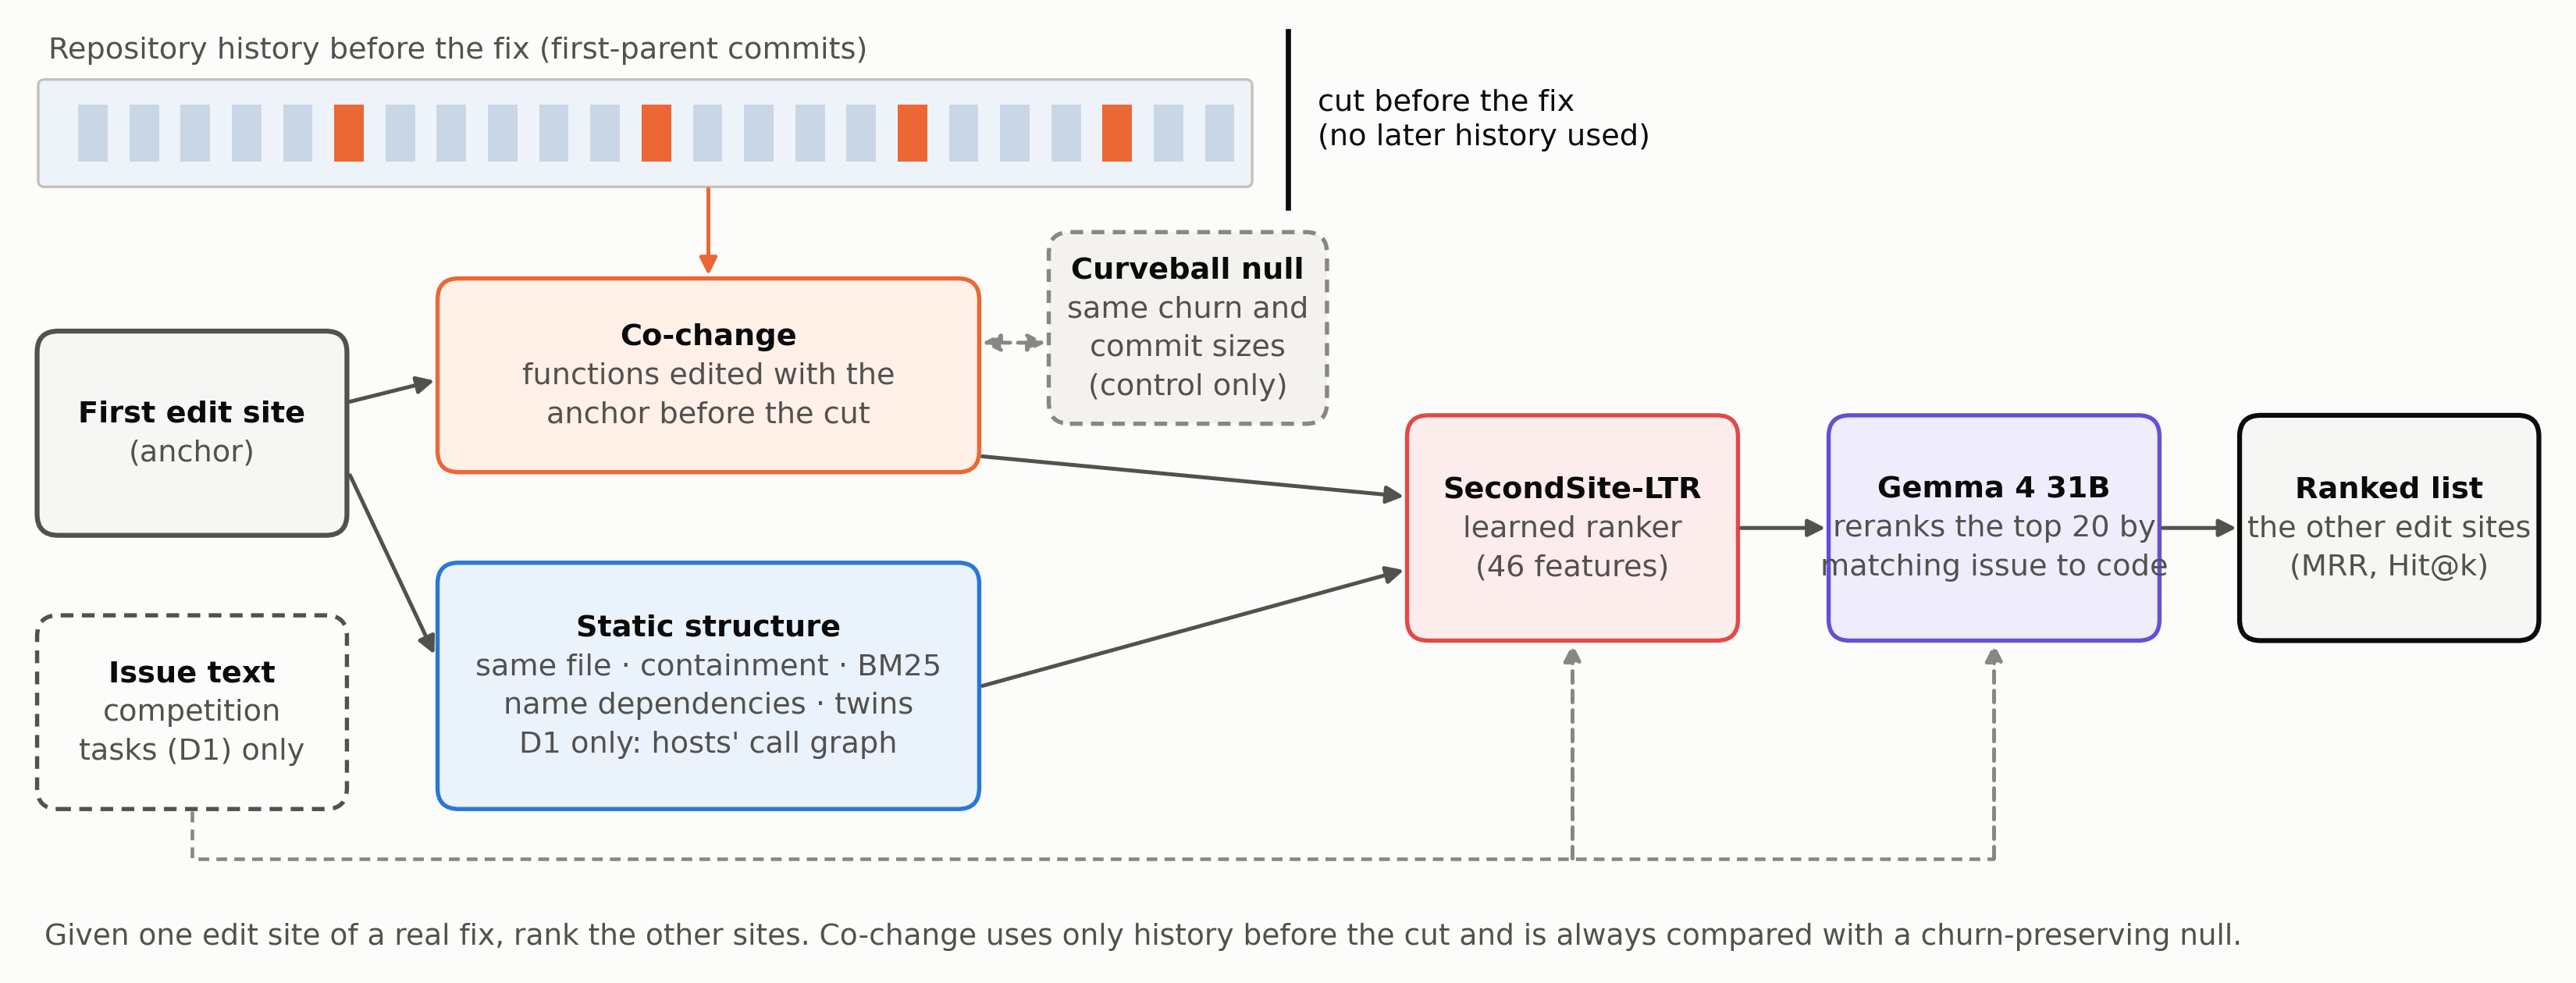

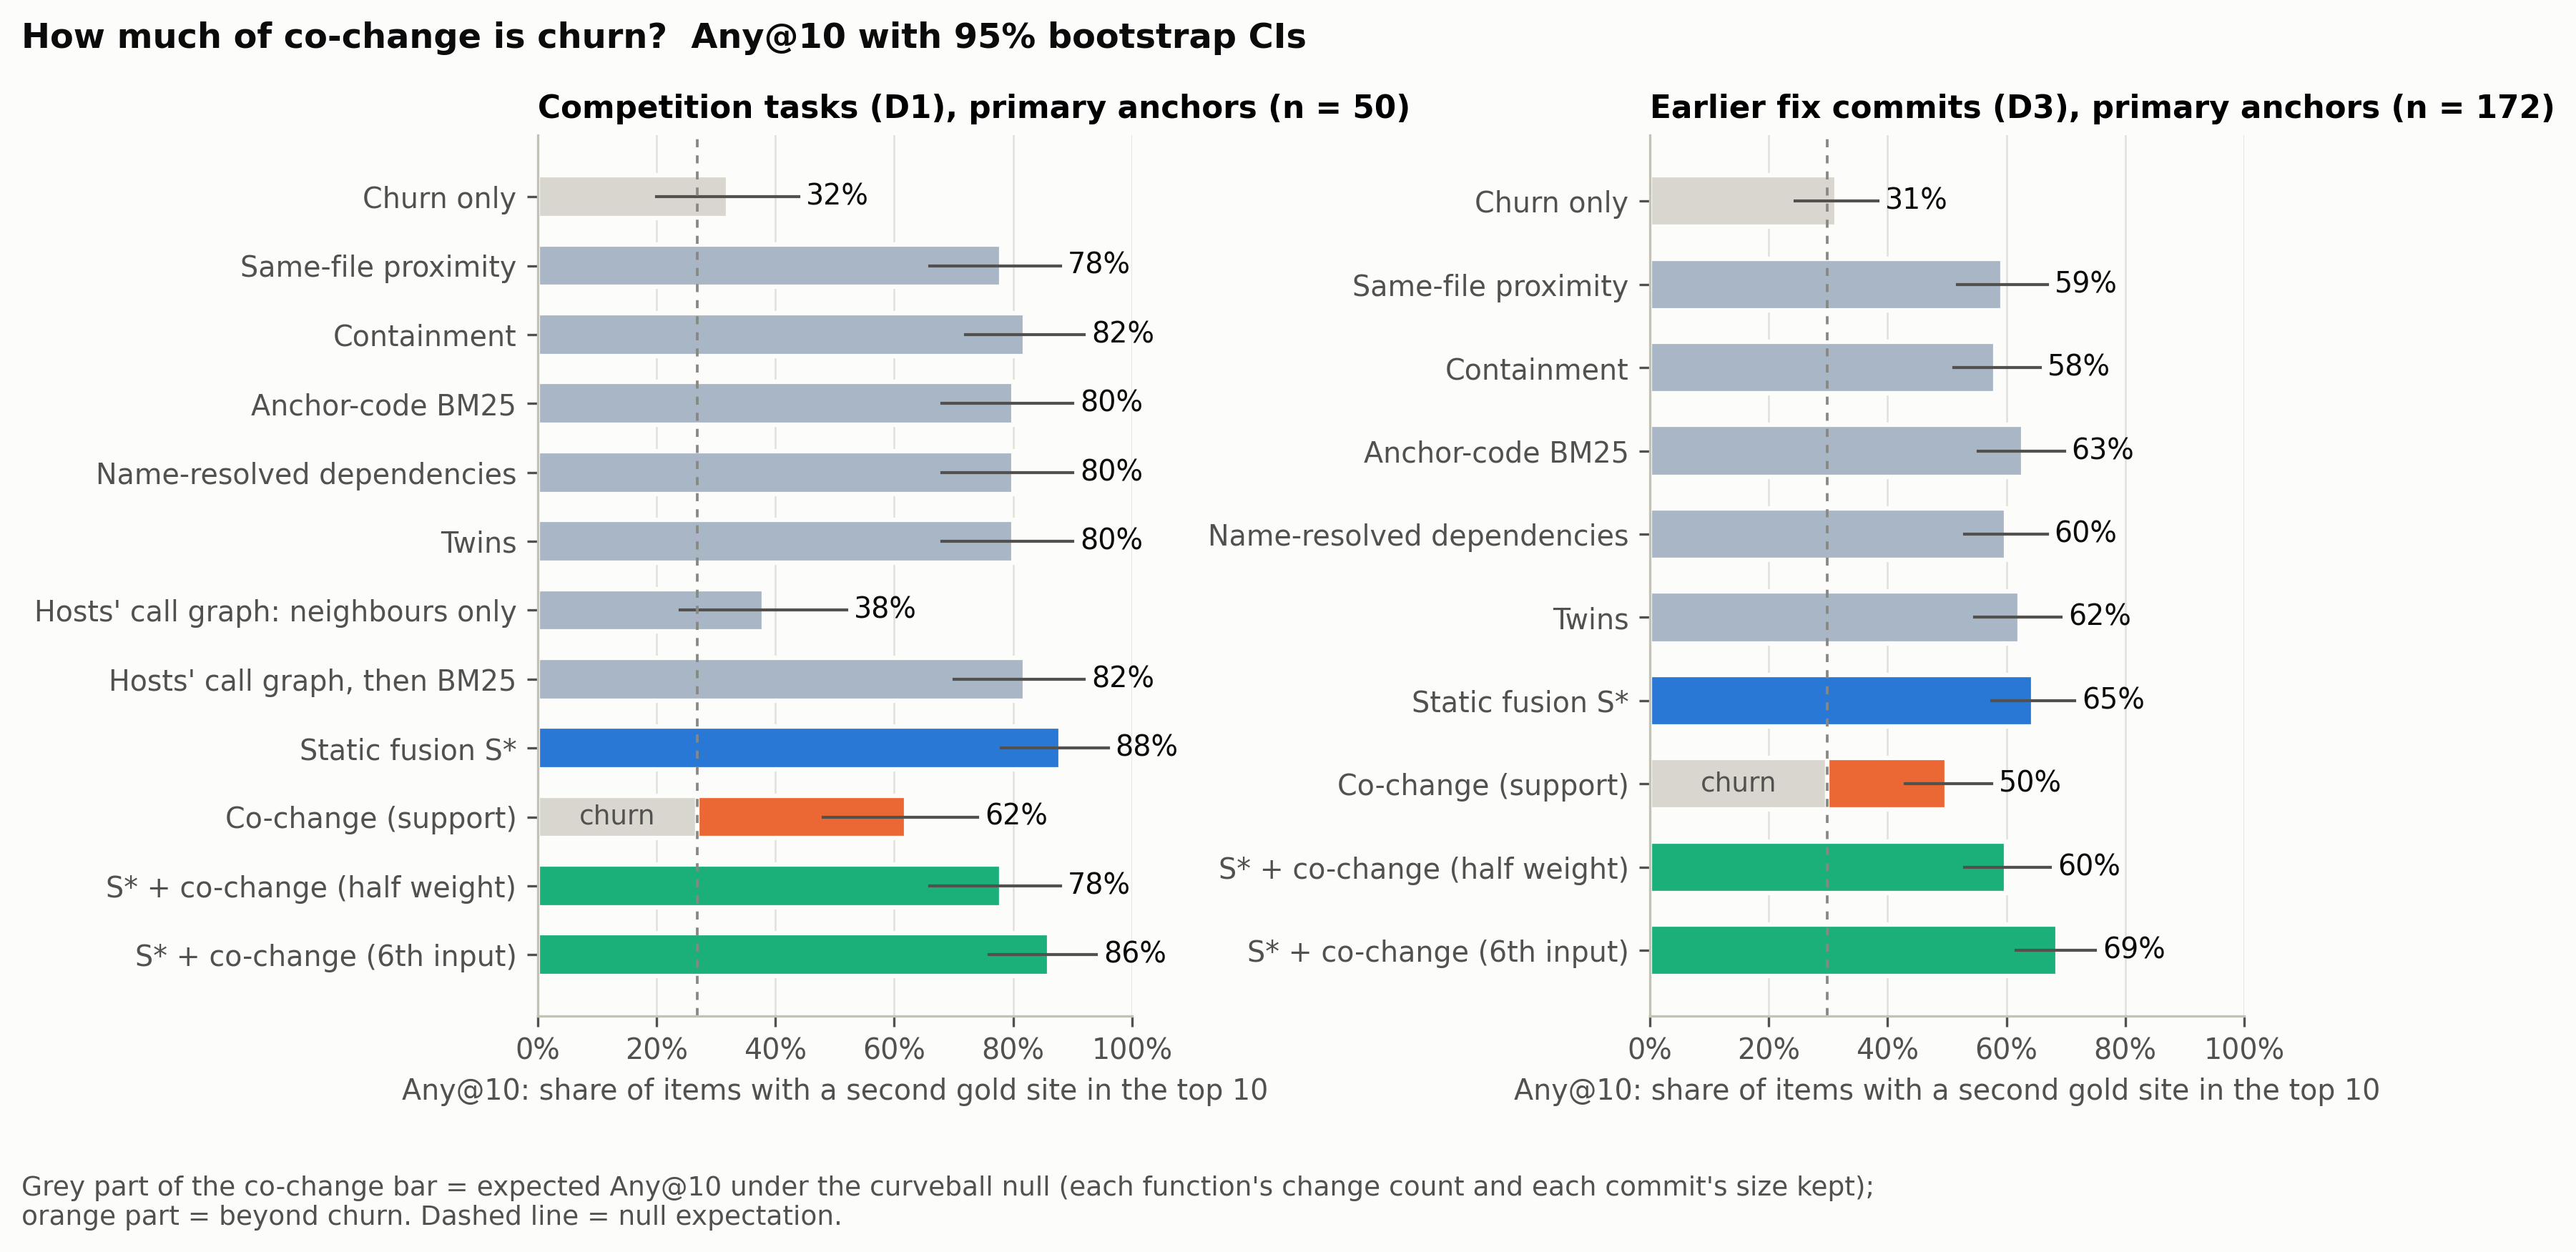

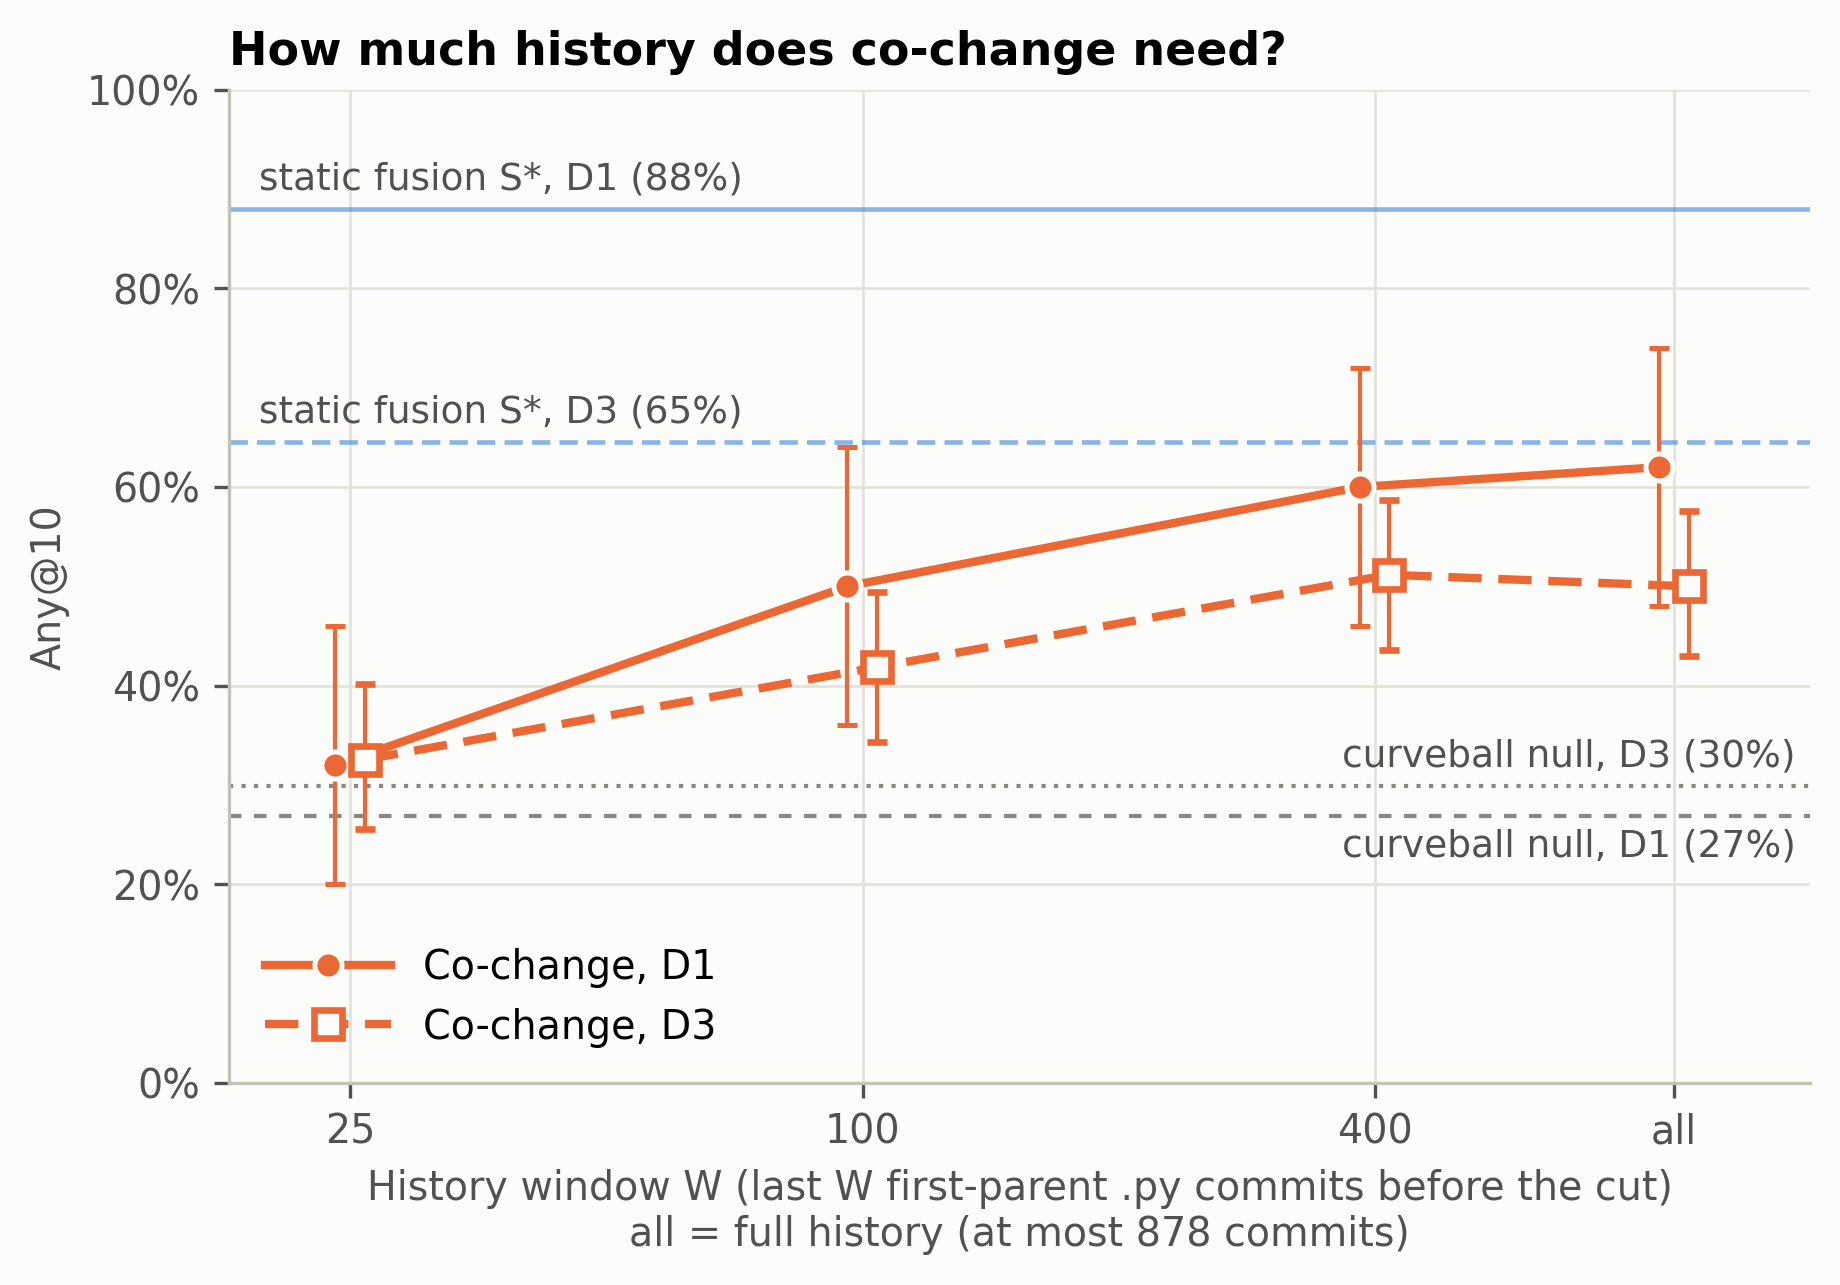

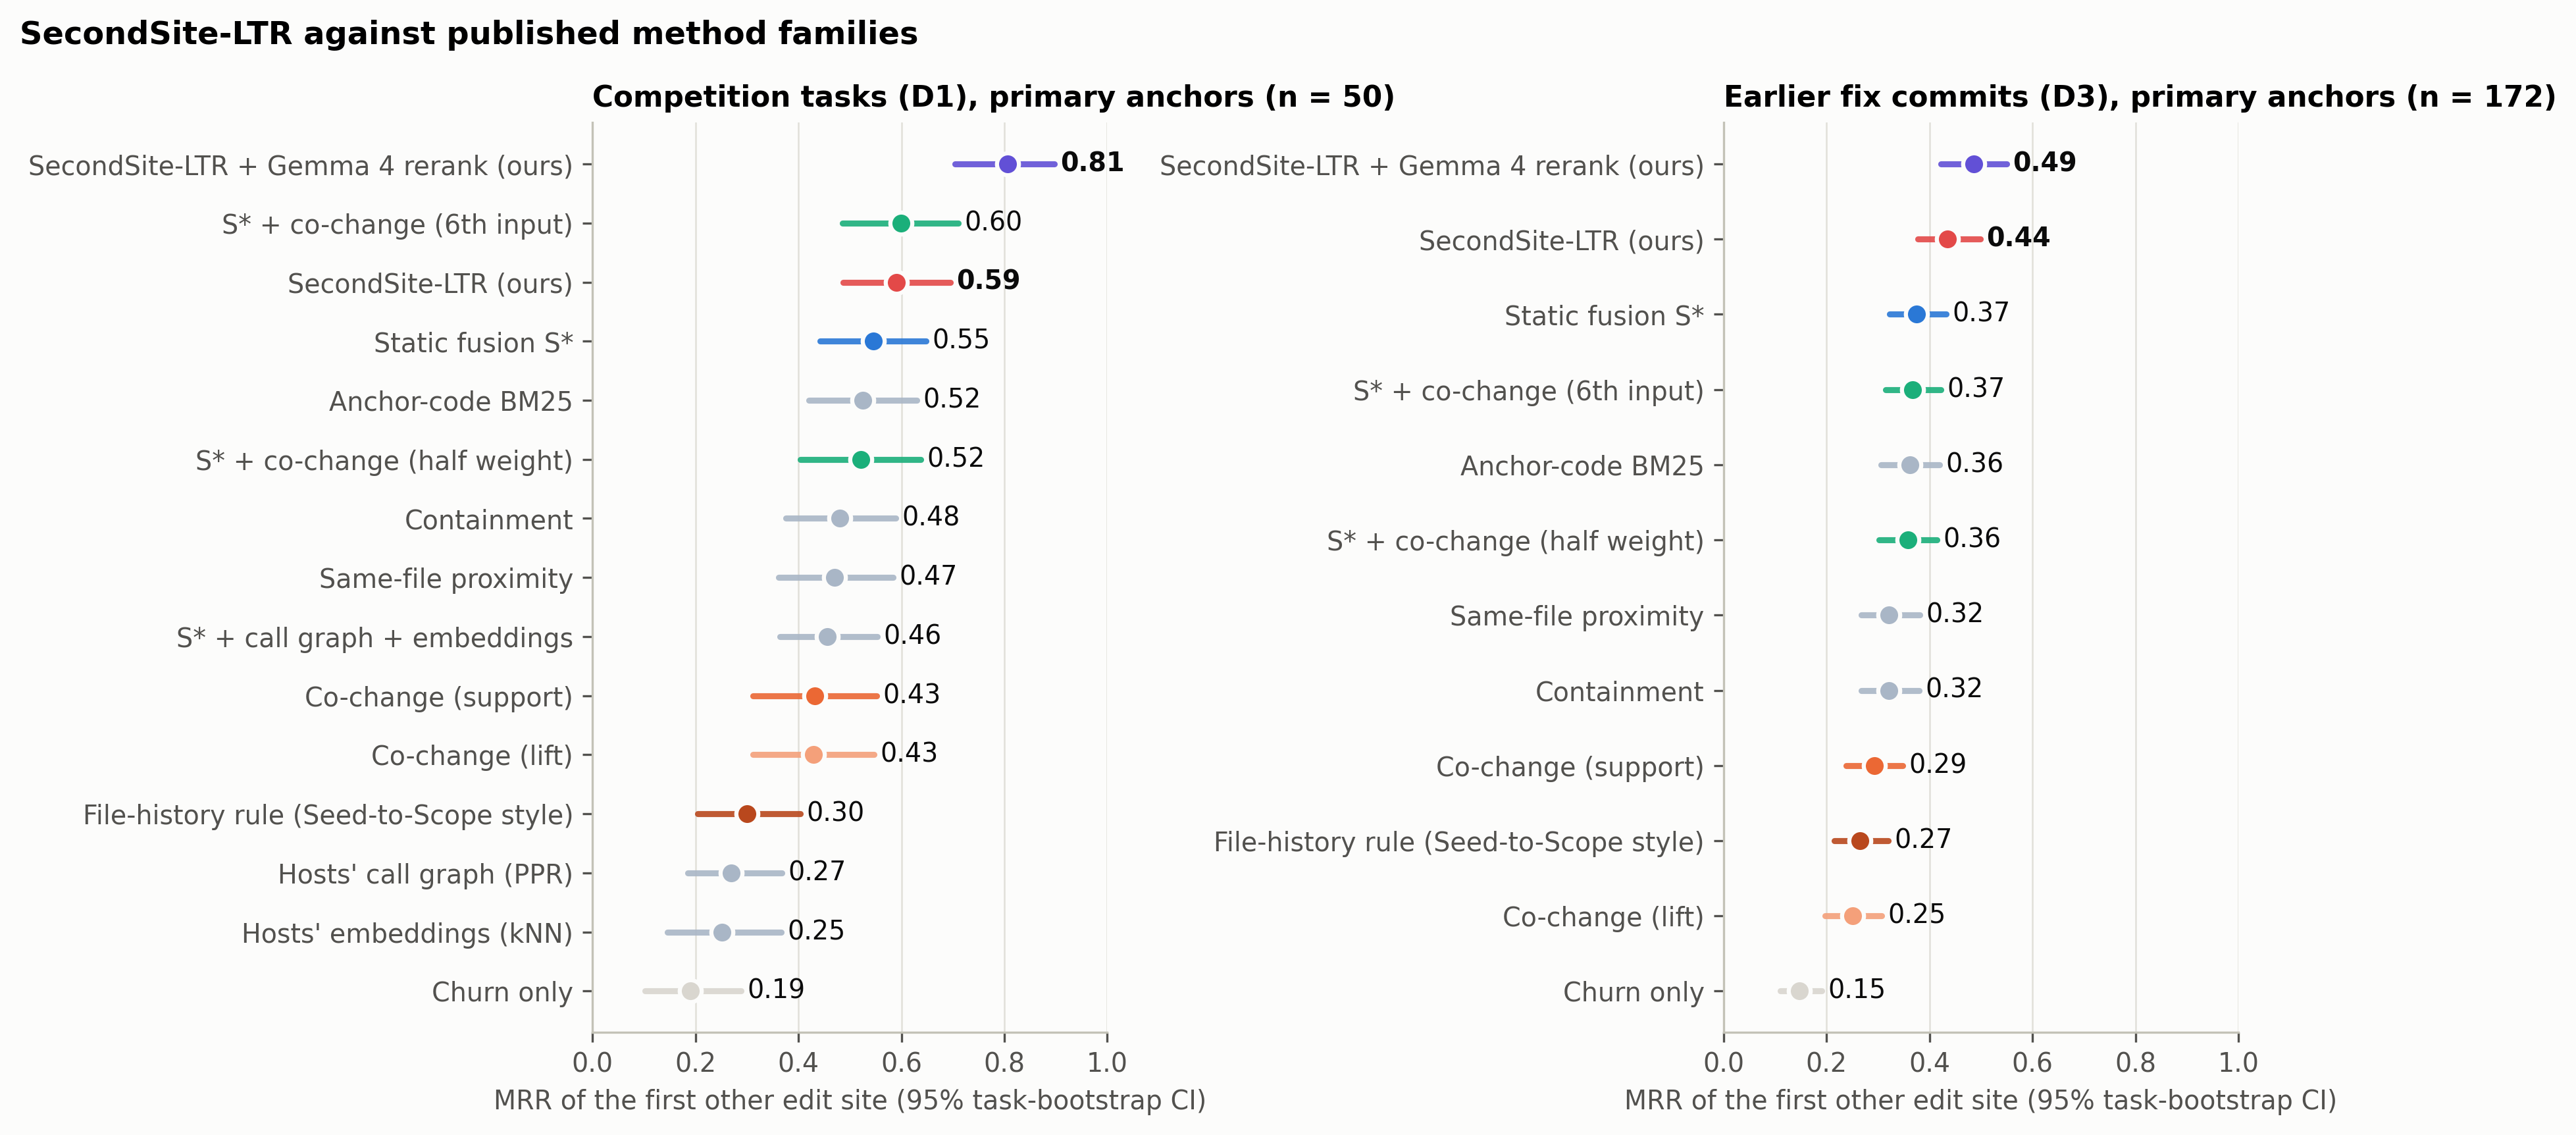

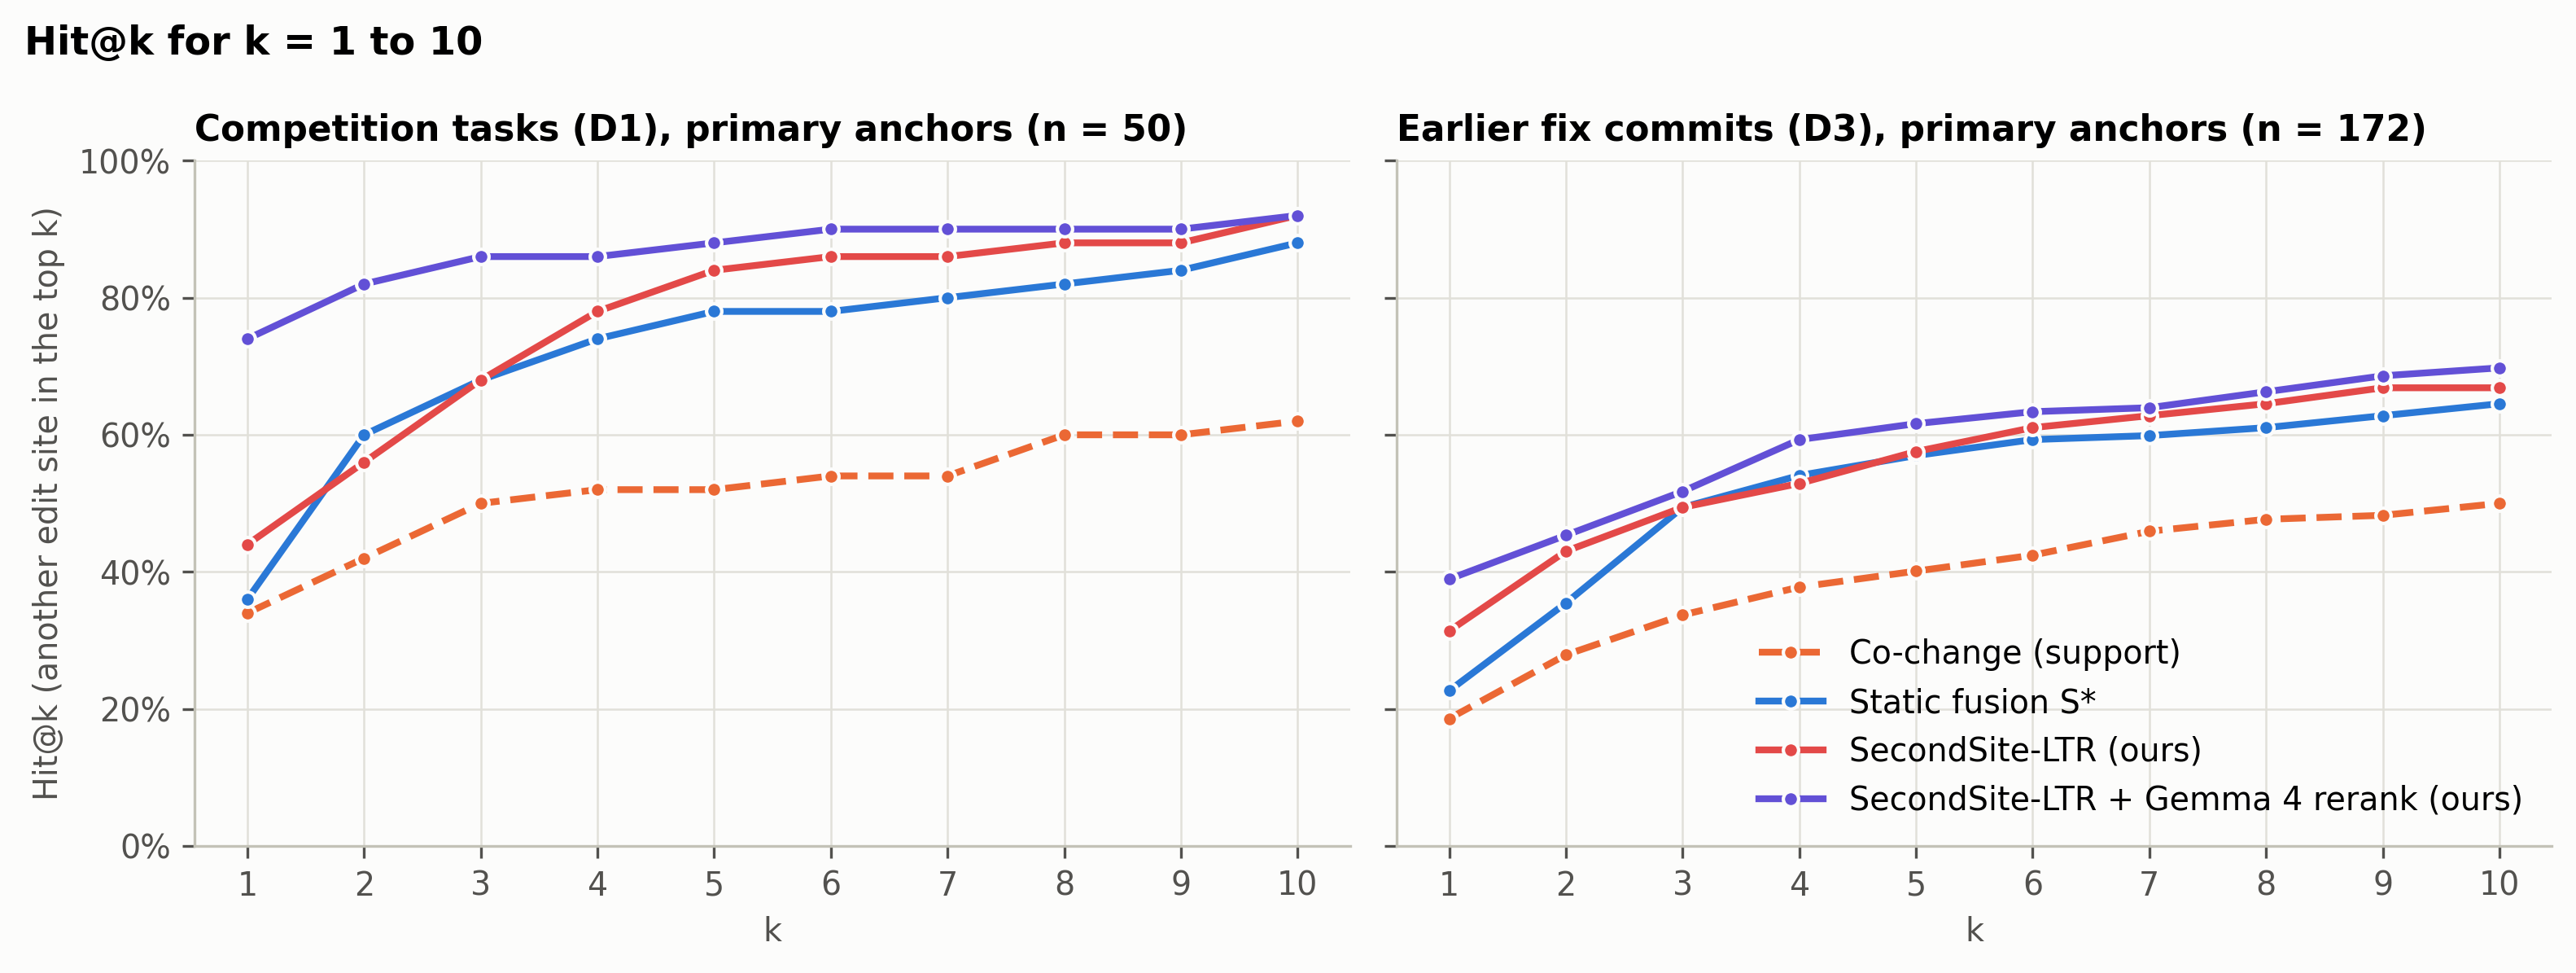

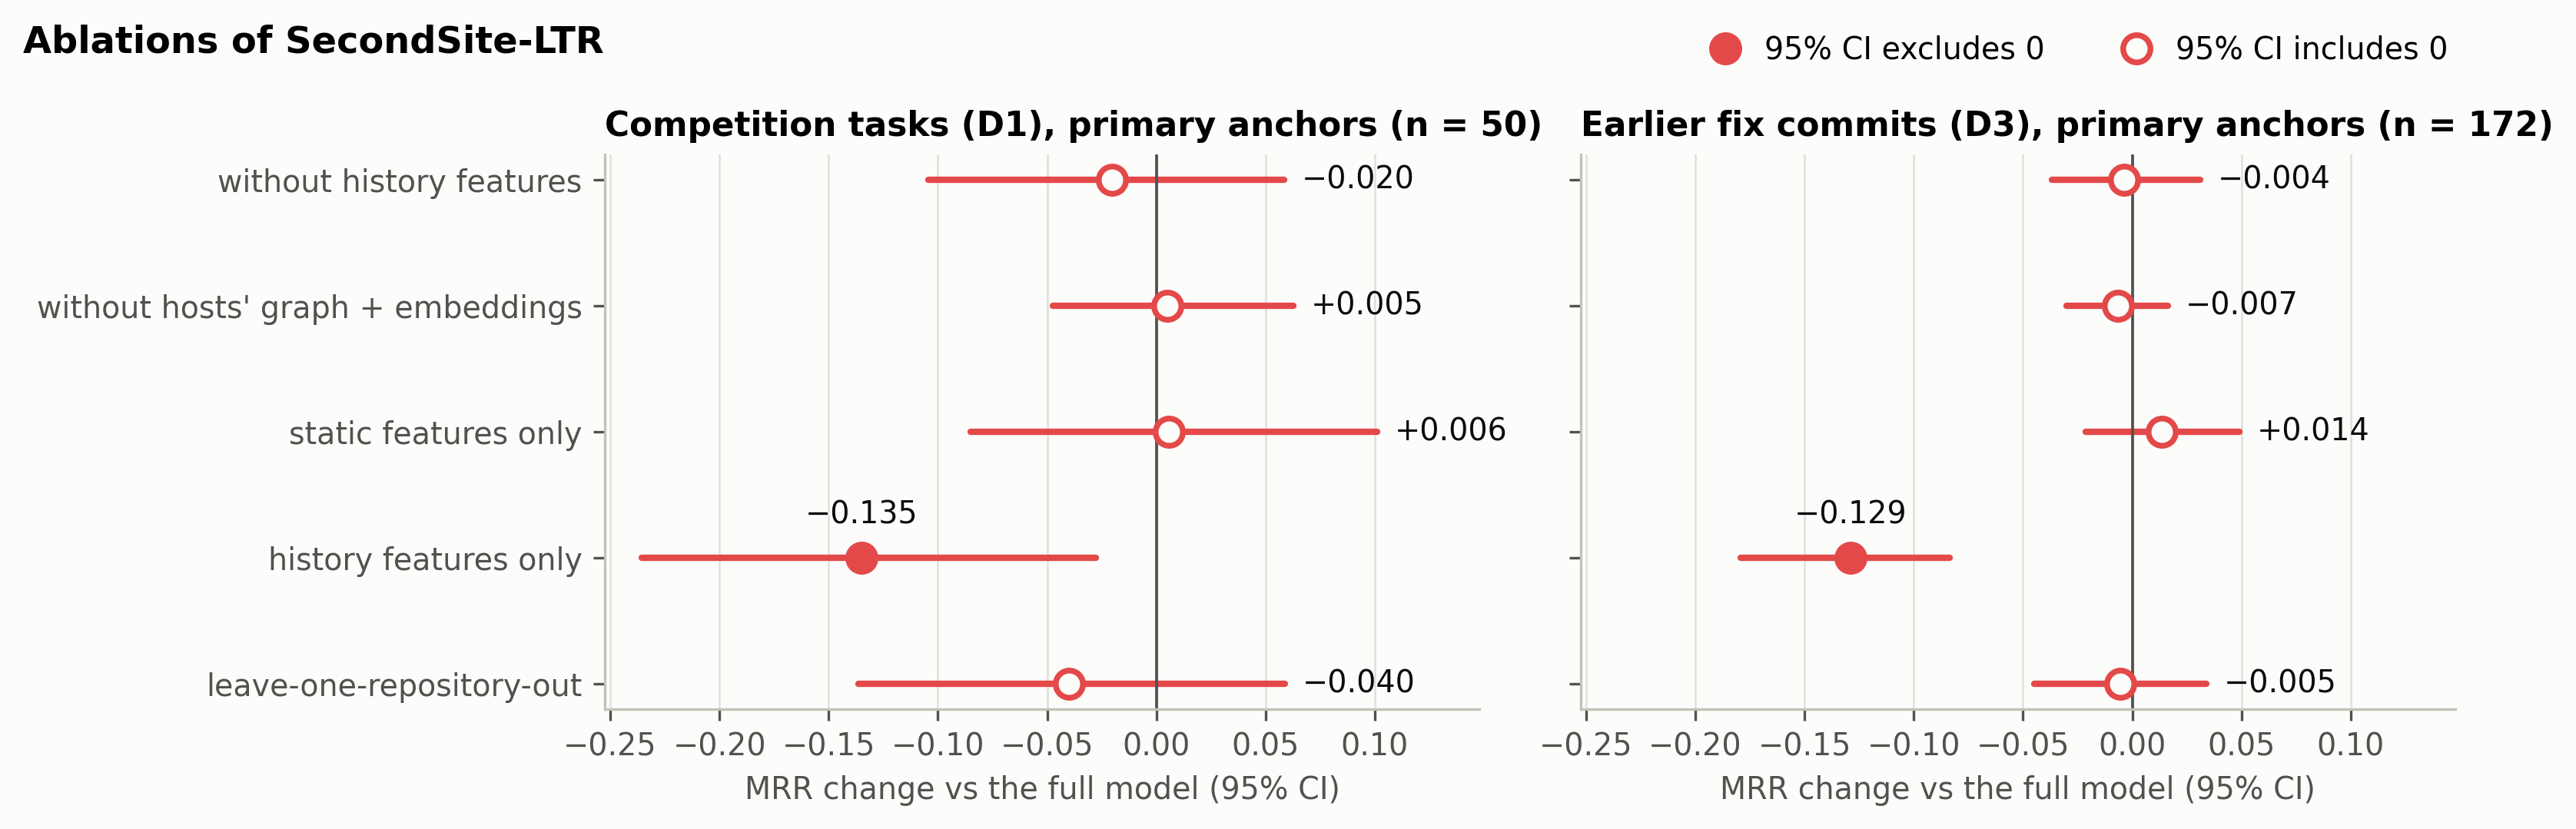

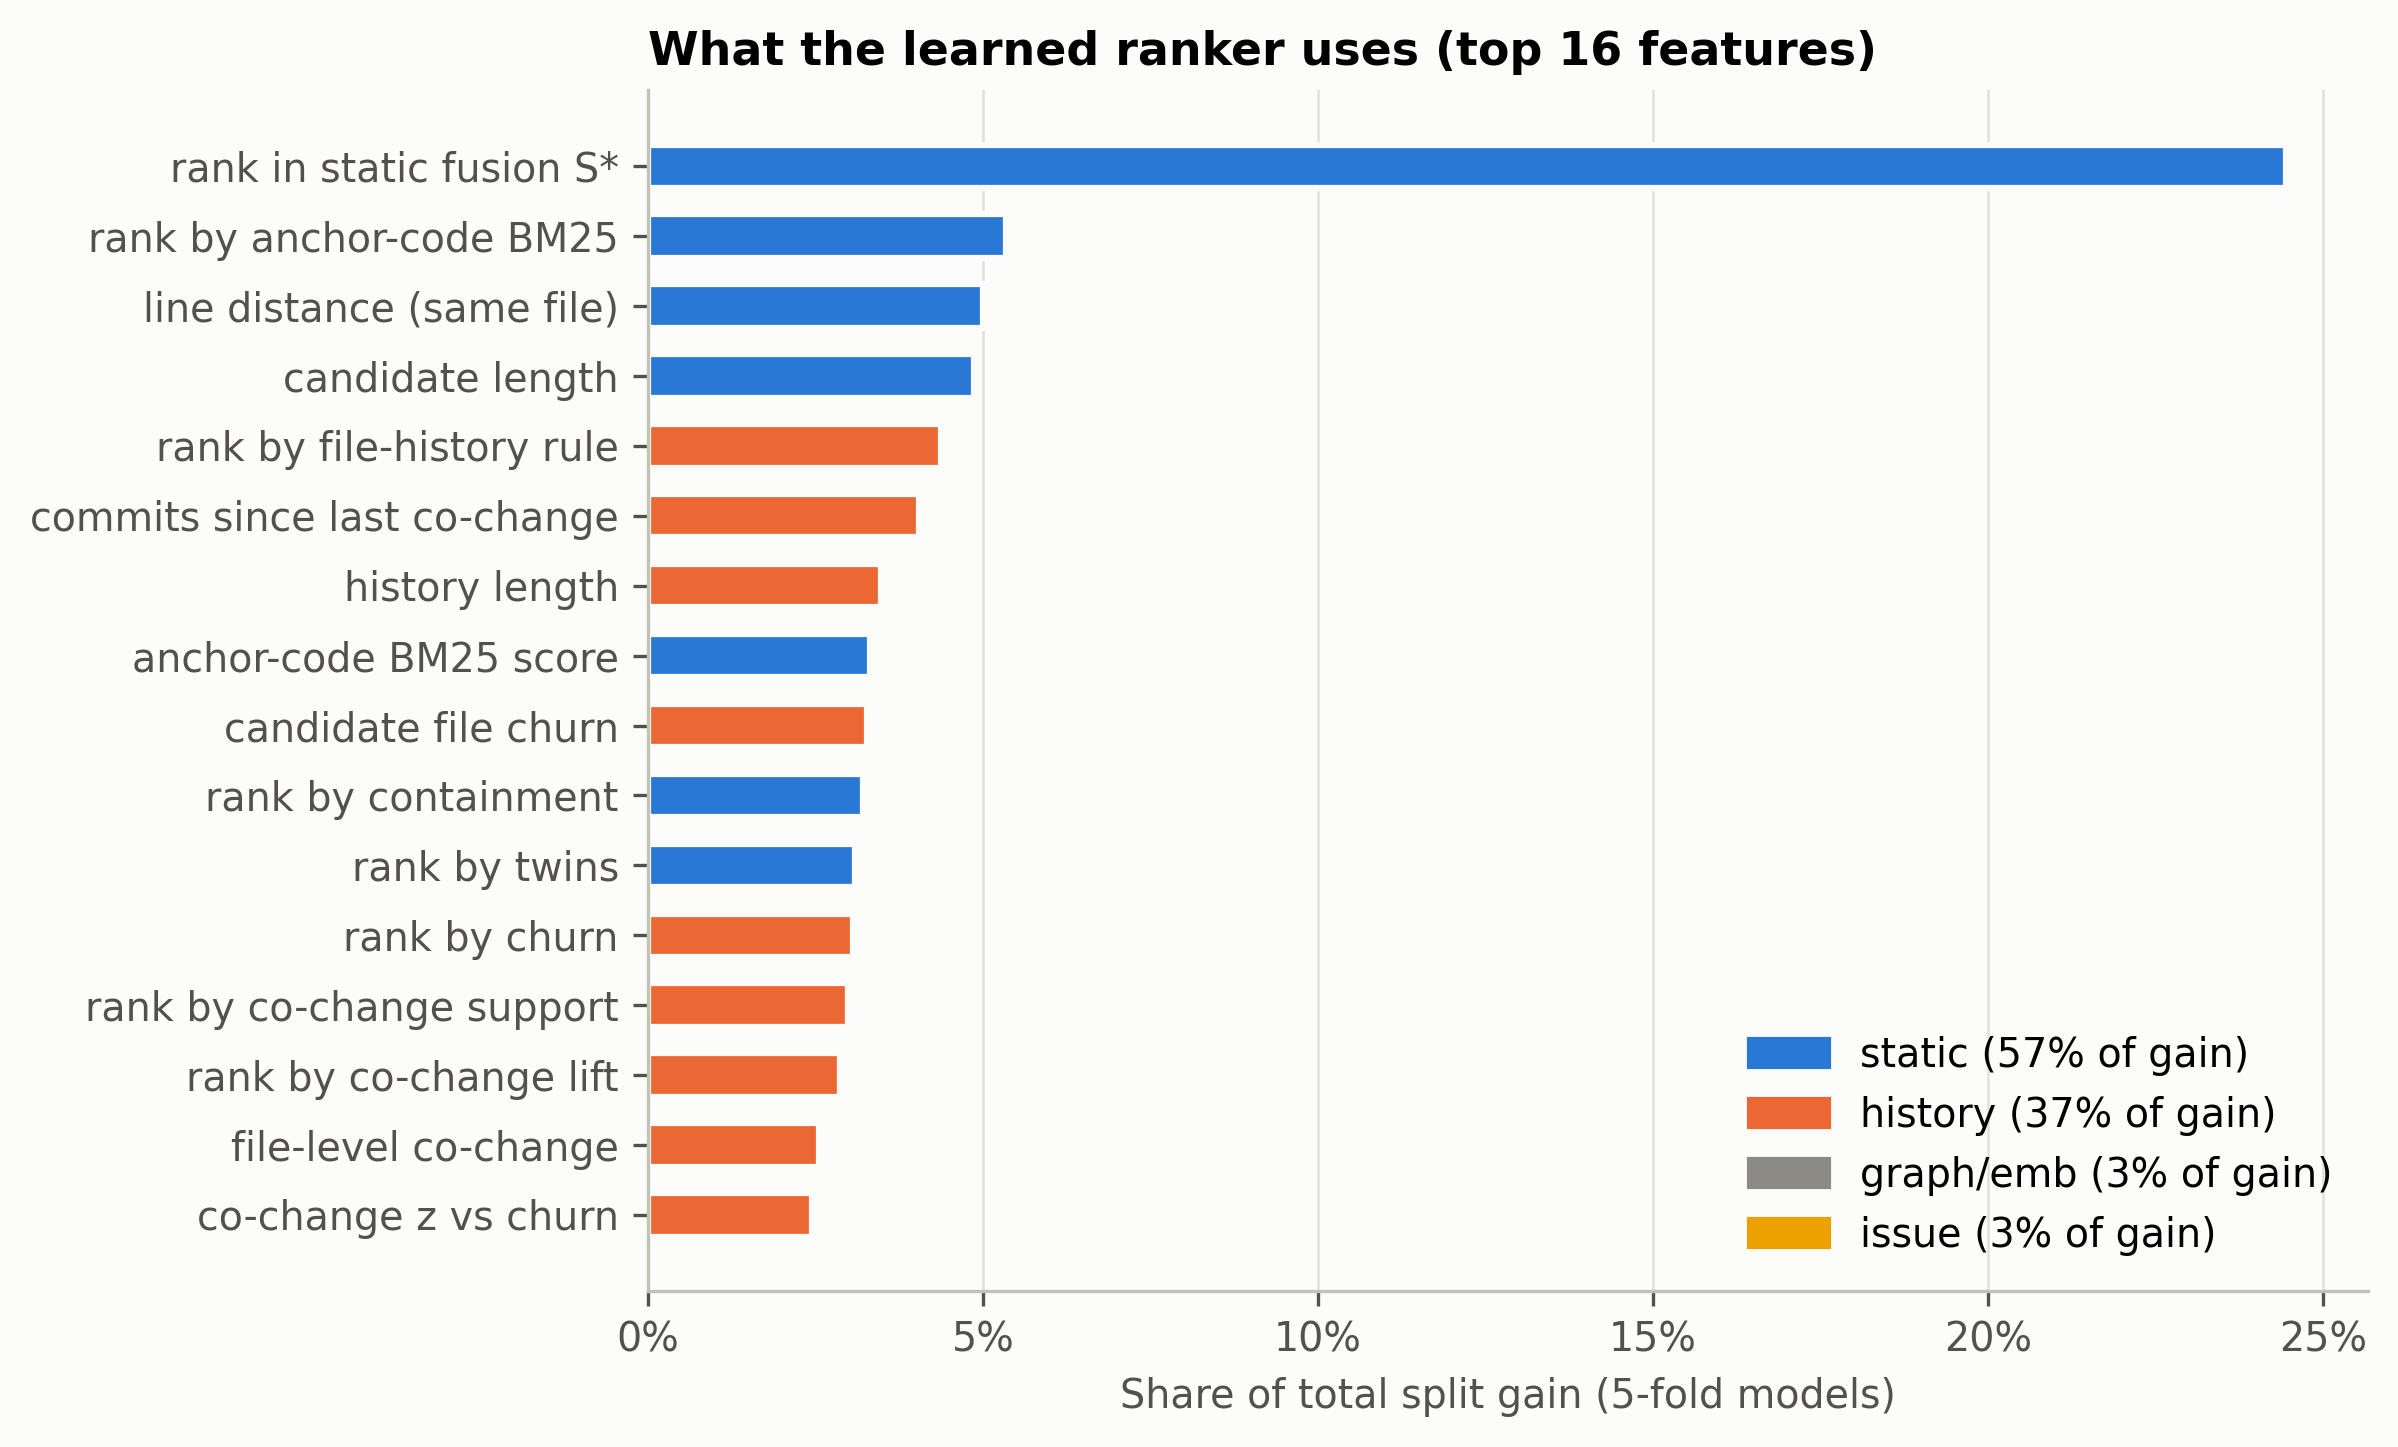

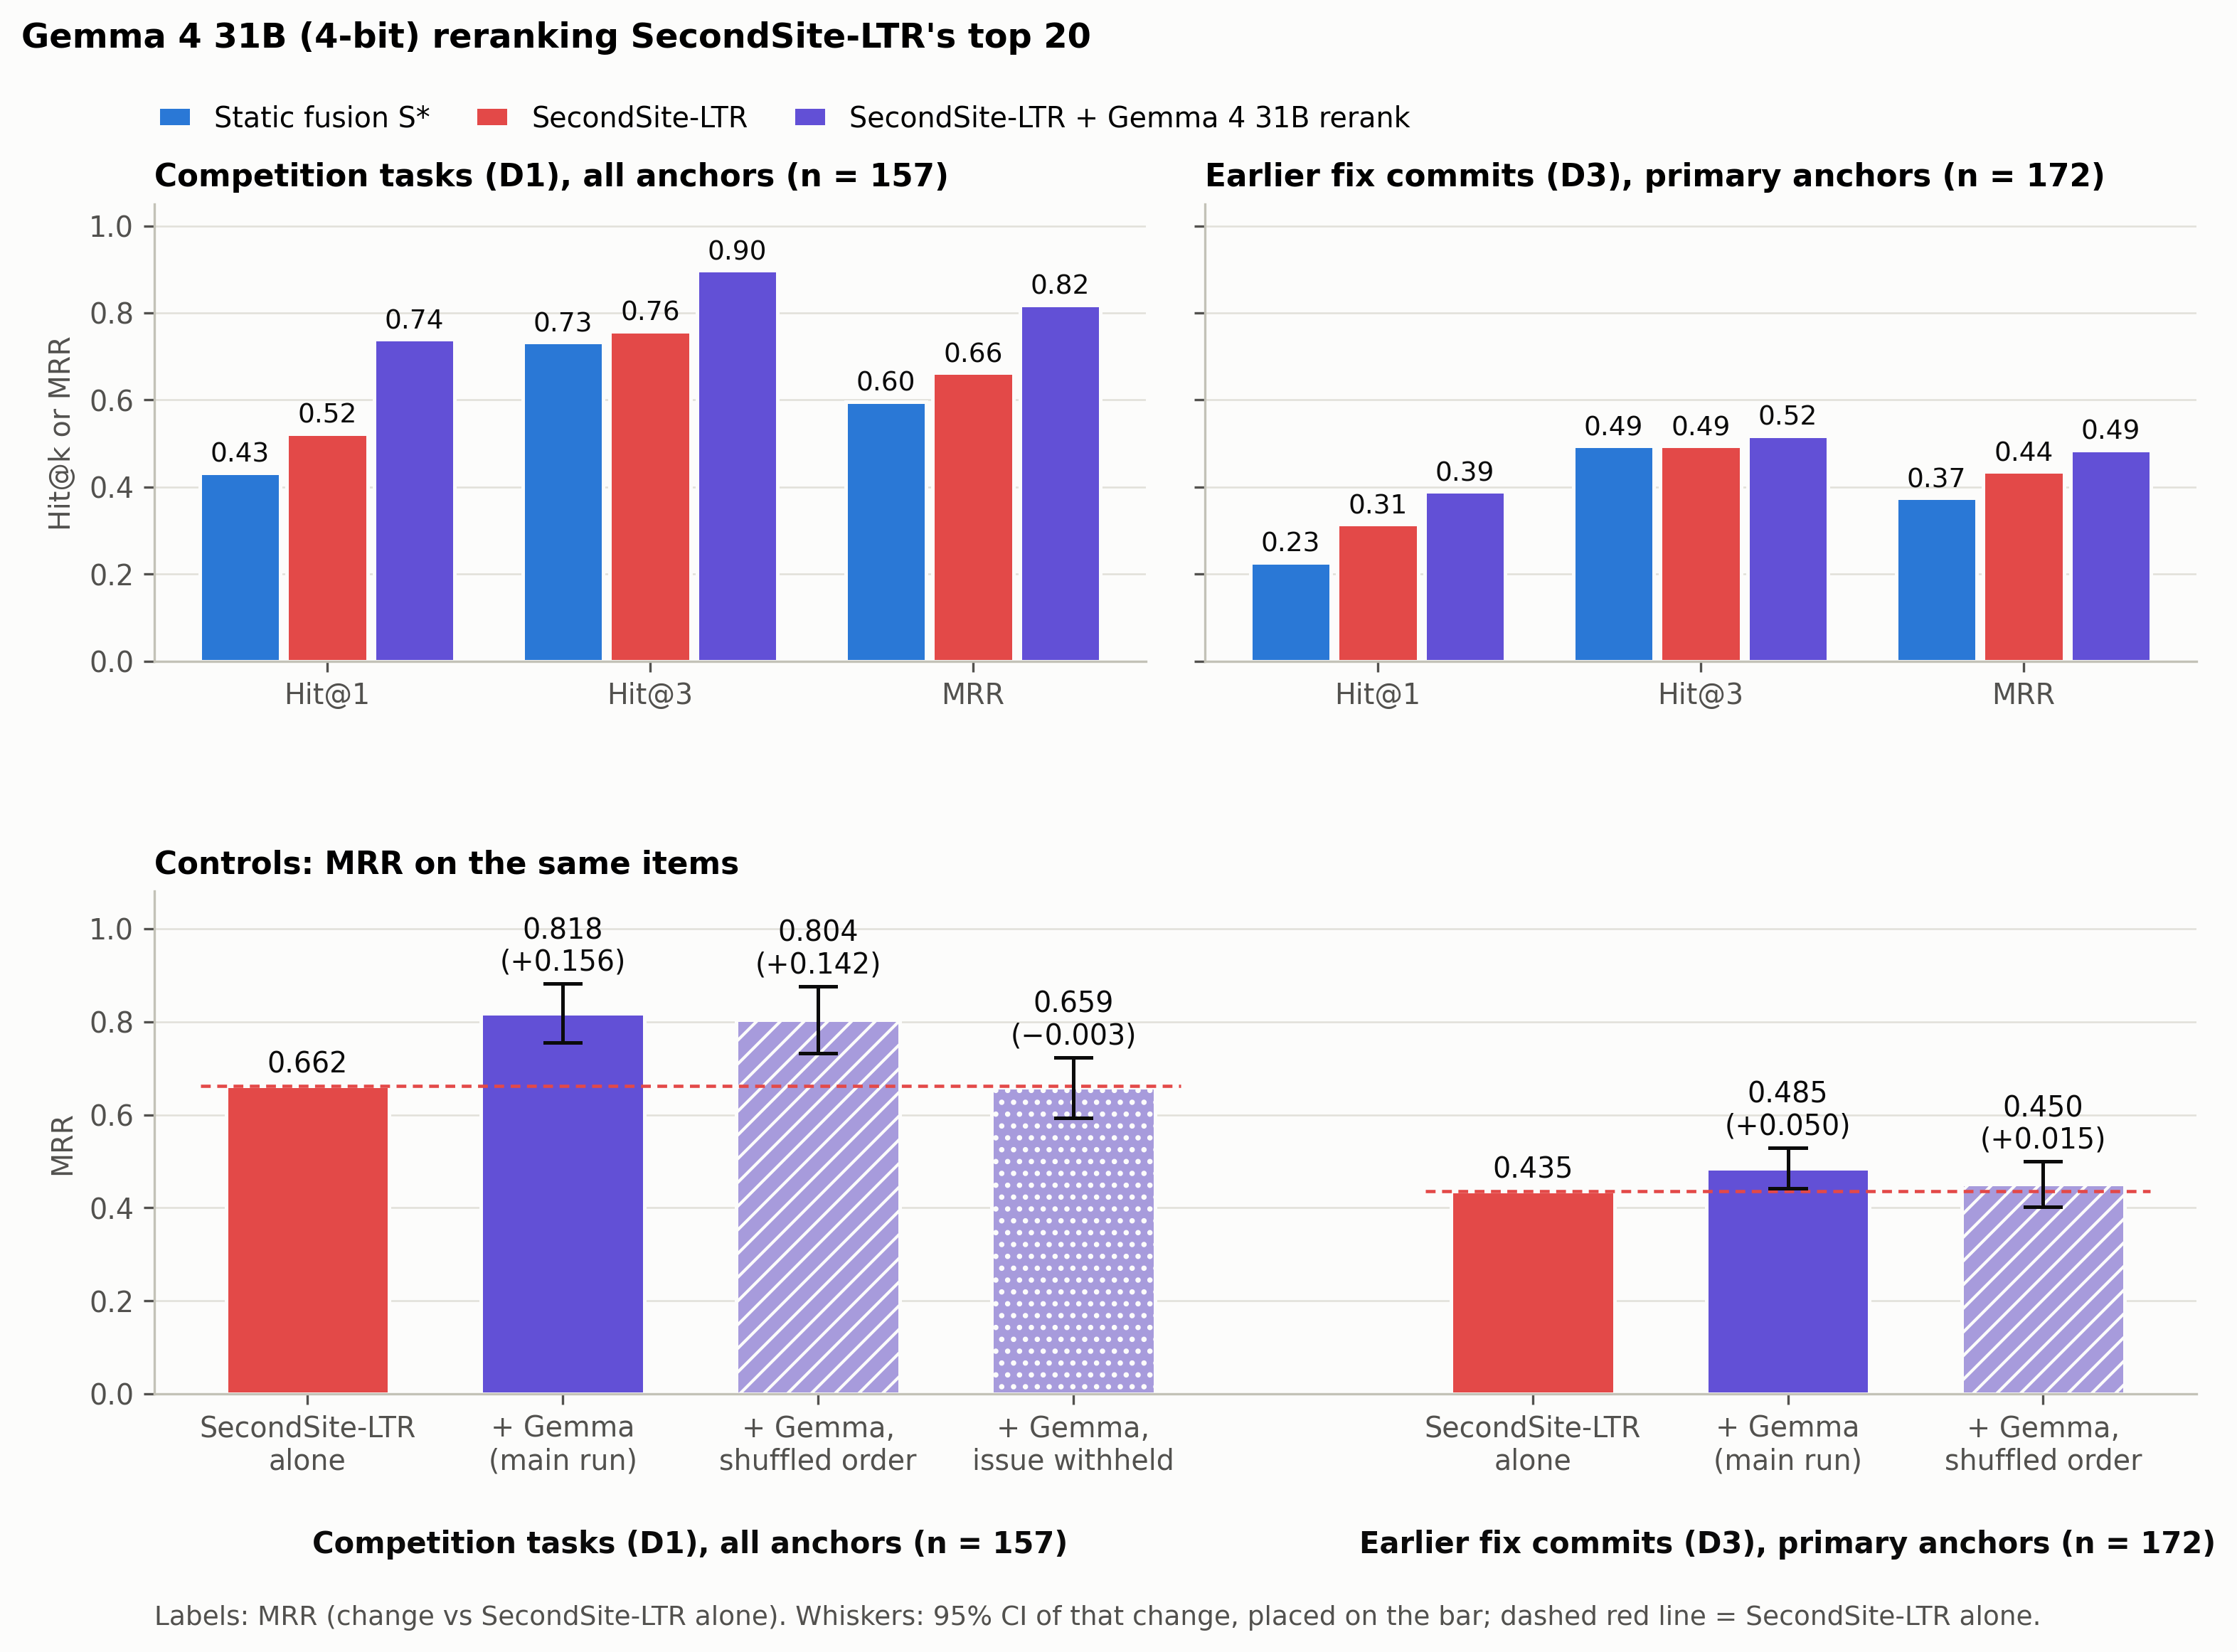

In [23]:
os.makedirs('figures', exist_ok=True); os.makedirs('results', exist_ok=True)
subprocess.run([sys.executable, 'secondsite/ss_figs.py', f'{W}/stats.json', 'figures'], check=True)
subprocess.run([sys.executable, 'secondsite/ss_figs2.py', f'{W}/ltr_scores.pkl', f'{W}/ltr_results.json', 'figures'] + RR_ARGS, check=True)
from IPython.display import Image, display
import shutil
for fn in ('stats.json', 'ltr_results.json', 'ltr_temporal.json', 'rerank_summary.json', 'rerank_contamination.json', 'rerank_controls.json', 'harness_summary.json'):
    if os.path.exists(f'{W}/{fn}'):
        shutil.copy(f'{W}/{fn}', 'results/')
for f in sorted(glob.glob('figures/*.png')):
    display(Image(f, width=900))